Version 2. Seems to work very well

# BFO ShapeNet: polarization, half-order and diagonal quarter-order

**Generate artificial structures → train analytical shape filters → freeze → analyze all 14 experimental images → compare with references.**

This notebook implements the FFT-guided extension: **153 responses**, including diagonal quarter-order filters on **both A and B sublattices**, and A-site half-order filters. It generates the corresponding structures and exact targets, trains entirely on simulated images, and then applies the frozen network throughout every experimental field.

**Run in Colab:** select a GPU runtime, then **Run all**. No separate code files or uploaded datasets are needed. The notebook downloads the original images from [Zenodo 4555979](https://doi.org/10.5281/zenodo.4555979). A complete source download is approximately 2.3 GB. Simulation and training take additional time; each stage reports progress. Enable Google Drive in Settings to preserve checkpoints across runtime resets.

Default synthetic splits: **12,000 train / 2,000 validation / 2,000 test / 1,000 stress-test** images. The optional 87-filter baseline is enabled by default. Disable it to run only the expanded network. Models resume from saved checkpoints with the same configuration. Change `VERSION` if you edit the scientific implementation, so old caches cannot be mistaken for new results.

### Training and evaluation separation

| Stage | Allowed information |
|---|---|
| Parent-cell calibration | Raw experimental image pixels and pixel-size metadata |
| Initial ordering families | Half- and diagonal quarter-order priors supported by the preceding raw-image FFT diagnostic |
| Training, normalization, early stopping, detection thresholds | Generated structures and synthetic labels only |
| Experimental inference | Raw image pixels; image-derived cell positions and local bases |
| Final comparison | Deposited displacement/coordinate arrays, first opened after **all** predictions are saved and sealed |

Reference measurements do not enter training or model selection. The final experimental comparison is a transfer diagnostic; the same material family informed the raw-image priors, so it is not a claim of a completely unseen material.

**Implementation validation:** reduced synthetic training and experimental-data smoke tests were run successfully. This delivered notebook has clean outputs and the full configuration for your run; it does not contain fabricated full-training results.

## Update: FFT coverage audit and polarization observability
The 153 learnable analytical filters are unchanged in count. This revision verifies their presence and **actual** frequency response before and after training. It does not assert that they cover every detected mode. It reports uncovered candidates explicitly. All audit input comes from raw HAADF images; deposited reference arrays are still opened only after predictions are sealed.

Uniform polarization is an intra-cell relative displacement: it can change parent structure factors but need not create a new FFT satellite. Therefore polarization has a separate real-space derivative/rank test. Ordering is tested using observed satellite frequencies G ± q and A/B displacement templates, not FFT peaks in polarization maps.

The default sampling frame is now the shared parent lattice. Per-cell affine rectification can deform the very alternating A-site geometry being measured; synthetic generation and experimental inference now use the same parent-frame convention. Retraining is required; old cached models are not reused.


In [ ]:
#@title 1. Install missing dependencies and initialize the runtime
import importlib.util, subprocess, sys
_needed = {'numpy':'numpy', 'scipy':'scipy', 'pandas':'pandas', 'matplotlib':'matplotlib',
           'h5py':'h5py', 'requests':'requests', 'torch':'torch', 'tqdm':'tqdm'}
_missing = [package for module,package in _needed.items() if importlib.util.find_spec(module) is None]
if _missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *_missing])
import os, re, gc, io, json, time, math, copy, random, hashlib, shutil, zipfile, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import pandas as pd
import requests, h5py, scipy, matplotlib
import scipy.ndimage as ndi
from scipy.spatial import cKDTree
from scipy.linalg import solve
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import torch
from torch import nn
from tqdm.auto import tqdm
from IPython.display import display, Image, FileLink
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, os.cpu_count() or 1))
if DEVICE.type == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = False
print('Device:', DEVICE, '| PyTorch:', torch.__version__)
if DEVICE.type == 'cpu':
    print('CPU mode works. A Colab GPU is recommended for full-field extraction and training.')
plt.rcParams.update({'figure.facecolor':'white', 'font.size':10})

from torch.nn import functional as F
from scipy.optimize import linear_sum_assignment


Device: cuda | PyTorch: 2.14.1+cu130


## 1. Settings and reproducible source access

The lattice range defaults to the image-estimated parent spacing divided/multiplied by 1.5. Set the factor to 3 for a broader range. Input neighborhoods retain **12 canonical pixels per parent cell**; varying native spacings changes image sampling and blur before registration.

The 120×120 input includes a 9×9-cell ordering neighborhood and a margin. The original local filter families still focus on five cells. The simulator includes additional outer columns so the input support is not artificially cut off.

Raw images are downloaded first. The parameter-file names/checksums are metadata at this stage; their numerical contents are not accessed until final evaluation. Downloads support resumption and checksum verification.

In [ ]:
#@title 2. Configuration: full experiment by default
USE_GOOGLE_DRIVE = False #@param {type:'boolean'}
DRIVE_FOLDER = 'BFO_Quarter_Order_ShapeNet' #@param {type:'string'}
LATTICE_RANGE_FACTOR = 1.5 #@param [1.25,1.5,2.0,3.0] {type:'raw'}
N_TRAIN = 12000 #@param {type:'integer'}
N_VALIDATION = 2000 #@param {type:'integer'}
N_TEST = 2000 #@param {type:'integer'}
N_STRESS = 1000 #@param {type:'integer'}
MAX_EPOCHS = 40 #@param {type:'integer'}
PATIENCE = 8 #@param {type:'integer'}
BATCH_SIZE = 128 #@param {type:'integer'}
INFERENCE_BATCH_SIZE = 128 #@param {type:'integer'}
LEARNING_RATE = 0.001 #@param {type:'number'}
TRAIN_87_BASELINE = True #@param {type:'boolean'}
DISPLAY_ALL_IMAGES = True #@param {type:'boolean'}
INCLUDE_SYNTHETIC_PIXELS_IN_ZIP = False #@param {type:'boolean'}
QUARTER_Q_JITTER = 0.03 #@param {type:'number'}
SEED = 2026 #@param {type:'integer'}
FFT_BASIS_OVERRIDES = {} # Raw-image/FFT inspection only; no reference-label fitting.
SIZE=120;PPC=12.;EXPECTED_PAIR_COUNT=14;ZENODO_RECORD_ID=4555979
VERSION='synthetic_quarter_order_v4_fft_audit'
REGISTRATION_MODE='global_parent'
STRICT_FFT_COVERAGE=False # If True, stop before training/inference when the declared audit fails.
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT=Path('/content/drive/MyDrive')/DRIVE_FOLDER
else:PROJECT_ROOT=Path(os.environ.get('BFO_QUARTER_ROOT','/content/BFO_Quarter_Order_ShapeNet'))
RAW_DIR=Path(os.environ.get('BFO_QUARTER_RAW','/content/BFO_Quarter_Raw'))
PROJECT_ROOT.mkdir(parents=True,exist_ok=True);RAW_DIR.mkdir(parents=True,exist_ok=True)
for name in ['calibration','synthetic','models','predictions','evaluation','figures','coverage_audit']:(PROJECT_ROOT/name).mkdir(exist_ok=True)
AUDIT=[]
print('Model training, validation, selection: SIMULATED DATA ONLY. FFT audit thresholds are declared diagnostics, not fitted to reference labels.')
print('Experimental references are opened only after all model predictions are sealed.')
print('153-response bank; 46 outputs; 5-cell local + 9-cell ordering context.')
print('Output folder:',PROJECT_ROOT)


Model training, validation, selection: SIMULATED DATA ONLY. FFT audit thresholds are declared diagnostics, not fitted to reference labels.
Experimental references are opened only after all model predictions are sealed.
153-response bank; 46 outputs; 5-cell local + 9-cell ordering context.
Output folder: /content/BFO_Quarter_Order_ShapeNet


In [ ]:
#@title 3. Reproducible I/O and resumable, checksum-verified downloads

def jsonable(x):
    if isinstance(x, dict): return {str(k):jsonable(v) for k,v in x.items()}
    if isinstance(x, (list,tuple)): return [jsonable(v) for v in x]
    if isinstance(x, np.ndarray): return jsonable(x.tolist())
    if isinstance(x, np.generic): return jsonable(x.item())
    if isinstance(x, float) and not np.isfinite(x): return None
    if isinstance(x, Path): return str(x)
    return x

def atomic_json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name+'.tmp')
    tmp.write_text(json.dumps(jsonable(value), indent=2, allow_nan=False))
    tmp.replace(path)

def atomic_npz(path, **values):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.stem+'.tmp.npz')
    np.savez_compressed(tmp, **values); tmp.replace(path)

def atomic_torch(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name+'.tmp'); torch.save(value, tmp); tmp.replace(path)

def save_figure(fig, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.stem+'.tmp'+path.suffix)
    fig.savefig(tmp, dpi=150, bbox_inches='tight'); tmp.replace(path)

def file_hash(path, algorithm='md5'):
    h = hashlib.new(algorithm)
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(4*1024**2), b''): h.update(block)
    return h.hexdigest()

def digest(value):
    return hashlib.sha256(json.dumps(jsonable(value), sort_keys=True).encode()).hexdigest()[:16]

def request_json(url):
    for attempt in range(6):
        try:
            r = requests.get(url, timeout=(30,90))
            if r.status_code == 429:
                time.sleep(min(60, int(r.headers.get('Retry-After',30)))); continue
            r.raise_for_status(); return r.json()
        except requests.RequestException:
            if attempt == 5: raise
            time.sleep(min(30, 2**attempt))
    raise RuntimeError('Repeated rate limiting while reading '+url)

def discover_pairs(record):
    pat = re.compile(r'^sm_(\d+)_(\d+)_(haadf|ucparameterization)\.h5$', re.I)
    pairs = {}
    for f in record['files']:
        name = f.get('key', f.get('filename','')); match = pat.match(name)
        if not match: continue
        comp,rep,kind = match.groups(); key=(int(comp),int(rep))
        p = pairs.setdefault(key, {'id':f'Sm_{key[0]}_{key[1]}','composition':key[0],'replicate':key[1]})
        links = f.get('links',{})
        p['image' if kind.lower()=='haadf' else 'parameters'] = {
            'name':name, 'size':int(f['size']), 'checksum':f['checksum'],
            'url':links.get('content') or links.get('download') or links.get('self')}
    out = [p for _,p in sorted(pairs.items()) if 'image' in p and 'parameters' in p]
    if len(out) != EXPECTED_PAIR_COUNT:
        raise RuntimeError(f'Expected {EXPECTED_PAIR_COUNT} complete pairs, discovered {len(out)}. Inspect the record rather than silently skipping data.')
    return out

def download_file(meta):
    path = RAW_DIR/meta['name']; part=path.with_name(path.name+'.part')
    receipt=path.with_name(path.name+'.verified.json')
    expected=meta['checksum'].removeprefix('md5:')
    if not meta['checksum'].startswith('md5:'): raise ValueError('Unsupported source checksum')
    if path.exists() and path.stat().st_size==meta['size']:
        if receipt.exists():
            old=json.loads(receipt.read_text())
            if old.get('md5')==expected and old.get('mtime_ns')==path.stat().st_mtime_ns: return path
        if file_hash(path)==expected:
            atomic_json(receipt, {'md5':expected,'mtime_ns':path.stat().st_mtime_ns}); return path
        path.unlink()  # Corrupt local download only; source and user files are untouched.
    for attempt in range(6):
        try:
            if part.exists() and part.stat().st_size==meta['size']:
                if file_hash(part)==expected:
                    part.replace(path)
                    atomic_json(receipt, {'md5':expected,'mtime_ns':path.stat().st_mtime_ns}); return path
                part.unlink()
            start=part.stat().st_size if part.exists() else 0
            if start>meta['size']: part.unlink(); start=0
            headers={'Range':f'bytes={start}-'} if start else {}
            with requests.get(meta['url'], headers=headers, stream=True, timeout=(30,180)) as r:
                if r.status_code==429:
                    time.sleep(min(60,int(r.headers.get('Retry-After',30)))); continue
                r.raise_for_status()
                if start and r.status_code==206:
                    if not r.headers.get('Content-Range','').startswith(f'bytes {start}-'):
                        raise IOError('Server returned a different byte range')
                    mode='ab'
                else:
                    start=0; mode='wb'  # Server ignored Range: start cleanly, never append twice.
                with open(part,mode) as f:
                    for block in r.iter_content(1024**2):
                        if block: f.write(block)
            if part.stat().st_size!=meta['size']: raise IOError('Incomplete download')
            if file_hash(part)!=expected:
                part.unlink(); raise IOError('MD5 mismatch')
            part.replace(path)
            atomic_json(receipt, {'md5':expected,'mtime_ns':path.stat().st_mtime_ns})
            return path
        except (requests.RequestException, OSError) as e:
            if attempt==5: raise RuntimeError(f'Download failed: {meta["name"]}. Rerun to resume.') from e
            time.sleep(min(30,2**attempt))
    raise RuntimeError('Repeated rate limiting: '+meta['name'])

def find_dataset(h, name):
    if name in h: return h[name]
    found=[]
    h.visititems(lambda key,obj:found.append(key) if isinstance(obj,h5py.Dataset) and key.split('/')[-1].lower()==name.lower() else None)
    if len(found)!=1: raise KeyError(f'{name}: found {len(found)} matching datasets')
    return h[found[0]]

def as_rows(array):
    a=np.asarray(array).squeeze()
    if a.ndim!=2: raise ValueError(f'Expected 2D coordinates, got {a.shape}')
    if a.shape[0]==2: return a.T.astype(np.float64)
    if a.shape[1]==2: return a.astype(np.float64)
    raise ValueError(f'Expected two components, got {a.shape}')


def audit(event,**details):
    AUDIT.append({'sequence':len(AUDIT),'event':event,**jsonable(details)})
    atomic_json(PROJECT_ROOT/'data_access_audit.json',AUDIT)

def load_image(pair):
    assert 'ucparameterization' not in pair['image']['name'].lower()
    with h5py.File(RAW_DIR/pair['image']['name'],'r') as h:
        im=np.asarray(find_dataset(h,'MainImage'),np.float32).squeeze()
        pm=np.asarray(find_dataset(h,'Scale')).ravel()*float(np.asarray(find_dataset(h,'Units(m)')).ravel()[0])*1e12
    if im.ndim!=2 or len(pm)!=2 or not np.all(pm>0):raise ValueError('Invalid image calibration')
    return im,pm

def download_image_files(pairs):
    for pair in tqdm(pairs,desc='Complete raw images only'):download_file(pair['image'])
    audit('raw_images_downloaded',files=[p['image']['name'] for p in pairs],reference_files_opened=0)

RECORD={'created': '2021-02-22T21:53:06.559564+00:00', 'modified': '2021-02-23T00:27:22.156942+00:00', 'id': 4555979, 'conceptrecid': '4555978', 'doi': '10.5281/zenodo.4555979', 'conceptdoi': '10.5281/zenodo.4555978', 'doi_url': 'https://doi.org/10.5281/zenodo.4555979', 'metadata': {'title': 'STEM images and associated parameters for Sm-doped BFO', 'doi': '10.5281/zenodo.4555979', 'publication_date': '2021-02-22', 'description': '<p>This dataset contains atomically resolved STEM images and corresponding atom parametrization of different concentrations&nbsp;of samarium doped bismuth ferrite.&nbsp;</p>', 'access_right': 'open', 'creators': [{'name': 'Ghosh, Ayana', 'affiliation': 'Oak Ridge National Laboratory'}, {'name': 'Nelson, Christopher', 'affiliation': 'Oak Ridge National Laboratory'}, {'name': 'Ziatdinov, Maxim', 'affiliation': 'Oak Ridge National Laboratory'}, {'name': 'Kalinin V, Sergei', 'affiliation': 'Oak Ridge National Laboratory'}], 'resource_type': {'title': 'Dataset', 'type': 'dataset'}, 'license': {'id': 'cc-by-4.0'}, 'relations': {'version': [{'index': 0, 'is_last': True, 'parent': {'pid_type': 'recid', 'pid_value': '4555978'}}]}}, 'title': 'STEM images and associated parameters for Sm-doped BFO', 'links': {'self': 'https://zenodo.org/api/records/4555979', 'self_html': 'https://zenodo.org/records/4555979', 'preview_html': 'https://zenodo.org/records/4555979?preview=1', 'doi': 'https://doi.org/10.5281/zenodo.4555979', 'self_doi': 'https://doi.org/10.5281/zenodo.4555979', 'self_doi_html': 'https://zenodo.org/doi/10.5281/zenodo.4555979', 'reserve_doi': 'https://zenodo.org/api/records/4555979/draft/pids/doi', 'parent': 'https://zenodo.org/api/records/4555978', 'parent_html': 'https://zenodo.org/records/4555978', 'parent_doi': 'https://doi.org/10.5281/zenodo.4555978', 'parent_doi_html': 'https://zenodo.org/doi/10.5281/zenodo.4555978', 'self_iiif_manifest': 'https://zenodo.org/api/iiif/record:4555979/manifest', 'self_iiif_sequence': 'https://zenodo.org/api/iiif/record:4555979/sequence/default', 'files': 'https://zenodo.org/api/records/4555979/files', 'media_files': 'https://zenodo.org/api/records/4555979/media-files', 'latest': 'https://zenodo.org/api/records/4555979/versions/latest', 'latest_html': 'https://zenodo.org/records/4555979/latest', 'versions': 'https://zenodo.org/api/records/4555979/versions', 'draft': 'https://zenodo.org/api/records/4555979/draft', 'access_links': 'https://zenodo.org/api/records/4555979/access/links', 'access_grants': 'https://zenodo.org/api/records/4555979/access/grants', 'access_users': 'https://zenodo.org/api/records/4555979/access/users', 'access_request': 'https://zenodo.org/api/records/4555979/access/request', 'access': 'https://zenodo.org/api/records/4555979/access', 'communities': 'https://zenodo.org/api/records/4555979/communities', 'communities-suggestions': 'https://zenodo.org/api/records/4555979/communities-suggestions', 'request_deletion': 'https://zenodo.org/api/records/4555979/request-deletion', 'file_modification': 'https://zenodo.org/api/records/4555979/file-modification', 'quota_increase': 'https://zenodo.org/api/records/4555979/quota-increase', 'requests': 'https://zenodo.org/api/records/4555979/requests'}, 'updated': '2021-02-23T00:27:22.156942+00:00', 'recid': '4555979', 'revision': 2, 'files': [{'id': '70ca5289-49eb-457a-87a5-3dd7bc31129b', 'key': 'Sm_0_0_HAADF.h5', 'size': 145307856, 'checksum': 'md5:1dde9ed6e847f86a4cc53cc333714a5a', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_0_0_HAADF.h5/content'}}, {'id': 'f788e359-b988-4f9c-b40f-555f636795ed', 'key': 'Sm_0_0_UCParameterization.h5', 'size': 8582072, 'checksum': 'md5:3313baf554c43454adbcba0456a29cc3', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_0_0_UCParameterization.h5/content'}}, {'id': 'a692cd65-eaa3-4a72-a780-3c6951860865', 'key': 'Sm_10_1_HAADF.h5', 'size': 163698576, 'checksum': 'md5:12c50e68597298127c7eea99ec678c4a', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_10_1_HAADF.h5/content'}}, {'id': 'd3acfd03-26b1-4955-a93c-d02db50779ad', 'key': 'Sm_10_1_UCParameterization.h5', 'size': 7903184, 'checksum': 'md5:4037058a55e24d58d302adcd136c8a3c', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_10_1_UCParameterization.h5/content'}}, {'id': '04f8a880-0db3-470c-bbe9-f09aa0e830ef', 'key': 'Sm_13_0_HAADF.h5', 'size': 155507256, 'checksum': 'md5:424870e58fab210a78c49765145fcc77', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_13_0_HAADF.h5/content'}}, {'id': 'f0ada7e8-cbc4-4963-a610-1666c5d2e7c4', 'key': 'Sm_13_0_UCParameterization.h5', 'size': 7208304, 'checksum': 'md5:ff97f9e8cb373f7634fa706e9869b79d', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_13_0_UCParameterization.h5/content'}}, {'id': 'bf12a0cc-723d-481e-8550-9818c992c236', 'key': 'Sm_20_0_UCParameterization.h5', 'size': 7440512, 'checksum': 'md5:f44529774fcd72ddbddaf7a41740e1ef', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_20_0_UCParameterization.h5/content'}}, {'id': '9273c073-2955-4e86-b8ae-fcd542fc9094', 'key': 'Sm_13_1_HAADF.h5', 'size': 156647056, 'checksum': 'md5:d114dde4359d14e93f8e5b3262270017', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_13_1_HAADF.h5/content'}}, {'id': '06f29b97-2a27-4921-8330-e05324dfd36e', 'key': 'SM_10_0_HAADF.h5', 'size': 158670672, 'checksum': 'md5:972d855a29cf5ff952ce6c13028504bb', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/SM_10_0_HAADF.h5/content'}}, {'id': '7eae210f-26b8-4052-bc91-55960bd3976a', 'key': 'Sm_20_0_HAADF.h5', 'size': 152947504, 'checksum': 'md5:9266c03ba7dd9234f82bd6384d90ce4d', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_20_0_HAADF.h5/content'}}, {'id': '11924a14-a867-49c1-a29d-dfcfbd62aa19', 'key': 'Sm_10_0_UCParameterization.h5', 'size': 7846080, 'checksum': 'md5:9e677d336797541c3ad62cbf5c8937b6', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_10_0_UCParameterization.h5/content'}}, {'id': '48c76f18-d0b4-4aa4-94fa-6dcc6eb18d50', 'key': 'Sm_13_1_UCParameterization.h5', 'size': 7064168, 'checksum': 'md5:87c5733fa43d2208c26dc9b86db1bf39', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_13_1_UCParameterization.h5/content'}}, {'id': 'ad21bb9d-c889-4f9c-97b8-8f8f9a8d8653', 'key': 'Sm_7_4_HAADF.h5', 'size': 165146352, 'checksum': 'md5:382fd48d091e08e7d2576272468c5719', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_7_4_HAADF.h5/content'}}, {'id': '16828f9d-2f5d-49fb-bc85-9b1f9ff663f3', 'key': 'Sm_7_0_UCParameterization.h5', 'size': 23384192, 'checksum': 'md5:ea424683d4fb659ab1daf6f5280335c9', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_7_0_UCParameterization.h5/content'}}, {'id': 'f6c1e4b3-9c3e-48dc-8fa8-890983577ff3', 'key': 'Sm_20_1_UCParameterization.h5', 'size': 6629072, 'checksum': 'md5:06dba97a625497a28d150b096a35b2d8', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_20_1_UCParameterization.h5/content'}}, {'id': '213b79af-fc7a-43b4-95be-3748abb27394', 'key': 'Sm_7_0_HAADF.h5', 'size': 130930816, 'checksum': 'md5:2ad0ad2906d19b51945b13d4cfb90d25', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_7_0_HAADF.h5/content'}}, {'id': '4be70959-0d04-4479-bf1f-a670d658b2be', 'key': 'Sm_7_1_HAADF.h5', 'size': 153856752, 'checksum': 'md5:9732e66797ae6a8d90975da2c730da10', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_7_1_HAADF.h5/content'}}, {'id': '2b6f3015-5cf6-428d-9509-3a3bc930b9fb', 'key': 'Sm_7_1_UCParameterization.h5', 'size': 8499272, 'checksum': 'md5:adc82fe3ac0afb1dd9f6ef65c8223611', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_7_1_UCParameterization.h5/content'}}, {'id': '80ea7e45-d458-4397-a6e7-0f67e77fbe79', 'key': 'Sm_0_1_HAADF.h5', 'size': 156961216, 'checksum': 'md5:e61dbb466667fb2a4175c56f1d913e99', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_0_1_HAADF.h5/content'}}, {'id': '378e4f2a-7f13-4495-bea2-6e43b48a1835', 'key': 'Sm_0_1_UCParameterization.h5', 'size': 8106832, 'checksum': 'md5:ead43153ad4e239f39debc754d667ab7', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_0_1_UCParameterization.h5/content'}}, {'id': '8cc5c8d6-17e6-48f8-b0bb-d0172914046c', 'key': 'Sm_7_2_HAADF.h5', 'size': 144943536, 'checksum': 'md5:37fc0ed8c4371b4f67814a72c4f6804f', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_7_2_HAADF.h5/content'}}, {'id': 'b9e3412c-203b-4d07-8d51-45df7efa42fd', 'key': 'Sm_7_2_UCParameterization.h5', 'size': 8582432, 'checksum': 'md5:d50efb0d85314d3e6b9ecdc0a8d445de', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_7_2_UCParameterization.h5/content'}}, {'id': '5a2ce478-d611-4c11-9a3a-d83613f64134', 'key': 'Sm_0_2_HAADF.h5', 'size': 142189704, 'checksum': 'md5:2fb7cdad263b3de99c0210a62610bd07', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_0_2_HAADF.h5/content'}}, {'id': '8b566a30-7cf7-4c02-ab3b-f05b062e3b7b', 'key': 'Sm_7_3_UCParameterization.h5', 'size': 7946184, 'checksum': 'md5:350b965b42c7a070949335d7d70783f7', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_7_3_UCParameterization.h5/content'}}, {'id': 'a05ce8bd-532d-4f96-ab95-d596ada82055', 'key': 'Sm_7_3_HAADF.h5', 'size': 160779920, 'checksum': 'md5:496b6cf26aea91faba9b405e6d51bf48', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_7_3_HAADF.h5/content'}}, {'id': '661413d9-32c9-42d3-9f8d-aa5d67d4382c', 'key': 'Sm_7_4_UCParameterization.h5', 'size': 8027024, 'checksum': 'md5:855cedc514b87dd01f6f7b45dbea85ae', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_7_4_UCParameterization.h5/content'}}, {'id': 'b7a5cfc5-ca37-4bde-89ff-9b1793cbc9cc', 'key': 'Sm_20_1_HAADF.h5', 'size': 168765648, 'checksum': 'md5:6b455d7e2f9f352f44d24aedec20409e', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_20_1_HAADF.h5/content'}}, {'id': '3ec78939-2b2f-4a1e-8863-ae9d913c0fb0', 'key': 'Sm_0_2_UCParameterization.h5', 'size': 8204528, 'checksum': 'md5:9f9c0f4dac5eb4a79678d770b5aeb15b', 'links': {'self': 'https://zenodo.org/api/records/4555979/files/Sm_0_2_UCParameterization.h5/content'}}], 'swh': {}, 'owners': [{'id': '198224'}], 'status': 'published', 'stats': {'downloads': 12578, 'unique_downloads': 8307, 'views': 813, 'unique_views': 764, 'version_downloads': 12578, 'version_unique_downloads': 8307, 'version_unique_views': 764, 'version_views': 813}, 'state': 'done', 'submitted': True}
PAIRS=discover_pairs(RECORD);NAMES=[p['id'] for p in PAIRS]
atomic_json(PROJECT_ROOT/'source_record.json',RECORD)
download_image_files(PAIRS)


Complete raw images only:   0%|          | 0/14 [00:00<?, ?it/s]

## 2. Estimate the parent lattice from raw pixels

Spatially distributed native-resolution Fourier spectra propose the reciprocal basis. A bright-A / dim-B image-only cell test resolves common harmonic and diagonal ambiguities. A same-material physical-spacing consensus catches occasional factor-two indexing errors, including the previously observed Sm_20_1 ambiguity.

The cyan marks are the selected **parent** reciprocal vectors. The ordering priors are expressed relative to this parent basis:

| Family | Wavevector, cycles per parent cell |
|---|---|
| Half-u | $(1/2,0)$ |
| Half-v | $(0,1/2)$ |
| Checkerboard | $(1/2,1/2)$ |
| Diagonal quarter + | $(1/4,1/4)$ |
| Diagonal quarter − | $(-1/4,1/4)$ |

These u/v axes belong to the image-calibrated lattice; they are not assigned crystallographic Miller indices. Four-cell repetition along u/v gives diagonal stripe-normal spacing approximately $4a/sqrt{2}$ for a square lattice.

Raw-image consensus corrected harmonic indexing: Sm_20_1


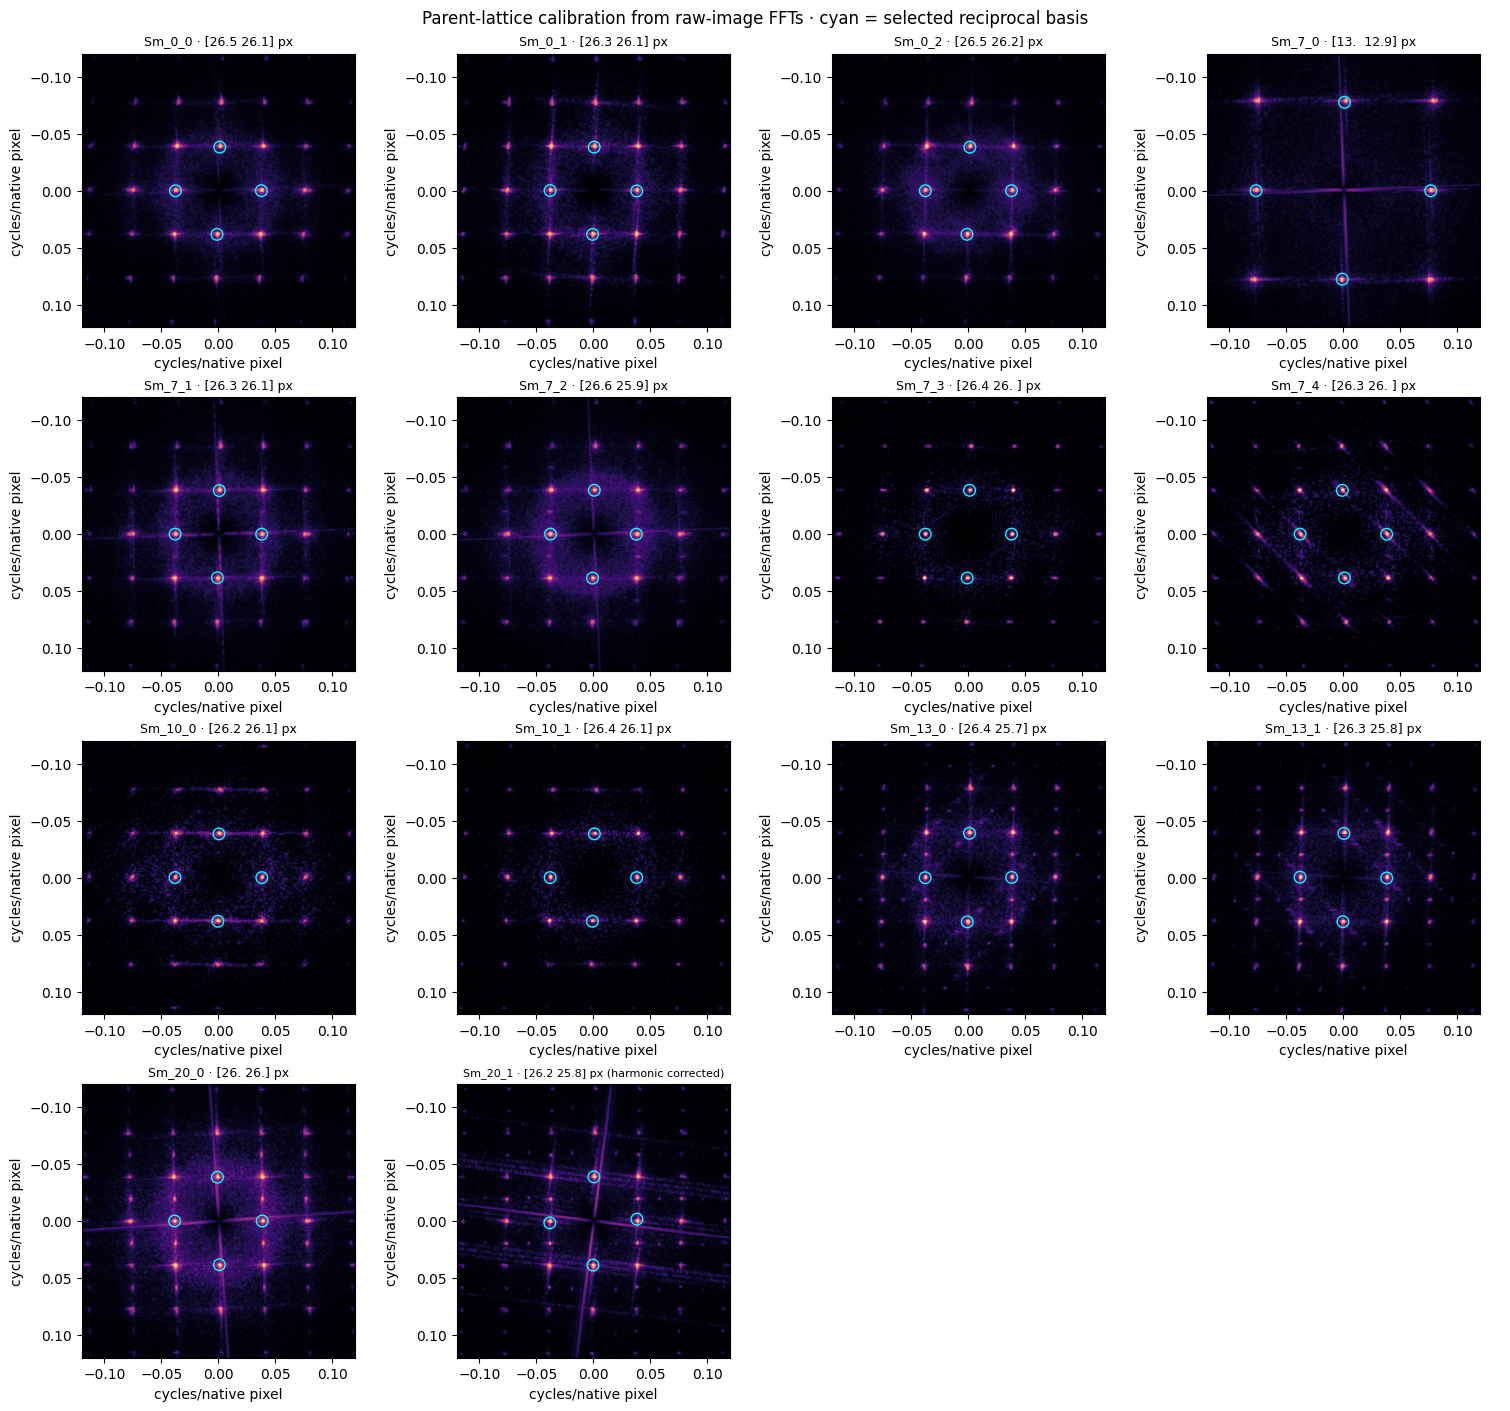

,image,spacing_px,spacing_pm,calibration_cells
0,Sm_0_0,"[26.534297419547386, 26.117396727018967]","[414.5983971804279, 408.08432385967143]",430
1,Sm_0_1,"[26.301394870022403, 26.113660924771228]","[410.9592948441001, 408.02595194955046]",882
2,Sm_0_2,"[26.463776636849364, 26.1536890780758]","[413.4965099507713, 408.65139184493444]",1079
3,Sm_7_0,"[13.047713204342681, 12.88131818132627]","[407.74103763570884, 402.54119316644596]",986
4,Sm_7_1,"[26.319956497032226, 26.134201457995896]","[411.2493202661286, 408.34689778118593]",598
5,Sm_7_2,"[26.565695373937984, 25.940859229825474]","[415.08899021778103, 405.3259254660231]",862
6,Sm_7_3,"[26.41696861921606, 25.99718210411728]","[412.76513467525103, 406.20597037683245]",1052
7,Sm_7_4,"[26.317686377451874, 26.027440789561826]","[411.2138496476856, 406.67876233690356]",712
8,Sm_10_0,"[26.22654515286393, 26.08505964740535]","[409.789768013499, 407.5790569907087]",153
9,Sm_10_1,"[26.35581183341563, 26.088177434755792]","[411.80955989711924, 407.6277724180593]",878


In [ ]:
#@title 4. Estimate parent lattices from raw-image Fourier spectra; no reference arrays
U,V=np.meshgrid((np.arange(SIZE)-(SIZE-1)/2)/PPC,(np.arange(SIZE)-(SIZE-1)/2)/PPC)

def clean_image(im):
    finite=np.isfinite(im);values=im[finite]
    if not len(values):raise ValueError('No finite pixels')
    lo,hi=np.percentile(values,[1,99]);x=np.where(finite,np.clip(im,lo,hi),np.median(values)).astype(np.float32)
    return x,finite

def fft_basis(im):
    x,finite=clean_image(im);H,W=x.shape
    # Average native-resolution FFT power over spatially distributed tiles.
    side=min(1024,H,W);power=[]
    for cy in np.linspace(side//2,H-side//2,3).astype(int):
        for cx in np.linspace(side//2,W-side//2,3).astype(int):
            tile=x[cy-side//2:cy-side//2+side,cx-side//2:cx-side//2+side]
            mask=finite[cy-side//2:cy-side//2+side,cx-side//2:cx-side//2+side]
            if mask.mean()<.8:continue
            tile=tile-ndi.gaussian_filter(tile,10)
            p=abs(np.fft.fftshift(np.fft.fft2(tile*np.hanning(side)[:,None]*np.hanning(side)[None,:])))**2
            power.append(p)
    if not power:raise RuntimeError('No supported calibration tiles')
    p=np.mean(power,axis=0);p/=max(p.max(),1e-12);freq=np.fft.fftshift(np.fft.fftfreq(side));qx,qy=np.meshgrid(freq,freq);r=np.hypot(qx,qy)
    peaks=(p==ndi.maximum_filter(p,7))&(r>1/120)&(r<1/6)&((qy>0)|((abs(qy)<1e-12)&(qx>0)))
    iy,ix=np.where(peaks&(p>.05*p.max()));sort=np.argsort(p[iy,ix])[::-1][:40];iy=iy[sort];ix=ix[sort]
    candidates=[]
    for y,x0 in zip(iy,ix):
        # Weighted spectral centroid refines frequency without a target label.
        ys=slice(max(0,y-1),y+2);xs=slice(max(0,x0-1),x0+2);w=p[ys,xs]
        q=np.array([(w*qx[ys,xs]).sum(),(w*qy[ys,xs]).sum()])/w.sum()
        candidates.append((q,p[y,x0]))
    options=[]
    for i,(q1,s1) in enumerate(candidates):
        for q2,s2 in candidates[i+1:]:
            cosine=abs(q1@q2)/(np.linalg.norm(q1)*np.linalg.norm(q2));ratio=np.linalg.norm(q1)/np.linalg.norm(q2)
            if cosine>.35 or not .80<ratio<1.25:continue
            score=np.log(s1*s2+1e-12)-.5*np.log(np.linalg.norm(q1)*np.linalg.norm(q2))
            options.append((score,np.linalg.inv(np.stack([q1,q2]))))
    if not options:raise RuntimeError('No near-orthogonal parent-lattice pair; inspect FFT and set a raw-image override')
    B=max(options,key=lambda z:z[0])[1]
    # u is the more horizontal direct vector; v is the more vertical, both positive along their major image axis.
    if abs(B[0,0])/np.linalg.norm(B[:,0])<abs(B[0,1])/np.linalg.norm(B[:,1]):B=B[:,::-1]
    if B[0,0]<0:B[:,0]*=-1
    if B[1,1]<0:B[:,1]*=-1
    return B,p,freq,np.array([q for q,_ in candidates])

def locate_cells(im,B,strict=True):
    x,finite=clean_image(im);s=float(np.min(np.linalg.norm(B,axis=0)))
    smooth=ndi.gaussian_filter(x,max(.5,.04*s));hp=smooth-ndi.gaussian_filter(smooth,.35*s)
    localmax=hp==ndi.maximum_filter(hp,max(3,int(.35*s)//2*2+1))
    peak_scale=float(np.percentile(hp[finite],99.8))
    mask=localmax&finite&(hp>np.percentile(hp[finite],70))
    y,xp=np.where(mask);pts=np.c_[xp,y].astype(float)
    margin=.3*s;ok=(pts[:,0]>margin)&(pts[:,0]<im.shape[1]-1-margin)&(pts[:,1]>margin)&(pts[:,1]<im.shape[0]-1-margin)
    pts=pts[ok]
    # Subpixel centroid of positive peak contrast, within a small local disk.
    radius=max(2,int(.20*s));dy,dx=np.mgrid[-radius:radius+1,-radius:radius+1];disk=(dx*dx+dy*dy)<=radius**2
    refined=[];strength=[]
    for start in range(0,len(pts),4096):
        p=pts[start:start+4096];xx=p[:,0,None,None]+dx;yy=p[:,1,None,None]+dy
        vals=ndi.map_coordinates(smooth,[yy.ravel(),xx.ravel()],order=1).reshape(-1,*dx.shape)
        floor=np.percentile(vals,20,axis=(1,2))[:,None,None];w=np.maximum(vals-floor,0)*disk
        sw=w.sum((1,2))+1e-8
        refined.append(p+np.c_[(w*dx).sum((1,2))/sw,(w*dy).sum((1,2))/sw]);strength.append(vals.max((1,2))-floor[:,0,0])
    pts=np.concatenate(refined);strength=ndi.map_coordinates(hp,[pts[:,1],pts[:,0]],order=1);tree=cKDTree(pts)
    # Refine lattice lengths from image peaks alone before locating four-corner cells.
    for j in range(2):
        distance,ids=tree.query(pts+B[:,j]);ok=distance<.20*s
        if ok.sum()>30:B[:,j]=np.median(pts[ids[ok]]-pts[ok],axis=0)
    offsets=np.array([[0,0],B[:,0],B[:,1],B[:,0]+B[:,1]])
    distances,ids=tree.query(pts[:,None,:]+offsets[None]);ok=(distances<.22*s).all(1)
    ids=ids[ok];corners=pts[ids];pc=corners.mean(1)
    # Reject the inverted sublattice: four A columns must be brighter than the enclosed B column.
    center_dist,center_id=tree.query(pc);center_strength=strength[center_id]
    valid=(center_dist<.28*s)&(strength[ids].mean(1)>1.08*center_strength)&(strength[ids].min(1)>.15*peak_scale)&(center_strength>.04*strength[ids].mean(1))
    if not strict:
        center_peak=ndi.maximum_filter(hp,2*max(2,int(.24*s))+1)
        center_strength=ndi.map_coordinates(center_peak,[pc[:,1],pc[:,0]],order=1)
        valid=(strength[ids].mean(1)>1.08*center_strength)&(strength[ids].min(1)>.15*peak_scale)
    ids=ids[valid];corners=corners[valid];pc=pc[valid]
    local_u=((corners[:,1]-corners[:,0])+(corners[:,3]-corners[:,2]))/2
    local_v=((corners[:,2]-corners[:,0])+(corners[:,3]-corners[:,1]))/2
    local_B=np.stack([local_u,local_v],axis=-1)
    # Each rectangle is keyed by its corner peak IDs, avoiding duplicate outputs.
    _,unique=np.unique(np.sort(ids,axis=1),axis=0,return_index=True)
    pc=pc[unique];local_B=local_B[unique]
    good=(np.linalg.det(local_B)>0)&(np.linalg.cond(local_B)<2)
    return pc[good],local_B[good],B,pts,strength

def canonical_basis(B):
    B=np.array(B,float,copy=True)
    if abs(B[0,0])/np.linalg.norm(B[:,0])<abs(B[0,1])/np.linalg.norm(B[:,1]):B=B[:,::-1]
    if B[0,0]<0:B[:,0]*=-1
    if B[1,1]<0:B[:,1]*=-1
    return B

def select_parent_basis(tile,initial):
    # A two-sublattice image can have stronger diagonal sum peaks than fundamental difference peaks.
    # Resolve this sqrt(2) ambiguity using occupied bright-corner / dim-center cells in raw pixels.
    transforms=[np.eye(2),np.array([[1,1],[-1,1]]),np.array([[1,1],[-1,1]])*.5,
                np.eye(2)*2,np.eye(2)*.5]
    choices=[]
    for transform in transforms:
        candidate=canonical_basis(initial@transform)
        if np.min(np.linalg.norm(candidate,axis=0))<6:continue
        pc,local,B,peaks,strength=locate_cells(tile,candidate)
        score=len(pc)/max(abs(np.linalg.det(B)),1)**.5
        choices.append((score,pc,local,B,peaks,strength))
    if not choices:raise RuntimeError('No usable image-only lattice candidate')
    best=max(choices,key=lambda item:item[0])
    return best[1:]

def sample_patches(im,centers,bases):
    if np.ndim(bases)==2:bases=np.broadcast_to(bases,(len(centers),2,2))
    delta=np.einsum('hwj,nij->nhwi',np.stack([U,V],-1),bases)
    co=centers[:,None,None,:]+delta
    return ndi.map_coordinates(im,[co[...,1].ravel(),co[...,0].ravel()],order=1,mode='constant',cval=np.nan).reshape(-1,SIZE,SIZE)

CALIBRATION=[]
fig,axes=plt.subplots(4,4,figsize=(15,14),layout='constrained')
for pair,ax in zip(PAIRS,axes.flat):
    im,pm=load_image(pair);B,power,freq,peaks=fft_basis(im)
    if pair['id'] in FFT_BASIS_OVERRIDES:B=np.asarray(FFT_BASIS_OVERRIDES[pair['id']],float)
    # Distributed crop is only for inexpensive raw-image calibration; application below uses complete images.
    H,W=im.shape;h=min(H,900);w=min(W,900);tile=im[(H-h)//2:(H+h)//2,(W-w)//2:(W+w)//2]
    pc,local_B,B,_,strength=(locate_cells(tile,B) if pair['id'] in FFT_BASIS_OVERRIDES else select_parent_basis(tile,B))
    if len(pc)<15:raise RuntimeError(pair['id']+': insufficient raw-image cells; inspect the FFT/contrast.')
    s=np.linalg.norm(B,axis=0);physical=np.linalg.norm(B*pm[:,None],axis=0)
    row={'image':pair['id'],'basis_px':B.tolist(),'pixel_pm_xy':pm.tolist(),'spacing_px':s.tolist(),
         'spacing_pm':physical.tolist(),'calibration_cells':len(pc),'source':'raw HAADF pixels + physical pixel metadata only'}
    CALIBRATION.append(row)
    ax.imshow(np.log1p(power*1e5),extent=(freq[0],freq[-1],freq[-1],freq[0]),cmap='magma')
    q=np.linalg.inv(B);ax.scatter(np.r_[q[:,0],-q[:,0]],np.r_[q[:,1],-q[:,1]],facecolors='none',edgecolors='cyan',s=70)
    ax.set_xlim(-.12,.12);ax.set_ylim(.12,-.12);ax.set_title(pair['id']+' · '+str(np.round(s,1))+' px',fontsize=9)
    ax.set_xlabel('cycles/native pixel');ax.set_ylabel('cycles/native pixel')
    del im;gc.collect()
# Same-material images supply a label-free consensus to resolve occasional factor-two indexing errors.
# The prior concerns the parent cation lattice; period doubling remains a separate predicted mode.
parent_median=float(np.median([np.mean(r['spacing_pm']) for r in CALIBRATION]))
for i,row in enumerate(CALIBRATION):
    ratio=np.mean(row['spacing_pm'])/parent_median
    if .74<ratio<1.35 or row['image'] in FFT_BASIS_OVERRIDES:continue
    candidates=[np.eye(2),np.eye(2)*.5,np.eye(2)*2,np.array([[1,1],[-1,1]]),np.array([[1,1],[-1,1]])*.5]
    old=np.array(row['basis_px']);pm=np.array(row['pixel_pm_xy'])
    candidate=min((canonical_basis(old@t) for t in candidates),key=lambda b:abs(np.log(np.mean(np.linalg.norm(b*pm[:,None],axis=0))/parent_median)))
    row['basis_before_consensus_px']=row['basis_px'];row['basis_px']=candidate.tolist()
    row['spacing_px']=np.linalg.norm(candidate,axis=0).tolist();row['spacing_pm']=np.linalg.norm(candidate*pm[:,None],axis=0).tolist()
    row['harmonic_correction']='same-material raw-image lattice consensus; no reference labels'
    row['calibration_cells_before_harmonic_correction']=row.pop('calibration_cells')
    im,_=load_image(PAIRS[i]);H,W=im.shape;h=min(H,900);w=min(W,900);tile=im[(H-h)//2:(H+h)//2,(W-w)//2:(W+w)//2]
    row['calibration_cells']=len(locate_cells(tile,candidate,strict=False)[0]);del im
    q=np.linalg.inv(candidate);axes.flat[i].collections[0].set_offsets(np.c_[np.r_[q[:,0],-q[:,0]],np.r_[q[:,1],-q[:,1]]])
    axes.flat[i].set_title(row['image']+' · '+str(np.round(row['spacing_px'],1))+' px (harmonic corrected)',fontsize=8)
    print('Raw-image consensus corrected harmonic indexing:',row['image'])
for ax in axes.flat[len(PAIRS):]:ax.axis('off')
fig.suptitle('Parent-lattice calibration from raw-image FFTs · cyan = selected reciprocal basis')
save_figure(fig,PROJECT_ROOT/'figures'/'01_raw_FFT_calibration.png');plt.show();plt.close(fig)
atomic_json(PROJECT_ROOT/'calibration'/'raw_image_calibration.json',CALIBRATION)
display(pd.DataFrame(CALIBRATION)[['image','spacing_px','spacing_pm','calibration_cells']])
audit('raw_image_calibration_complete',reference_arrays_loaded=False)


## Raw-image FFT completeness: declared and testable scope

1. Rectify the complete raw field with a shared parent basis; inspect the full FFT and distributed valid tiles. Cluster candidate satellites modulo reciprocal-lattice vectors and conjugation. Search is not restricted to the five nominal ordering families.
2. Compare each detected satellite **G ± q** with the Fourier response of the actual kernel arrays. The spectral criterion is normalized filter power ≥ 0.25 (−6.02 dB). The report records the best filter and every uncovered peak.
3. Probe both A/B sublattices, both displacement directions, cosine/sine phases, and three widths. Report the minimum fraction of template energy retained by the filter span, with a declared threshold of 0.10. Also sample the detected q and four offsets at its empirical frequency tolerance. This is a finite sensitivity check, not a continuous mathematical bound.
4. At exactly half-order the sine mode vanishes on integer atom sites. Tiny detuning introduces an additional phase/envelope degree of freedom. Consequently an exact commensurate mode may pass while the phase-complete detuning band is **not certified**. That does not prove the observed image is undetectable.
5. Uniform polarization is checked separately using opposite A/B displacement derivatives; common translations and independent site-intensity changes are nuisance directions. No new FFT satellite is required.

Physical basis: [IUCr structure-factor tutorial](https://www.iucr.org/what-we-do/education/pamphlets/introduction-calculation-of-structure-factors) explains the dependence on positions within the unit cell. The completeness audit below is an explicitly limited numerical diagnostic.

Peak detection is exploratory: local peak/background ≥ 50, exclusion within 0.12 cycles/cell of parent Bragg points, radius 0.3–2.2, power preselection >10⁻⁵ of that spectrum’s maximum, maximum 4,000 preselected maxima per spectrum, and clustering radius 0.03. “Stable” in the tables means repeated evidence in ≥2 tiles and ≥2 carriers, **not a confirmed material phase**. Localized and unconfirmed candidates remain in the exported tables. Weak peaks, peaks masked near Bragg points, features outside the searched band, and image distortions can defeat detection. Zero detected peaks is not a pass. Thresholds are declared, not optimized on experimental labels.

The audit is rerun on learned kernels because training may move their passbands. The geometric span check does not certify noise conditioning or downstream network accuracy. It does not establish antiferroelectricity from an FFT peak alone.


In [ ]:
"""Raw-image FFT coverage and separate real-space displacement sensitivity audit.

No experimental reference labels are accepted by this module.
"""
import json,math,hashlib
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import ndimage as ndi
from scipy.linalg import svd
import matplotlib.pyplot as plt

AUDIT_DEFAULTS=dict(ppc=6,tile=384,grid=3,min_valid=.96,min_contrast=50.,
                    bragg_exclusion=.12,max_frequency=2.2,max_peaks_per_spectrum=4000,
                    cluster_radius=.030,minimum_tiles=2,minimum_carriers=2,
                    frequency_power_floor=.25,motif_capture_floor=.10,
                    numerical_rank_floor=1e-5,fft_padding=512)

def audit_json(path,value):
    def clean(v):
        if isinstance(v,dict):return {k:clean(x) for k,x in v.items()}
        if isinstance(v,(list,tuple)):return [clean(x) for x in v]
        if isinstance(v,np.ndarray):return clean(v.tolist())
        if isinstance(v,np.generic):return clean(v.item())
        if isinstance(v,float) and not np.isfinite(v):return None
        return v
    Path(path).write_text(json.dumps(clean(value),indent=2,allow_nan=False))

def fold(q):return (np.asarray(q)+.5)%1-.5

def q_distance(a,b):return min(np.linalg.norm(fold(np.asarray(a)-b)),np.linalg.norm(fold(np.asarray(a)+b)))

def canonical_q(q):
    q=fold(q)
    if q[1]<-1e-8 or (abs(q[1])<1e-8 and q[0]<0):q=-q
    return q

def rectified_raw_field(image,basis,ppc=6):
    """Global rectification only. No atom-fitting reference coordinates."""
    basis=np.array(basis,float,copy=True);center=(np.array(image.shape[::-1])-1)/2
    for iteration in range(2):
        nu=max(24,int(image.shape[1]/np.linalg.norm(basis[:,0]))-2)
        nv=max(24,int(image.shape[0]/np.linalg.norm(basis[:,1]))-2)
        u,v=np.meshgrid((np.arange(nu*ppc)-(nu*ppc-1)/2)/ppc,(np.arange(nv*ppc)-(nv*ppc-1)/2)/ppc)
        xy=np.stack([u,v],-1)@basis.T+center
        field=ndi.map_coordinates(image,[xy[...,1],xy[...,0]],order=1,mode='constant',cval=np.nan)
        valid=np.isfinite(field)
        lo,hi=np.percentile(field[valid],[.1,99.9]);field=np.clip(field,lo,hi)
        P,kx,ky=power_spectrum(field,ppc)
        parent=[]
        for g in [[1,0],[0,1]]:
            allowed=np.hypot(kx-g[0],ky-g[1])<.09
            idx=np.unravel_index(np.argmax(np.where(allowed,P,-1)),P.shape)
            local=np.hypot(kx-kx[idx],ky-ky[idx])<.018
            parent.append([np.sum(kx[local]*P[local])/P[local].sum(),np.sum(ky[local]*P[local])/P[local].sum()])
        if iteration==0:basis=basis@np.linalg.inv(np.array(parent))
    return dict(field=field,mask=valid,basis=basis,ppc=ppc,P=P,qu=kx,qv=ky,measured_parent=np.array(parent),full_shape=np.array(image.shape))

def power_spectrum(field,ppc):
    valid=np.isfinite(field);h,w=field.shape
    fill=np.where(valid,field,np.nanmedian(field));res=fill-ndi.gaussian_filter(fill,ppc*2.)
    res=np.where(valid,res,0);window=np.hanning(h)[:,None]*np.hanning(w)[None,:]
    power=abs(np.fft.fftshift(np.fft.fft2(res*window)))**2/max(np.sum(window[valid]**2),1)
    kx,ky=np.meshgrid(np.fft.fftshift(np.fft.fftfreq(w,1/ppc)),np.fft.fftshift(np.fft.fftfreq(h,1/ppc)))
    return power,kx,ky

def spectral_peaks(P,kx,ky,source,cfg):
    r=np.hypot(kx,ky);distance=np.hypot(fold(kx),fold(ky))
    roi=(r>.3)&(r<cfg['max_frequency'])&(distance>cfg['bragg_exclusion'])&((ky>0)|((ky==0)&(kx>0)))
    candidate=np.argwhere(roi&(P==ndi.maximum_filter(P,5)))
    # Power cutoff only limits the computational preselection; report any cap.
    candidate=candidate[P[candidate[:,0],candidate[:,1]]>P.max()*1e-5]
    candidate=candidate[np.argsort(P[candidate[:,0],candidate[:,1]])[::-1]]
    capped=len(candidate)>cfg['max_peaks_per_spectrum'];candidate=candidate[:cfg['max_peaks_per_spectrum']]
    records=[];h,w=P.shape;dq=max(abs(kx[0,1]-kx[0,0]),abs(ky[1,0]-ky[0,0]))
    for y,x in candidate:
        a,b=max(0,y-10),min(h,y+11);c,d=max(0,x-10),min(w,x+11)
        rr=np.hypot(np.arange(a,b)[:,None]-y,np.arange(c,d)[None,:]-x)
        sub=P[a:b,c:d];ring=(rr>=5)&(rr<=10)
        # Bragg halos are not a valid noise-floor reference.
        ring&=np.hypot(fold(kx[a:b,c:d]),fold(ky[a:b,c:d]))>cfg['bragg_exclusion']
        if ring.sum()<20:continue
        background=np.median(sub[ring]);contrast=P[y,x]/max(background,1e-12)
        if contrast<cfg['min_contrast']:continue
        ys=slice(max(0,y-1),min(h,y+2));xs=slice(max(0,x-1),min(w,x+2))
        weight=np.maximum(P[ys,xs]-background,0);sw=weight.sum()
        k=np.array([np.sum(kx[ys,xs]*weight),np.sum(ky[ys,xs]*weight)])/sw
        q=canonical_q(k);g=np.rint(k).astype(int)
        records.append(dict(source=source,k_u=k[0],k_v=k[1],q_u=q[0],q_v=q[1],
                            G_u=g[0],G_v=g[1],contrast=contrast,power=P[y,x],resolution=dq))
    return records,capped

def discover_components(raw,name,cfg=None):
    cfg={**AUDIT_DEFAULTS,**(cfg or {})};field=raw['field'];ppc=float(raw['ppc'])
    spectra=[('whole',*power_spectrum(field,ppc))];h,w=field.shape;side=min(cfg['tile'],h,w)
    ys=np.linspace(0,h-side,cfg['grid']).astype(int);xs=np.linspace(0,w-side,cfg['grid']).astype(int)
    valid_tiles=[]
    for iy,y in enumerate(ys):
        for ix,x in enumerate(xs):
            tile=field[y:y+side,x:x+side]
            if np.isfinite(tile).mean()<cfg['min_valid']:continue
            source=f'tile_{iy}_{ix}';spectra.append((source,*power_spectrum(tile,ppc)));valid_tiles.append(source)
    candidates=[];caps=[]
    for source,P,kx,ky in spectra:
        peaks,capped=spectral_peaks(P,kx,ky,source,cfg);candidates+=peaks
        if capped:caps.append(source)
    # Greedy toroidal clustering includes ±q and integer-lattice equivalence.
    clusters=[]
    for row in sorted(candidates,key=lambda r:r['contrast'],reverse=True):
        q=np.array([row['q_u'],row['q_v']]);found=False
        for cluster in clusters:
            if q_distance(q,cluster['seed'])<cfg['cluster_radius']:
                cluster['rows'].append(row);found=True;break
        if not found:clusters.append(dict(seed=q,rows=[row]))
    modes=[];peak_rows=[]
    for ci,cl in enumerate(clusters):
        points=[];weights=[];seed=cl['seed']
        for row in cl['rows']:
            q=np.array([row['q_u'],row['q_v']])
            sign=1 if np.linalg.norm(fold(q-seed))<=np.linalg.norm(fold(-q-seed)) else -1
            points.append(seed+fold(sign*q-seed));weights.append(min(row['contrast'],1000)**.5)
        q=canonical_q(np.average(points,axis=0,weights=weights))
        tiles={r['source'] for r in cl['rows'] if r['source']!='whole'}
        carriers={(r['G_u'],r['G_v']) for r in cl['rows']}
        stable=len(tiles)>=cfg['minimum_tiles'] and len(carriers)>=cfg['minimum_carriers']
        localized=len(tiles)>=1 and len(carriers)>=2 and max(r['contrast'] for r in cl['rows'])>=50
        status='stable' if stable else 'localized_candidate' if localized else 'unconfirmed_candidate'
        family_q={'half_u':(.5,0),'half_v':(0,.5),'checker':(.5,.5),'quarter_plus':(.25,.25),'quarter_minus':(-.25,.25)}
        family=min(family_q,key=lambda n:q_distance(q,family_q[n]));distance=q_distance(q,family_q[family])
        spread=max(q_distance([r['q_u'],r['q_v']],q) for r in cl['rows'])
        # Resolution is an empirical tolerance, not a statistical confidence bound.
        uncertainty=max(np.median([r['resolution'] for r in cl['rows']]),spread)
        identifier=f'{name}_q{ci:02d}'
        modes.append(dict(image=name,component_id=identifier,q_u=q[0],q_v=q[1],evidence=status,tiles=len(tiles),carriers=len(carriers),
                          strongest_contrast=max(r['contrast'] for r in cl['rows']),q_tolerance=uncertainty,
                          nearest_family=family,nominal_distance=distance,nominal_match=distance<=.055,commensurate_within_tolerance=distance<=uncertainty))
        for row in cl['rows']:peak_rows.append(dict(image=name,component_id=identifier,**row))
    info=dict(image=name,whole_image_shape=np.asarray(raw['full_shape']).tolist(),valid_tiles=len(valid_tiles),
              spectrum_count=len(spectra),preselection_capped_spectra=caps,candidates=len(candidates),reference_labels_used=False)
    return pd.DataFrame(modes,columns=list(modes[0]) if modes else ['image','component_id','q_u','q_v','evidence','q_tolerance']),pd.DataFrame(peak_rows,columns=list(peak_rows[0]) if peak_rows else ['image','component_id','k_u','k_v']),info

def kernel_spectrum_envelope(kernels,ppc=12,cfg=None):
    cfg={**AUDIT_DEFAULTS,**(cfg or {})};n=cfg['fft_padding'];freq=np.fft.fftshift(np.fft.fftfreq(n,1/ppc));x,y=np.meshgrid(freq,freq)
    roi=(np.hypot(x,y)>.1)&(np.hypot(x,y)<cfg['max_frequency']+.2)
    env=np.zeros((n,n));best=np.zeros((n,n),int)
    for i,k in enumerate(kernels):
        p=abs(np.fft.fftshift(np.fft.fft2(k,s=(n,n))))**2
        p/=max(p[roi].max(),1e-12);better=p>env;env[better]=p[better];best[better]=i
    return env,best,freq

def orthonormal_columns(x,tol=1e-5):
    u,s,_=svd(x,full_matrices=False,check_finite=False)
    return u[:,s>max(s[0]*tol,1e-12)] if len(s) else u[:,:0]

def bank_row_basis(kernels,tol=1e-5):
    k=kernels.reshape(len(kernels),-1).astype(float)
    _,s,v=svd(k,full_matrices=False,check_finite=False)
    return v[s>s[0]*tol]

def atomic_tangents(q,size=120,ppc=12,sigma=1.25,include_intensity=False):
    axis=np.arange(size)-(size-1)/2;rows=[];labels=[]
    for site,n in [('A',10),('B',9)]:
        atoms=np.arange(n)-(n-1)/2;y,x=np.meshgrid(atoms,atoms,indexing='ij')
        shift=.5 if site=='A' else 0
        arg=2*np.pi*((x+shift)*q[0]+(y+shift)*q[1])
        d=(axis[:,None]-atoms[None,:]*ppc)/sigma
        g=np.exp(-.5*d*d);dg=d*g
        for phase,w in [('cos',np.cos(arg)),('sin',np.sin(arg))]:
            if np.linalg.norm(w)<1e-7:continue
            for c in ([0,1,2] if include_intensity else [0,1]):
                result=(g@w@dg.T if c==0 else dg@w@g.T if c==1 else g@w@g.T)
                result-=result.mean();norm=np.linalg.norm(result)
                if norm>1e-8:rows.append((result/norm).ravel());labels.append(f'{site}_{phase}_{["du","dv","intensity"][c]}')
    return np.array(rows).T,labels

def motif_coverage(row_basis,q,size=120,ppc=12):
    """Finite Gaussian-template observability, not a guarantee for arbitrary objects."""
    out=[]
    for width in [.8,1.25,1.8]:
        T,labels=atomic_tangents(q,size,ppc,width);Q=orthonormal_columns(T)
        response=row_basis@Q;s=np.linalg.svd(response,compute_uv=False)
        capture=np.sum((row_basis@T)**2,axis=0)
        out.append(dict(sigma=width,worst_capture=float(s[-1]**2),rank=int(np.sum(s>1e-5)),target_rank=Q.shape[1],
                        A_min=float(min(v for v,l in zip(capture,labels) if l.startswith('A_'))),
                        B_min=float(min(v for v,l in zip(capture,labels) if l.startswith('B_')))))
    return out

def polarization_audit(kernels,ppc=12):
    basis=bank_row_basis(kernels);T,labels=atomic_tangents([0,0],kernels.shape[-1],ppc,1.25,True)
    # Site derivatives are individually normalized. Unit contrast weights set the
    # probe convention; this is an observability test, not absolute pm calibration.
    get=lambda name:T[:,labels.index(name)]
    px=.5*(get('A_cos_du')-get('B_cos_du'));py=.5*(get('A_cos_dv')-get('B_cos_dv'))
    nuisance=np.stack([get('A_cos_du')+get('B_cos_du'),get('A_cos_dv')+get('B_cos_dv'),get('A_cos_intensity'),get('B_cos_intensity')],axis=1)
    P=np.stack([px/np.linalg.norm(px),py/np.linalg.norm(py)],axis=1)
    N=orthonormal_columns(basis@nuisance);F=basis@P;F-=N@(N.T@F)
    s=np.linalg.svd(F,compute_uv=False)
    # Uniform internal displacement retains the one-cell translation period.
    # Exact tiled unit cells have Fourier support only at the same reciprocal comb.
    n=32;a=(np.arange(n)+.5)/n;xx,yy=np.meshgrid(a,a)
    def periodic_gauss(cx,cy):
        dx=(xx-cx+.5)%1-.5;dy=(yy-cy+.5)%1-.5
        return np.exp(-(dx*dx+dy*dy)/(2*.09**2))
    f0=np.tile(periodic_gauss(.25,.25)+.5*periodic_gauss(.75,.75),(8,8))
    fp=np.tile(periodic_gauss(.25+.025,.25)+.5*periodic_gauss(.75-.025,.75),(8,8))
    F0=abs(np.fft.fft2(f0))**2;Fp=abs(np.fft.fft2(fp))**2;iy,ix=np.indices(Fp.shape);comb=(iy%8==0)&(ix%8==0)
    leakage=float(Fp[~comb].sum()/Fp.sum())
    return dict(test='Uniform A/B relative displacement; common translations and site intensities projected out in feature space',
                retained_rank=int(np.sum(s>1e-5)),worst_residual_capture=float(s[-1]**2),
                polarization_sensitive=bool(len(s)==2 and s[-1]**2>=.10),
                new_frequency_power_fraction_in_periodic_polar_probe=leakage,
                interpretation='Uniform polarization changes the unit-cell motif / complex parent coefficients; a new satellite is not required.',
                reference_labels_used=False)

def evaluate_bank(kernels,modes,peaks,out,stage,cfg=None,ppc=12,registration='global_parent'):
    cfg={**AUDIT_DEFAULTS,**(cfg or {})};out=Path(out);out.mkdir(parents=True,exist_ok=True)
    kernels=np.asarray(kernels,float);basis=bank_row_basis(kernels)
    env,winner,freq=kernel_spectrum_envelope(kernels,ppc,cfg);df=freq[1]-freq[0]
    result=[];observed=[];motif_cache={}
    for _,m in modes.iterrows():
        pp=peaks[peaks.component_id==m.component_id].copy();q=np.array([m.q_u,m.q_v])
        coords=np.array([(pp.k_v-freq[0])/df,(pp.k_u-freq[0])/df])
        gains=ndi.map_coordinates(env,coords,order=1,mode='constant',cval=0.)
        indices=ndi.map_coordinates(winner.astype(float),coords,order=0,mode='nearest').astype(int)
        for (_,p),gain,idx in zip(pp.iterrows(),gains,indices):
            observed.append({**p.to_dict(),'stage':stage,'relative_filter_power':float(gain),
                             'gain_db':float(10*np.log10(max(gain,1e-12))),'best_filter':int(idx),'frequency_pass':bool(gain>=cfg['frequency_power_floor'])})
        # Center and tolerance-axis samples: finite numerical check, not continuum proof.
        eps=float(m.q_tolerance)
        samples=[q,q+[eps,0],q-[eps,0],q+[0,eps],q-[0,eps]]
        probe=[]
        for qq in samples:
            key=tuple(np.round(qq,5))
            if key not in motif_cache:motif_cache[key]=motif_coverage(basis,qq,kernels.shape[-1],ppc)
            probe+=motif_cache[key]
        # Near Nyquist, a tiny detuning adds a sine-envelope degree of freedom.
        # Report nominal and uncertainty results separately rather than hiding it.
        nominal=motif_cache[tuple(np.round(q,5))]
        nominal_worst=min(p['worst_capture'] for p in nominal);robust_worst=min(p['worst_capture'] for p in probe)
        freq_pass=bool(np.all(gains>=cfg['frequency_power_floor']))
        sensitivity_pass=robust_worst>=cfg['motif_capture_floor']
        status='COVERED_TESTED_MODES' if freq_pass and sensitivity_pass else 'FREQUENCY_GAP' if not freq_pass else 'PHASE_BAND_NOT_CERTIFIED'
        if registration!='global_parent':status='REGISTRATION_REQUIRES_SEPARATE_TEST'
        result.append({**m.to_dict(),'stage':stage,'spectral_pass':freq_pass,'worst_peak_gain_db':float(10*np.log10(max(gains.min(),1e-12))),
                       'fraction_peaks_frequency_covered':float(np.mean(gains>=cfg['frequency_power_floor'])),
                       'nominal_displacement_capture':nominal_worst,'tolerance_displacement_capture':robust_worst,
                       'nominal_A_min':min(x['A_min'] for x in nominal),'nominal_B_min':min(x['B_min'] for x in nominal),
                       'status':status,'frequency_guarantee_scope':'detected peaks only; current kernels; thresholded numerical check'})
    table=pd.DataFrame(result) if result else pd.DataFrame(columns=[*modes.columns,'stage','status','spectral_pass']);obs=pd.DataFrame(observed)
    table.to_csv(out/(stage+'_coverage.csv'),index=False);obs.to_csv(out/(stage+'_peak_responses.csv'),index=False)
    polar=polarization_audit(kernels,ppc);audit_json(out/(stage+'_polarization.json'),polar)
    np.savez_compressed(out/(stage+'_spectral_envelope.npz'),envelope=env,best_filter=winner,frequency=freq)
    summary=dict(stage=stage,kernel_sha256=hashlib.sha256(kernels.tobytes()).hexdigest(),filters=len(kernels),bank_rank=len(basis),registration=registration,thresholds=cfg,
                 detected_components=len(table),
                 detected_components_frequency_covered=int(table.spectral_pass.astype(bool).sum()),
                 all_detected_components_frequency_covered=bool(len(table)>0 and table.spectral_pass.astype(bool).all()),
                 all_detected_components_tested_modes_covered=bool(len(table)>0 and (table.status=='COVERED_TESTED_MODES').all()),
                 stable_components=int((table.evidence=='stable').sum()),
                 stable_frequency_covered=int(((table.evidence=='stable')&table.spectral_pass.astype(bool)).sum()),
                 stable_components_passing=int(((table.evidence=='stable')&(table.status=='COVERED_TESTED_MODES')).sum()),
                 all_stable_components_covered=bool((table.loc[table.evidence=='stable','status']=='COVERED_TESTED_MODES').all()) if (table.evidence=='stable').any() else False,
                 polarization=polar,ground_truth_used=False,
                 limit='Not a guarantee of phase identification, noise robustness, nonlinear network accuracy, all possible modes, or absent weak peaks. FFT magnitude does not determine displacement versus occupancy. Tolerance probes are sampled, not a continuum bound.')
    audit_json(out/(stage+'_summary.json'),summary)
    return table,summary

def plot_coverage(table,out,stage):
    out=Path(out);stable=table[table.evidence=='stable'].copy()
    fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
    colors={'COVERED_TESTED_MODES':'#24744e','FREQUENCY_GAP':'#b13c35','PHASE_BAND_NOT_CERTIFIED':'#c78624','REGISTRATION_REQUIRES_SEPARATE_TEST':'#777777'}
    if stable.empty:
        axes[0].text(.5,.5,'No candidates meet the repeated-evidence rule',ha='center',transform=axes[0].transAxes)
        axes[1].axis('off');fig.savefig(out/(stage+'_coverage.png'),dpi=160);plt.close(fig);return
    for status,part in stable.groupby('status'):
        axes[0].scatter(part.q_u,part.q_v,c=colors[status],s=45,label=status.replace('_',' ').lower(),alpha=.8,edgecolor='white',lw=.4)
    axes[0].set(xlim=(-.55,.55),ylim=(-.03,.55),xlabel='q_u (cycles / parent cell)',ylabel='q_v (cycles / parent cell)',title='Repeated FFT candidates (not assigned phases)')
    axes[0].grid(alpha=.2);axes[0].legend(fontsize=8)
    count=stable.groupby(['image','status']).size().unstack(fill_value=0)
    count=count.reindex(sorted(count.index,key=lambda x:tuple(map(int,x.split('_')[1:]))))
    count.plot.barh(stacked=True,color=[colors[s] for s in count.columns],ax=axes[1],legend=False)
    axes[1].set(xlabel='Detected components',ylabel='',title='Coverage of actual filter arrays')
    fig.suptitle(stage+' · frequency coverage and displacement sensitivity are separate checks')
    fig.savefig(out/(stage+'_coverage.png'),dpi=160,bbox_inches='tight');plt.close(fig)


def nominal_mode_audit(kernels,ppc=12):
    basis=bank_row_basis(kernels);rows=[]
    for name,q in [('half_u',[.5,0]),('half_v',[0,.5]),('checker',[.5,.5]),('quarter_plus',[.25,.25]),('quarter_minus',[-.25,.25])]:
        probes=motif_coverage(basis,q,kernels.shape[-1],ppc)
        rows.append(dict(mode=name,q_u=q[0],q_v=q[1],minimum_capture=min(r['worst_capture'] for r in probes),
                         tested_mode_pass=min(r['worst_capture'] for r in probes)>=.10))
    return pd.DataFrame(rows)


def audit_completeness_decision(summary,discovery):
    # No detections, incomplete spatial coverage, or capped search cannot produce a universal PASS.
    return dict(detected_peak_frequency_coverage=summary['all_detected_components_frequency_covered'],
                repeated_candidate_frequency_coverage=(summary['stable_components']>0 and summary['stable_frequency_covered']==summary['stable_components']),
                tested_displacement_band_coverage=summary['all_detected_components_tested_modes_covered'],
                search_preselection_uncapped=not any(x['preselection_capped_spectra'] for x in discovery),
                universal_completeness_guaranteed=False,
                explanation='Only declared detected peaks and finite template probes are tested; undetected/weak/localized peaks and other physical motifs are outside a universal guarantee.')


def plot_fft_filter_comparison(raw,peak_responses,envelope,frequency,out,title):
    fig,ax=plt.subplots(1,2,figsize=(11,5),layout='constrained')
    P=raw['P'];kx=raw['qu'];ky=raw['qv']
    extent=[kx.min(),kx.max(),ky.min(),ky.max()]
    z=10*np.log10(np.maximum(ndi.maximum_filter(P,3)/P.max(),1e-10)) # Peak-preserving display only; audit uses unsmoothed powers.
    a=ax[0].imshow(z,extent=extent,origin='lower',cmap='magma',vmin=-55,vmax=0)
    fig.colorbar(a,ax=ax[0],label='Raw FFT power / maximum (dB)',shrink=.8)
    a=ax[1].imshow(10*np.log10(np.maximum(envelope,1e-10)),extent=[frequency[0],frequency[-1],frequency[0],frequency[-1]],origin='lower',cmap='viridis',vmin=-30,vmax=0)
    fig.colorbar(a,ax=ax[1],label='Best normalized filter power (dB)',shrink=.8)
    for _,p in peak_responses.iterrows():
        color='#71e5cb' if p.frequency_pass else '#ff6e5c'
        for a in ax:a.scatter([p.k_u,-p.k_u],[p.k_v,-p.k_v],facecolors='none',edgecolors=color,s=36,lw=.7)
    for a in ax:a.set(xlim=(-2.2,2.2),ylim=(-2.2,2.2),xlabel='k_u (cycles / parent cell)',ylabel='k_v (cycles / parent cell)')
    ax[0].set_title('Raw-image FFT (3-pixel peak display)');ax[1].set_title('Actual bank Fourier envelope')
    fig.suptitle(title+'\nRings: detected peaks, teal ≥ −6 dB; red < −6 dB. This is the frequency test only.',fontsize=11)
    fig.savefig(out,dpi=160,bbox_inches='tight');plt.close(fig)


In [ ]:
#@title Raw-image-only satellite discovery, before any synthetic training
COVERAGE_DIR=PROJECT_ROOT/'coverage_audit';COVERAGE_DIR.mkdir(exist_ok=True)
FFT_AUDIT_CONFIG=dict(AUDIT_DEFAULTS)
RAW_MODES=[];RAW_PEAKS=[];FFT_DISCOVERY=[]
for pair,cal in zip(PAIRS,CALIBRATION):
    im,_=load_image(pair)
    raw=rectified_raw_field(im,np.asarray(cal['basis_px']),FFT_AUDIT_CONFIG['ppc'])
    # Use the same refined raw-image parent basis in simulation and inference.
    cal['basis_px']=raw['basis'].tolist();cal['spacing_px']=np.linalg.norm(raw['basis'],axis=0).tolist()
    cal['spacing_pm']=np.linalg.norm(raw['basis']*np.asarray(cal['pixel_pm_xy'])[:,None],axis=0).tolist()
    modes,peaks,info=discover_components(raw,pair['id'],FFT_AUDIT_CONFIG)
    np.savez_compressed(COVERAGE_DIR/(pair['id']+'_raw_spectrum.npz'),P=raw['P'].astype(np.float32),qu=raw['qu'][0].astype(np.float32),qv=raw['qv'][:,0].astype(np.float32))
    RAW_MODES.append(modes);RAW_PEAKS.append(peaks);FFT_DISCOVERY.append(info)
    print(pair['id'],len(modes),'candidate q clusters; valid tiles:',info['valid_tiles'])
    del im,raw;gc.collect()
RAW_MODES=pd.concat(RAW_MODES,ignore_index=True);RAW_PEAKS=pd.concat(RAW_PEAKS,ignore_index=True)
RAW_MODES.to_csv(COVERAGE_DIR/'raw_components.csv',index=False);RAW_PEAKS.to_csv(COVERAGE_DIR/'raw_peak_locations.csv',index=False)
audit_json(COVERAGE_DIR/'discovery.json',FFT_DISCOVERY)
atomic_json(PROJECT_ROOT/'calibration'/'raw_image_calibration.json',CALIBRATION)
if any(x['preselection_capped_spectra'] for x in FFT_DISCOVERY):
    print('WARNING: peak preselection was capped. Increase its limit before claiming detected-peak completeness.')
audit('raw_fft_candidates_discovered',reference_arrays_loaded=False)
display(RAW_MODES)


Sm_0_0 3 candidate q clusters; valid tiles: 9
Sm_0_1 1 candidate q clusters; valid tiles: 1
Sm_0_2 2 candidate q clusters; valid tiles: 4
Sm_7_0 54 candidate q clusters; valid tiles: 9
Sm_7_1 6 candidate q clusters; valid tiles: 9
Sm_7_2 4 candidate q clusters; valid tiles: 9
Sm_7_3 3 candidate q clusters; valid tiles: 1
Sm_7_4 1 candidate q clusters; valid tiles: 1
Sm_10_0 2 candidate q clusters; valid tiles: 1
Sm_10_1 1 candidate q clusters; valid tiles: 1
Sm_13_0 3 candidate q clusters; valid tiles: 1
Sm_13_1 4 candidate q clusters; valid tiles: 1
Sm_20_0 1 candidate q clusters; valid tiles: 9
Sm_20_1 36 candidate q clusters; valid tiles: 9


,image,component_id,q_u,q_v,evidence,tiles,carriers,strongest_contrast,q_tolerance,nearest_family,nominal_distance,nominal_match,commensurate_within_tolerance
0,Sm_0_0,Sm_0_0_q00,-0.141215,0.137306,unconfirmed_candidate,1,1,72.822271,0.015625,quarter_minus,0.156634,False,False
1,Sm_0_0,Sm_0_0_q01,0.026126,0.365163,unconfirmed_candidate,0,1,52.061111,0.006369,half_v,0.137345,False,False
2,Sm_0_0,Sm_0_0_q02,0.010327,0.143098,unconfirmed_candidate,1,1,51.666157,0.015625,quarter_plus,0.262433,False,False
3,Sm_0_1,Sm_0_1_q00,0.120981,0.004857,unconfirmed_candidate,0,1,57.825275,0.006061,quarter_plus,0.277021,False,False
4,Sm_0_2,Sm_0_2_q00,-0.002605,0.499707,unconfirmed_candidate,0,2,71.662538,0.006410,half_v,0.002622,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
116,Sm_20_1,Sm_20_1_q31,-0.120505,0.369585,unconfirmed_candidate,0,1,56.577377,0.005780,quarter_minus,0.176265,False,False
117,Sm_20_1,Sm_20_1_q32,-0.002941,0.125760,unconfirmed_candidate,0,2,56.105419,0.005780,quarter_minus,0.276539,False,False
118,Sm_20_1,Sm_20_1_q33,0.315912,0.159694,unconfirmed_candidate,1,1,53.939928,0.015625,quarter_plus,0.111802,False,False
119,Sm_20_1,Sm_20_1_q34,-0.077423,0.498651,unconfirmed_candidate,1,1,53.643775,0.015625,half_v,0.077435,False,False


## 3. Generate artificial atomic structures and exact targets

The simulator renders two projected cation sublattices with subpixel Gaussian columns. It includes uniform polarization, half-order modes, checkerboard modes, both diagonal quarter-order modes, and mixed states. Ordered motion can occur on A only, B only, opposite-moving A/B sites, or independently phased mixed A/B sites. Quarter wavevectors vary by up to ±0.03 cycles/cell around their nominal values.

Native spacing, global lattice angle, weak strain/shear, registration uncertainty, smooth scan distortion, domain walls, column widths/ellipticity, contrast, Poisson noise, Gaussian noise and row-correlated noise are varied. Intensity modulation is randomized independently of displacement modulation. This is a projected-Gaussian simulator, **not a multislice STEM calculation**.

Synthetic registration uses the same geometric reference as inference: the center and local basis of the four A columns surrounding the central B cell. Labels are recomputed in this registered frame from the exact rendered column positions.

The displacement proxy is
\[
\mathbf P_{ij}=\tfrac14\sum_{\text{four A corners}}\mathbf r_A-\mathbf r_B.
\]

It is a cation displacement in pixels or pm, not absolute polarization in C/m². The reference convention is `PCOM − NCOM`.

For each 9×9 B-cell neighborhood, a joint least-squares fit separates uniform displacement, two linear trends, three parity modes, and cosine/sine components at both quarter wavevectors. A-site fits use the 10×10 bounding A columns and integer site indices shifted by half a cell. Linear trends are nuisance terms and are not predicted.

| Output group | Components |
|---|---:|
| Central-cell displacement | 2 |
| Uniform P | 2 |
| P ordering: 3 half/checker vectors + 2 quarter vectors × 2 phases | 14 |
| A-sublattice ordering coefficients | 14 |
| B-sublattice ordering coefficients | 14 |
| **Total** | **46** |

The site heads matter: A-site alternation can cancel when four corners are averaged, leaving a small P signal despite real atomic ordering. All 46 outputs have exact synthetic targets. Only the P-related outputs have deposited experimental reference counterparts here.

The dataset retains the images, exact labels, all 81 per-cell displacement vectors, native-to-canonical bases, nuisance metadata and disjoint generation seeds. Off-nominal wavevectors and domain walls are labelled by their **local projection onto the nominal basis**, not by an assumed perfectly uniform phase.

Generate train:   0%|          | 0/12000 [00:00<?, ?it/s]

Generate validation:   0%|          | 0/2000 [00:00<?, ?it/s]

Generate test:   0%|          | 0/2000 [00:00<?, ?it/s]

Generate stress:   0%|          | 0/1000 [00:00<?, ?it/s]

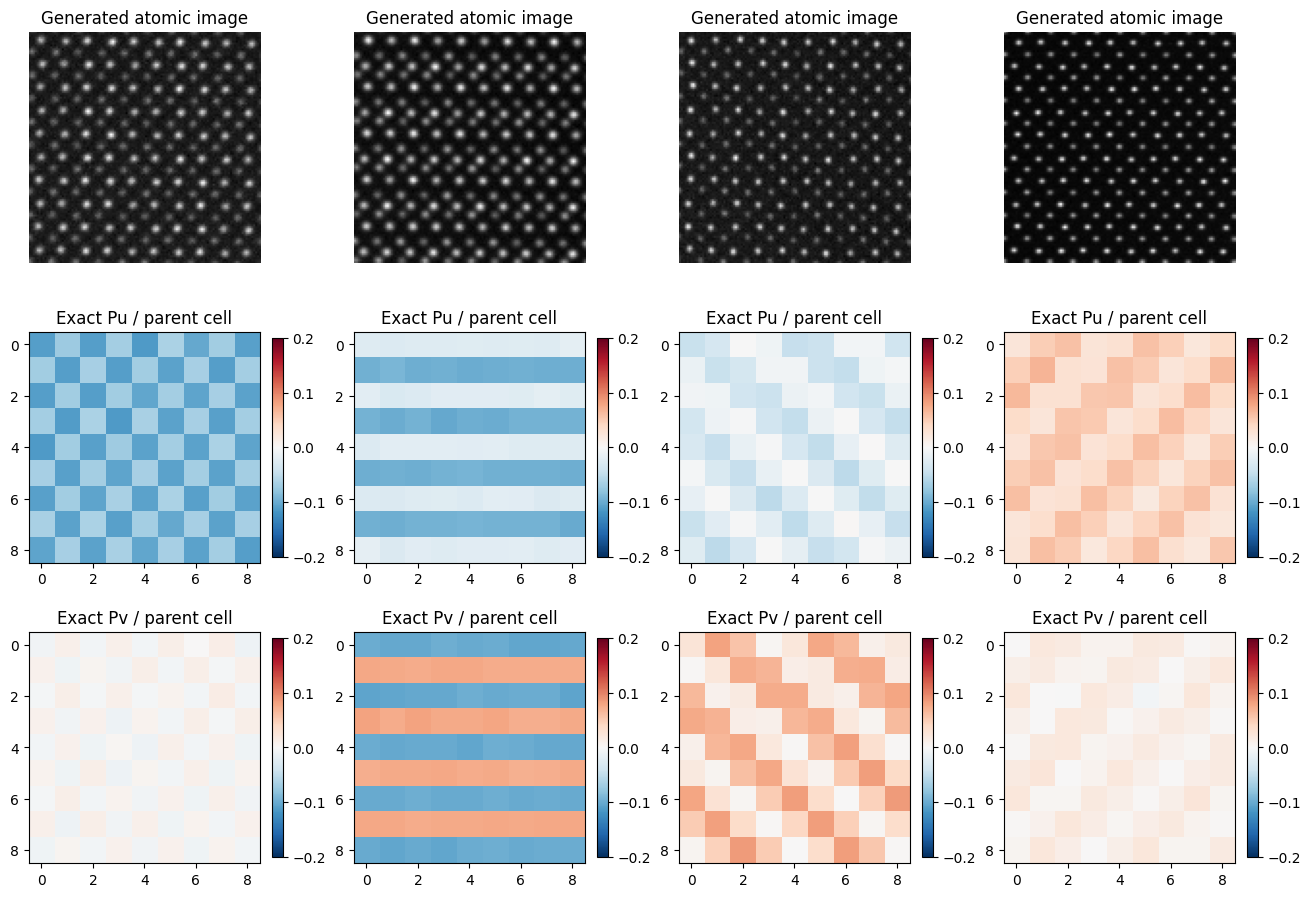

In [ ]:
#@title 5. Synthetic A/B sublattices, half-order and diagonal quarter-order modes
MODE_NAMES=['half_u','half_v','checker','quarter_plus_cos','quarter_plus_sin','quarter_minus_cos','quarter_minus_sin']
Q_NOMINAL=np.array([[.25,.25],[-.25,.25]],float)
def cell_grid(n,half=False):
    a=np.arange(n)-(n-1)/2
    y,x=np.meshgrid(a,a,indexing='ij');return np.c_[x.ravel(),y.ravel()]
B_GRID=cell_grid(9);A_GRID=cell_grid(10)
B_RENDER=cell_grid(11);A_RENDER=cell_grid(12)
B_IDS=np.flatnonzero((abs(B_RENDER)<=4).all(1));A_IDS=np.flatnonzero((abs(A_RENDER)<=4.5).all(1))
def design(points,site='B',q=None):
    q=Q_NOMINAL if q is None else np.asarray(q)
    indices=points+(.5 if site=='A' else 0.)
    x,y=indices.T
    phase=2*np.pi*indices@q.T
    return np.c_[np.ones(len(points)),points, np.cos(np.pi*x),np.cos(np.pi*y),np.cos(np.pi*(x+y)),
                 np.cos(phase[:,0]),np.sin(phase[:,0]),np.cos(phase[:,1]),np.sin(phase[:,1])]
DESIGN_B=design(B_GRID);DESIGN_A=design(A_GRID,'A')
PINV_B=np.linalg.pinv(DESIGN_B);PINV_A=np.linalg.pinv(DESIGN_A)
assert np.linalg.matrix_rank(DESIGN_B)==np.linalg.matrix_rank(DESIGN_A)==10
TARGET_NAMES=['local_Pu','local_Pv','uniform_Pu','uniform_Pv']
TARGET_NAMES += [f'P_{m}_{c}' for m in MODE_NAMES for c in ['u','v']]
TARGET_NAMES += [f'{site}_{m}_{c}' for site in ['A','B'] for m in MODE_NAMES for c in ['u','v']]
assert len(TARGET_NAMES)==46
TARGET_GROUPS={'local':slice(0,2),'P_uniform':slice(2,4),'P_order':slice(4,18),'A_order':slice(18,32),'B_order':slice(32,46)}
# The four A corners of each of the 81 labelled B cells, in the render grid.
CORNER_IDS=np.array([[int(np.argmin(np.linalg.norm(A_RENDER-(p+d),axis=1))) for d in [(-.5,-.5),(.5,-.5),(-.5,.5),(.5,.5)]] for p in B_GRID])
MID_B=int(np.flatnonzero((B_GRID==0).all(1))[0]);MID_CORNERS=CORNER_IDS[MID_B]

def render_columns(side,points,amplitude,sx,sy):
    radius=int(math.ceil(4*max(sx,sy)));dy,dx=np.mgrid[-radius:radius+1,-radius:radius+1]
    ix=np.floor(points[:,0]).astype(int)[:,None,None]+dx;iy=np.floor(points[:,1]).astype(int)[:,None,None]+dy
    z=amplitude[:,None,None]*np.exp(-.5*((ix-points[:,0,None,None])**2/sx**2+(iy-points[:,1,None,None])**2/sy**2))
    valid=(ix>=0)&(ix<side)&(iy>=0)&(iy<side);im=np.zeros((side,side),np.float32)
    np.add.at(im,(iy[valid],ix[valid]),z[valid]);return im

def synthetic_sample(seed,stress=False):
    rng=np.random.default_rng(int(seed));cal=CALIBRATION[rng.integers(len(CALIBRATION))]
    factor=np.exp(rng.uniform(-np.log(LATTICE_RANGE_FACTOR),np.log(LATTICE_RANGE_FACTOR)))
    lengths=np.array(cal['spacing_px'])*factor*rng.uniform(.97,1.03,2)
    angle=rng.uniform(-np.pi,np.pi);R=np.array([[np.cos(angle),-np.sin(angle)],[np.sin(angle),np.cos(angle)]])
    native=R@np.diag(lengths)
    q=Q_NOMINAL+rng.uniform(-QUARTER_Q_JITTER,QUARTER_Q_JITTER,(2,2))
    ca=np.zeros((10,2));cb=np.zeros((10,2));kind=int(rng.integers(8))
    if kind!=7 and rng.random()<.85:
        t=rng.uniform(-np.pi,np.pi);cb[0]=-rng.uniform(.015,.17)*np.array([np.cos(t),np.sin(t)])
    choices=[] if kind in [0,7] else [kind-1] if kind in [1,2,3,4,5] else list(rng.choice(5,size=2,replace=False))
    for m in choices:
        t=rng.uniform(-np.pi,np.pi);vector=rng.uniform(.012,.11)*np.array([np.cos(t),np.sin(t)])
        site=int(rng.integers(4)) # A only, B only, counter-moving, independent mixed
        va=vector if site in [0,2,3] else vector*0
        vb=vector if site==1 else -vector*rng.uniform(.4,1.0) if site==2 else rng.normal(0,.04,2) if site==3 else vector*0
        if m<3:ca[3+m]+=va;cb[3+m]+=vb
        else:
            phase=rng.uniform(-np.pi,np.pi);k=6+2*(m-3)
            ca[k:k+2]+=np.array([np.cos(phase),np.sin(phase)])[:,None]*va
            phase_b=rng.uniform(-np.pi,np.pi) if site==3 else phase
            cb[k:k+2]+=np.array([np.cos(phase_b),np.sin(phase_b)])[:,None]*vb
    da=design(A_RENDER,'A',q)@ca;db=design(B_RENDER,'B',q)@cb
    largest=max(np.linalg.norm(da,axis=1).max(),np.linalg.norm(db,axis=1).max())
    if largest>.22:da*=.22/largest;db*=.22/largest
    wall=rng.random()<(.2 if not stress else .5)
    if wall:
        t=rng.uniform(-np.pi,np.pi);normal=np.array([np.cos(t),np.sin(t)]);pos=rng.uniform(-2,2);width=rng.uniform(.5,1.6)
        va=rng.normal(0,.015,2);vb=rng.normal(0,.025,2)
        da+=np.tanh((A_RENDER@normal-pos)/width)[:,None]*va
        db+=np.tanh((B_RENDER@normal-pos)/width)[:,None]*vb
    shear=rng.uniform(-.025,.025);affine=np.array([[rng.uniform(.98,1.02),shear],[0,rng.uniform(.98,1.02)]])
    a=(A_RENDER+da)@affine.T+rng.normal(0,.002,A_RENDER.shape)
    b=(B_RENDER+db)@affine.T+rng.normal(0,.002,B_RENDER.shape)
    # Smooth common distortion acts on rendered coordinates and exact geometry labels.
    scan_amp=rng.uniform(0,.008 if not stress else .02);scan_phase=rng.uniform(0,2*np.pi)
    a[:,0]+=scan_amp*np.sin(.8*a[:,1]+scan_phase);b[:,0]+=scan_amp*np.sin(.8*b[:,1]+scan_phase)
    native_delta=np.stack([U,V],-1)@native.T
    side=int(math.ceil(2*abs(native_delta).max()))+int(math.ceil(2*max(lengths)))+20
    origin=np.full(2,(side-1)/2);ap=a@native.T+origin;bp=b@native.T+origin
    corners=ap[MID_CORNERS];center=corners.mean(0)
    basis=native@affine # Shared parent frame preserves alternating A-cell shapes.
    # Mimic small errors in image-only center/basis estimation; labels use this same frame.
    residual=rng.uniform(-.025,.025);rot=np.array([[np.cos(residual),-np.sin(residual)],[np.sin(residual),np.cos(residual)]])
    basis=basis@rot@np.diag(rng.uniform(.99,1.01,2));center=center+basis@rng.uniform(-.025,.025,2)
    inv=np.linalg.inv(basis)
    aa=(ap-center)@inv.T;bb=(bp-center)@inv.T
    true_P=aa[CORNER_IDS].mean(1)-bb[B_IDS]
    pc=PINV_B@true_P;ac=PINV_A@(aa[A_IDS]-A_GRID);bc=PINV_B@(bb[B_IDS]-B_GRID)
    target=np.r_[true_P[MID_B],pc[0],pc[3:].ravel(),ac[3:].ravel(),bc[3:].ravel()]*PPC
    # Strong A-site alternation changes the local registration basis; cover its
    # actual sampling footprint rather than assuming the undistorted frame.
    footprint=np.stack([U,V],-1)@basis.T+(center-origin)
    needed=int(math.ceil(2*abs(footprint).max()))+20
    if needed>side:
        shift_canvas=(needed-side)/2;side=needed;ap+=shift_canvas;bp+=shift_canvas;center+=shift_canvas
    sigma=rng.uniform(.065,.14)*np.mean(lengths)*(1.3 if stress else 1)
    sx=sigma*rng.uniform(.85,1.15);sy=sigma*rng.uniform(.85,1.15)
    ampA=rng.uniform(.9,1.3)*rng.uniform(.88,1.12,len(ap));ampB=rng.uniform(.35,.8)*rng.uniform(.85,1.15,len(bp))
    # Contrast ordering is independent of displacement ordering.
    qa=rng.choice([.25,.5]);contrast_q=np.array([qa,qa*rng.choice([-1,0,1])])
    phase=rng.uniform(-np.pi,np.pi)
    ampA*=1+rng.uniform(-.12,.12)*np.cos(2*np.pi*A_RENDER@contrast_q+phase)
    ampB*=1+rng.uniform(-.2,.2)*np.cos(2*np.pi*B_RENDER@contrast_q+phase)
    image=render_columns(side,ap,ampA,sx,sy)+render_columns(side,bp,ampB,sx,sy)
    yy,xx=np.mgrid[:side,:side];image+=rng.uniform(.02,.15)+rng.uniform(-.04,.04)*(xx/side-.5)+rng.uniform(-.04,.04)*(yy/side-.5)
    dose=np.exp(rng.uniform(np.log(30 if stress else 100),np.log(200 if stress else 3000)))
    image=rng.poisson(np.maximum(image,0)*dose).astype(np.float32)/dose
    noise=rng.uniform(.01,.055)*(1.5 if stress else 1)
    image+=rng.normal(0,noise,image.shape).astype(np.float32)+rng.normal(0,.2*noise,(side,1)).astype(np.float32)
    patch=sample_patches(image,center[None],basis)[0]
    if not np.isfinite(patch).all():raise RuntimeError('Synthetic support outside canvas')
    return patch.astype(np.float16),target.astype(np.float32),basis.astype(np.float32),np.r_[cal['pixel_pm_xy'],factor,noise,dose,float(wall),kind,q.ravel()].astype(np.float32),(true_P*PPC).astype(np.float32)

COUNTS={'train':N_TRAIN,'validation':N_VALIDATION,'test':N_TEST,'stress':N_STRESS}
SYNTH_SPEC={'version':VERSION,'source':'synthetic only','seed':SEED,'counts':COUNTS,'calibration':CALIBRATION,
            'registration':REGISTRATION_MODE,'size':SIZE,'pixels_per_cell':PPC,'lattice_factor':LATTICE_RANGE_FACTOR,'quarter_q_jitter':QUARTER_Q_JITTER,
            'targets':TARGET_NAMES,'generator':'Gaussian columns; A/B half and quarter modes; registered exact geometry'}
SYNTH_DIR=PROJECT_ROOT/'synthetic'/digest(SYNTH_SPEC);SYNTH_DIR.mkdir(exist_ok=True)
atomic_json(SYNTH_DIR/'manifest.json',SYNTH_SPEC)
DATASETS={}
for split,n in COUNTS.items():
    path=SYNTH_DIR/(split+'.npz');base=SEED*1000000+{'train':0,'validation':100000,'test':200000,'stress':300000}[split]
    if n>=100000:raise ValueError('Split seed ranges would overlap')
    if not path.exists():
        images=np.empty((n,SIZE,SIZE),np.float16);labels=np.empty((n,46),np.float32);bases=np.empty((n,2,2),np.float32)
        metadata=np.empty((n,11),np.float32);cell_P=np.empty((n,81,2),np.float32)
        for i in tqdm(range(n),desc='Generate '+split):images[i],labels[i],bases[i],metadata[i],cell_P[i]=synthetic_sample(base+i,split=='stress')
        atomic_npz(path,images=images,labels=labels,bases=bases,metadata=metadata,cell_P_canonical=cell_P,seeds=base+np.arange(n),source=np.array('synthetic'))
    DATASETS[split]=dict(np.load(path,allow_pickle=False));assert str(DATASETS[split]['source'])=='synthetic'
for a in COUNTS:
    for b in COUNTS:
        if a<b:assert not np.intersect1d(DATASETS[a]['seeds'],DATASETS[b]['seeds']).size
audit('synthetic_generated',counts=COUNTS,targets=46,reference_arrays_loaded=False)
fig,axes=plt.subplots(3,4,figsize=(13,9),layout='constrained')
for col,i in enumerate([0,1,2,3]):
    d=DATASETS['train'];axes[0,col].imshow(d['images'][i],cmap='gray');axes[0,col].axis('off');axes[0,col].set_title('Generated atomic image')
    for c in range(2):
        im=axes[c+1,col].imshow(d['cell_P_canonical'][i,:,c].reshape(9,9)/PPC,cmap='RdBu_r',vmin=-.2,vmax=.2)
        axes[c+1,col].set_title('Exact '+['Pu','Pv'][c]+' / parent cell');fig.colorbar(im,ax=axes[c+1,col],shrink=.75)
save_figure(fig,PROJECT_ROOT/'figures'/'02_synthetic_examples.png');plt.show();plt.close(fig)


## 4. Train the analytical banks and decoders

**120×120 registered pixels → 153 analytical responses → 128 SiLU units → 64 SiLU units → 46 outputs.**

| Filter family | Construction | Count |
|---|---|---:|
| Original local B families | 3 widths × 4 spatial parity patterns × Gaussian/dx/dy/LoG/dxy | 60 |
| Original local A registration families | 3 widths × uniform/u-gradient/v-gradient × Gaussian/dx/dy | 27 |
| Added A half-order | 3 widths × 3 parity patterns × dx/dy | 18 |
| Added A/B diagonal quarter-order | 3 widths × 2 wavevectors × 2 phases × 2 sublattices × dx/dy | 48 |
| **Total** | | **153** |

The added ordering filters use the larger 9-cell neighborhood. Each quarter-order response is a lattice sum of Gaussian derivatives weighted by a sine or cosine. Widths, ellipticity, small spacing/offset/rotation corrections and bounded quarter-wavevector shifts are trainable. Kernels are mean-subtracted and unit-normalized. A separable construction avoids materializing a large atom-by-pixel tensor.

All output normalization statistics come from synthetic training labels. The standardized loss weights central P by 2, other P outputs by 1, and auxiliary site outputs by 0.5. Selection uses the same weighted loss on the independent synthetic validation set.

The optional **87-family baseline** uses the same simulation, input size, decoder hidden widths, 46 targets and stopping rule. It excludes the 66 added responses. The input-layer parameter counts consequently differ; this is a practical feature-family ablation, not a parameter-count-matched capacity study. The retained families are rebuilt in the padded input frame, rather than reusing a previously trained checkpoint.

In [ ]:
#@title 6. Analytical bank: 87 local responses + 18 A-site half + 48 quarter = 153
class ShapeBank(nn.Module):
    def __init__(self,extended=True):
        super().__init__();self.extended=extended
        self.log_sigma=nn.Parameter(torch.tensor([.8,1.25,1.8]).log())
        self.raw_aspect=nn.Parameter(torch.zeros(3));self.raw_spacing=nn.Parameter(torch.zeros(2))
        self.raw_offset=nn.Parameter(torch.zeros(2));self.raw_angle=nn.Parameter(torch.tensor(0.))
        self.raw_q=nn.Parameter(torch.zeros(2,2),requires_grad=extended)
        self.register_buffer('axis',torch.arange(SIZE,dtype=torch.float32)-(SIZE-1)/2)
        self.register_buffer('quarter_q',torch.tensor(Q_NOMINAL,dtype=torch.float32))
        self.last_names=[]
    def kernels(self):
        spacing=PPC*(1+.08*torch.tanh(self.raw_spacing));offset=.6*torch.tanh(self.raw_offset)
        sig=self.log_sigma.exp().clamp(.5,2.8);asp=torch.exp(.3*torch.tanh(self.raw_aspect))
        q=self.quarter_q+.03*torch.tanh(self.raw_q)
        kernels=[];names=[];device=self.axis.device
        def geometry(n,s):
            atom=torch.arange(n,dtype=torch.float32,device=device)-(n-1)/2
            yy,xx=torch.meshgrid(atom,atom,indexing='ij')
            dx=(self.axis[:,None]-(atom*spacing[0]+offset[0])[None,:])/sig[s]
            dy=(self.axis[:,None]-(atom*spacing[1]+offset[1])[None,:])/(sig[s]*asp[s])
            gx=torch.exp(-.5*dx.square());gy=torch.exp(-.5*dy.square())
            return xx,yy,(gx,dx*gx,(dx.square()-1)*gx),(gy,dy*gy,(dy.square()-1)*gy)
        def make(weight,gx,gy,profile):
            if profile=='g':return gy[0]@weight@gx[0].T
            if profile=='dx':return gy[0]@weight@gx[1].T
            if profile=='dy':return gy[1]@weight@gx[0].T
            if profile=='log':return gy[0]@weight@gx[2].T+gy[2]@weight@gx[0].T
            return gy[1]@weight@gx[1].T
        # Original local families; 5 B cells / 6 A columns along each direction.
        for s in range(3):
            x,y,gx,gy=geometry(5,s)
            weights=[torch.ones_like(x),torch.cos(np.pi*x),torch.cos(np.pi*y),torch.cos(np.pi*(x+y))]
            for m,w in enumerate(weights):
                for profile in ['g','dx','dy','log','dxy']:
                    kernels.append(make(w,gx,gy,profile));names.append(f'B_local_s{s}_mode{m}_{profile}')
        for s in range(3):
            x,y,gx,gy=geometry(6,s)
            for m,w in enumerate([torch.ones_like(x),x/2.5,y/2.5]):
                for profile in ['g','dx','dy']:
                    kernels.append(make(w,gx,gy,profile));names.append(f'A_registration_s{s}_weight{m}_{profile}')
        if self.extended:
            for s in range(3):
                x,y,gx,gy=geometry(10,s);ix=x+.5;iy=y+.5
                for m,w in enumerate([torch.cos(np.pi*ix),torch.cos(np.pi*iy),torch.cos(np.pi*(ix+iy))]):
                    for profile in ['dx','dy']:
                        kernels.append(make(w,gx,gy,profile));names.append(f'A_half_s{s}_mode{m}_{profile}')
            for s in range(3):
                for mode in range(2):
                    for phase in range(2):
                        for site,n in [('A',10),('B',9)]:
                            x,y,gx,gy=geometry(n,s);offset_index=.5 if site=='A' else 0.
                            phi=2*np.pi*((x+offset_index)*q[mode,0]+(y+offset_index)*q[mode,1])
                            w=torch.cos(phi) if phase==0 else torch.sin(phi)
                            for profile in ['dx','dy']:
                                kernels.append(make(w,gx,gy,profile));names.append(f'{site}_quarter{mode}_phase{phase}_s{s}_{profile}')
        k=torch.stack(kernels);angle=.10*torch.tanh(self.raw_angle);c,s=torch.cos(angle),torch.sin(angle)
        zero=angle*0;affine=torch.stack([torch.stack([c,-s,zero]),torch.stack([s,c,zero])])
        grid=F.affine_grid(affine[None].expand(len(k),-1,-1),(len(k),1,SIZE,SIZE),align_corners=False)
        k=F.grid_sample(k[:,None],grid,align_corners=False,padding_mode='zeros')[:,0]
        k=k.flatten(1);k=k-k.mean(1,keepdim=True);k=k/torch.linalg.vector_norm(k,dim=1,keepdim=True).clamp_min(1e-8)
        self.last_names=names
        assert len(k)==(153 if self.extended else 87)
        return k
    def forward(self,x,kernels=None):
        x=x.flatten(1);x=(x-x.mean(1,keepdim=True))/(x.std(1,keepdim=True,correction=0)+1e-6)
        return F.linear(x,self.kernels() if kernels is None else kernels)/10.
    def settings(self):
        return {'sigma_px':self.log_sigma.detach().exp().clamp(.5,2.8).cpu().tolist(),
                'aspect':torch.exp(.3*torch.tanh(self.raw_aspect.detach())).cpu().tolist(),
                'spacing_px':(PPC*(1+.08*torch.tanh(self.raw_spacing.detach()))).cpu().tolist(),
                'offset_px':(.6*torch.tanh(self.raw_offset.detach())).cpu().tolist(),
                'kernel_rotation_degrees':float(.10*torch.tanh(self.raw_angle.detach()).cpu()*180/np.pi),
                'quarter_q':(self.quarter_q+.03*torch.tanh(self.raw_q.detach())).cpu().tolist()}

class ShapeNet(nn.Module):
    def __init__(self,extended=True):
        super().__init__();self.bank=ShapeBank(extended)
        self.decoder=nn.Sequential(nn.Linear(153 if extended else 87,128),nn.SiLU(),nn.Linear(128,64),nn.SiLU(),nn.Linear(64,46))
    def forward(self,x,kernels=None):return self.decoder(self.bank(x,kernels))

LOSS_WEIGHTS=np.r_[[2.,2.],np.ones(16),np.full(28,.5)].astype(np.float32)
LOSS_WEIGHTS/=LOSS_WEIGHTS.mean()
MODEL_SPEC={'version':VERSION,'synthetic_signature':digest(SYNTH_SPEC),'epochs':MAX_EPOCHS,'patience':PATIENCE,
            'batch_size':BATCH_SIZE,'learning_rate':LEARNING_RATE,'seed':SEED,'widths':[153,128,64,46],
            'input_size':SIZE,'targets':TARGET_NAMES,'loss_weights':LOSS_WEIGHTS.tolist(),'baseline':TRAIN_87_BASELINE,
            'training_source':'synthetic only','validation_source':'synthetic only'}
EXPERIMENT_ID=digest(MODEL_SPEC)
MODEL_DIR=PROJECT_ROOT/'models'/EXPERIMENT_ID;MODEL_DIR.mkdir(exist_ok=True)
RUN_DIR=PROJECT_ROOT/'predictions'/EXPERIMENT_ID;RUN_DIR.mkdir(exist_ok=True)
atomic_json(MODEL_DIR/'model_spec.json',MODEL_SPEC)

def cpu_tree(x):
    if torch.is_tensor(x):return x.detach().cpu()
    if isinstance(x,dict):return {k:cpu_tree(v) for k,v in x.items()}
    if isinstance(x,list):return [cpu_tree(v) for v in x]
    return x

@torch.no_grad()
def network_predict(model,images,stats,kernels=None):
    model.eval();kernel=model.bank.kernels() if kernels is None else kernels;out=[]
    for start in range(0,len(images),INFERENCE_BATCH_SIZE):
        x=torch.as_tensor(np.asarray(images[start:start+INFERENCE_BATCH_SIZE],np.float32),device=DEVICE)
        out.append(model(x,kernel).cpu().numpy()*stats['ys']+stats['ym'])
    return np.concatenate(out)

def train_synthetic(extended=True):
    name='expanded153' if extended else 'baseline87';folder=MODEL_DIR/name;folder.mkdir(exist_ok=True)
    tr,va=DATASETS['train'],DATASETS['validation']
    assert str(tr['source'])==str(va['source'])=='synthetic'
    torch.manual_seed(SEED);rng=np.random.default_rng(SEED)
    model=ShapeNet(extended).to(DEVICE);stats={'ym':tr['labels'].mean(0),'ys':np.maximum(tr['labels'].std(0),.05)}
    initial_k=model.bank.kernels().detach().cpu().numpy();initial_settings=model.bank.settings()
    opt=torch.optim.AdamW([{'params':model.bank.parameters(),'lr':LEARNING_RATE*.25},
                           {'params':model.decoder.parameters(),'lr':LEARNING_RATE}],weight_decay=1e-5)
    weights=torch.tensor(LOSS_WEIGHTS,device=DEVICE);history=[];best=np.inf;stale=0;start_epoch=0
    bestpath=folder/'best.pt';lastpath=folder/'last.pt'
    if lastpath.exists():
        state=torch.load(lastpath,map_location='cpu',weights_only=False)
        assert state['model_spec']==MODEL_SPEC
        model.load_state_dict(state['state_dict']);opt.load_state_dict(state['optimizer'])
        for item in opt.state.values():
            for key,value in item.items():
                if torch.is_tensor(value):item[key]=value.to(DEVICE)
        history=state['history'];best=state['best'];stale=state['stale'];start_epoch=state['epoch'];stats=state['stats'];rng.bit_generator.state=state['rng']
        print(name,'resuming after epoch',start_epoch)
    audit('training_started',model=name,source='synthetic only',reference_arrays_loaded=False)
    for epoch in range(start_epoch+1,MAX_EPOCHS+1):
        if stale>=PATIENCE:break
        model.train();total=0.;t=time.perf_counter()
        for ids in np.array_split(rng.permutation(len(tr['images'])),math.ceil(len(tr['images'])/BATCH_SIZE)):
            x=torch.as_tensor(tr['images'][ids].astype(np.float32),device=DEVICE)
            y=torch.as_tensor((tr['labels'][ids]-stats['ym'])/stats['ys'],device=DEVICE)
            opt.zero_grad(set_to_none=True);prediction=model(x);loss=((prediction-y).square()*weights).mean()
            if not torch.isfinite(loss):raise FloatingPointError('Nonfinite training loss')
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),5.);opt.step();total+=float(loss.detach())*len(ids)
        pred=network_predict(model,va['images'],stats)
        score=float(np.mean(((pred-va['labels'])/stats['ys'])**2*LOSS_WEIGHTS))
        history.append({'epoch':epoch,'train_loss':total/len(tr['images']),'validation_loss':score,'seconds':time.perf_counter()-t})
        if score<best-1e-5:
            best=score;stale=0
            atomic_torch(bestpath,{'state_dict':cpu_tree(model.state_dict()),'stats':stats,'model_spec':MODEL_SPEC,'epoch':epoch,
                'initial_kernels':initial_k,'initial_settings':initial_settings,'final_settings':model.bank.settings(),
                'training_source':'synthetic only','parameter_count':sum(p.numel() for p in model.parameters()),
                'training_seed_sha256':hashlib.sha256(tr['seeds'].tobytes()).hexdigest()})
        else:stale+=1
        atomic_torch(lastpath,{'state_dict':cpu_tree(model.state_dict()),'optimizer':cpu_tree(opt.state_dict()),'stats':stats,
                'model_spec':MODEL_SPEC,'history':history,'epoch':epoch,'best':best,'stale':stale,'rng':rng.bit_generator.state})
        atomic_json(folder/'history.json',history)
        print(f'{name}: epoch {epoch:02d}, train {history[-1]["train_loss"]:.4f}, synthetic validation {score:.4f}, {history[-1]["seconds"]:.1f}s')
    checkpoint=torch.load(bestpath,map_location='cpu',weights_only=False);model.load_state_dict(checkpoint['state_dict']);model.eval()
    for p in model.parameters():p.requires_grad_(False)
    kernel=model.bank.kernels().detach().cpu().numpy()
    atomic_npz(folder/'filters.npz',initial=checkpoint['initial_kernels'],learned=kernel,names=np.array(model.bank.last_names))
    atomic_json(folder/'filter_settings.json',{'initial':checkpoint['initial_settings'],'learned':model.bank.settings()})
    sha=file_hash(bestpath,'sha256');audit('model_frozen',model=name,sha256=sha,selection='synthetic validation only')
    return {'model':model,'stats':checkpoint['stats'],'checkpoint':checkpoint,'history':history,'sha256':sha,'folder':folder}



,mode,q_u,q_v,minimum_capture,tested_mode_pass
0,half_u,0.50,0.00,0.308642,True
1,half_v,0.00,0.50,0.308642,True
2,checker,0.50,0.50,0.308652,True
3,quarter_plus,0.25,0.25,1.000000,True
4,quarter_minus,-0.25,0.25,1.000000,True


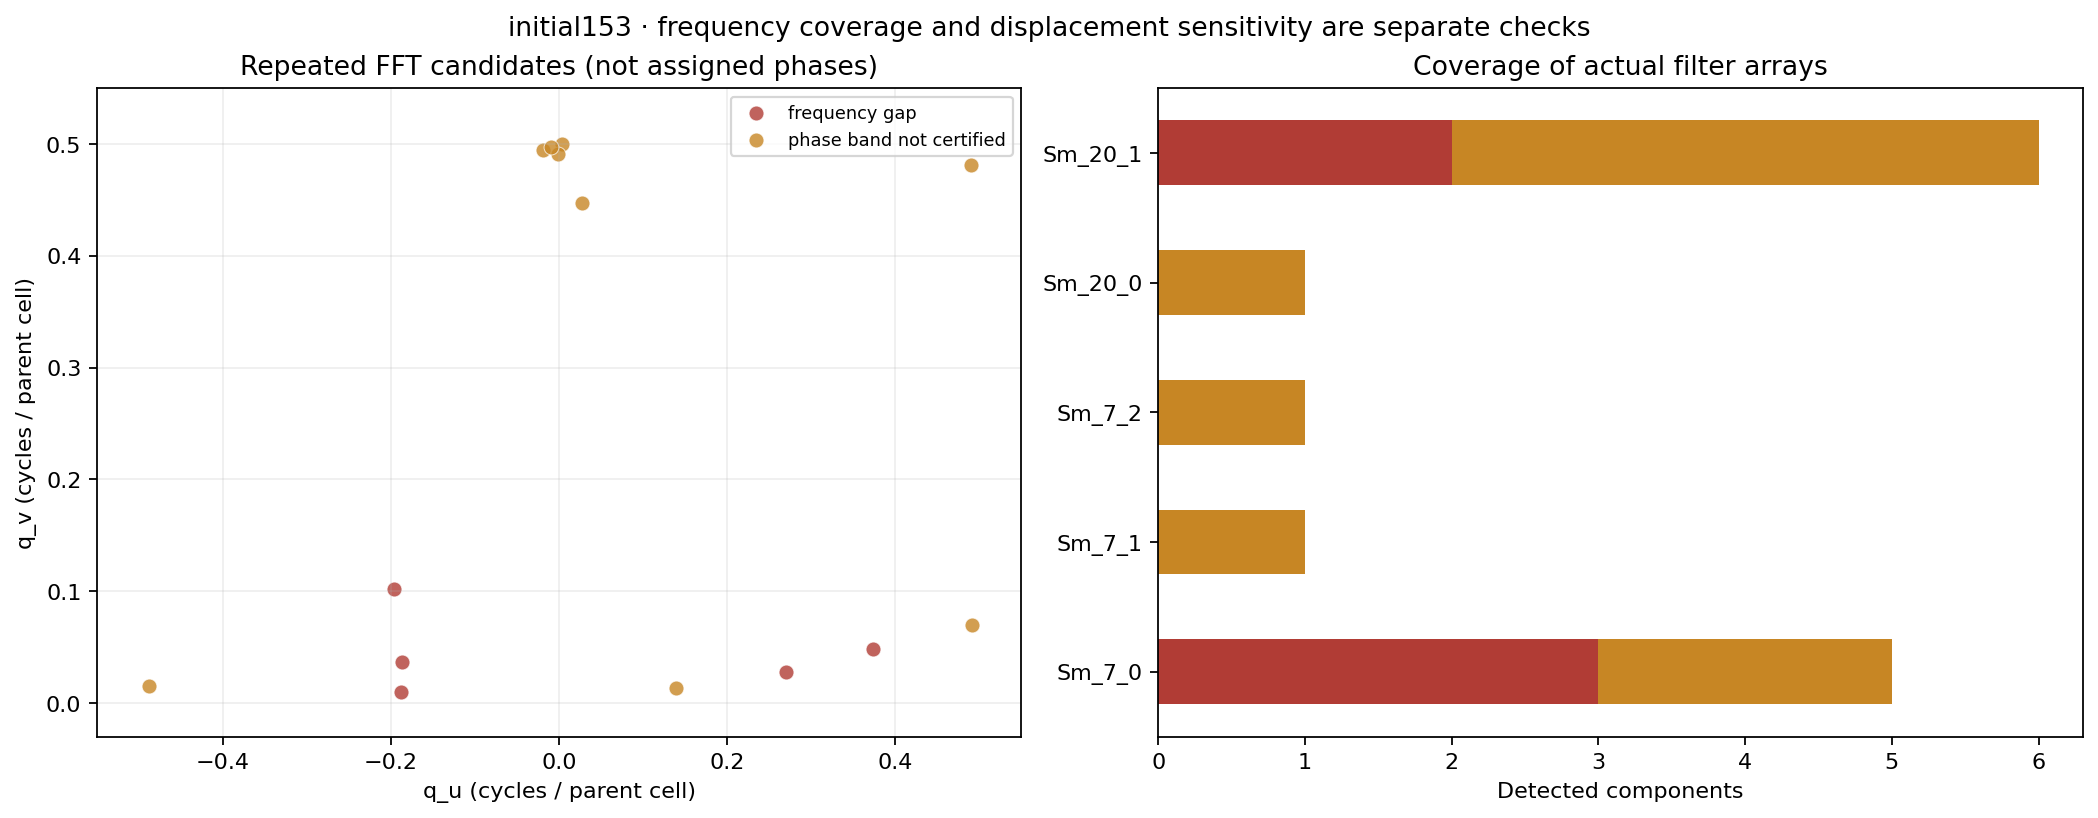

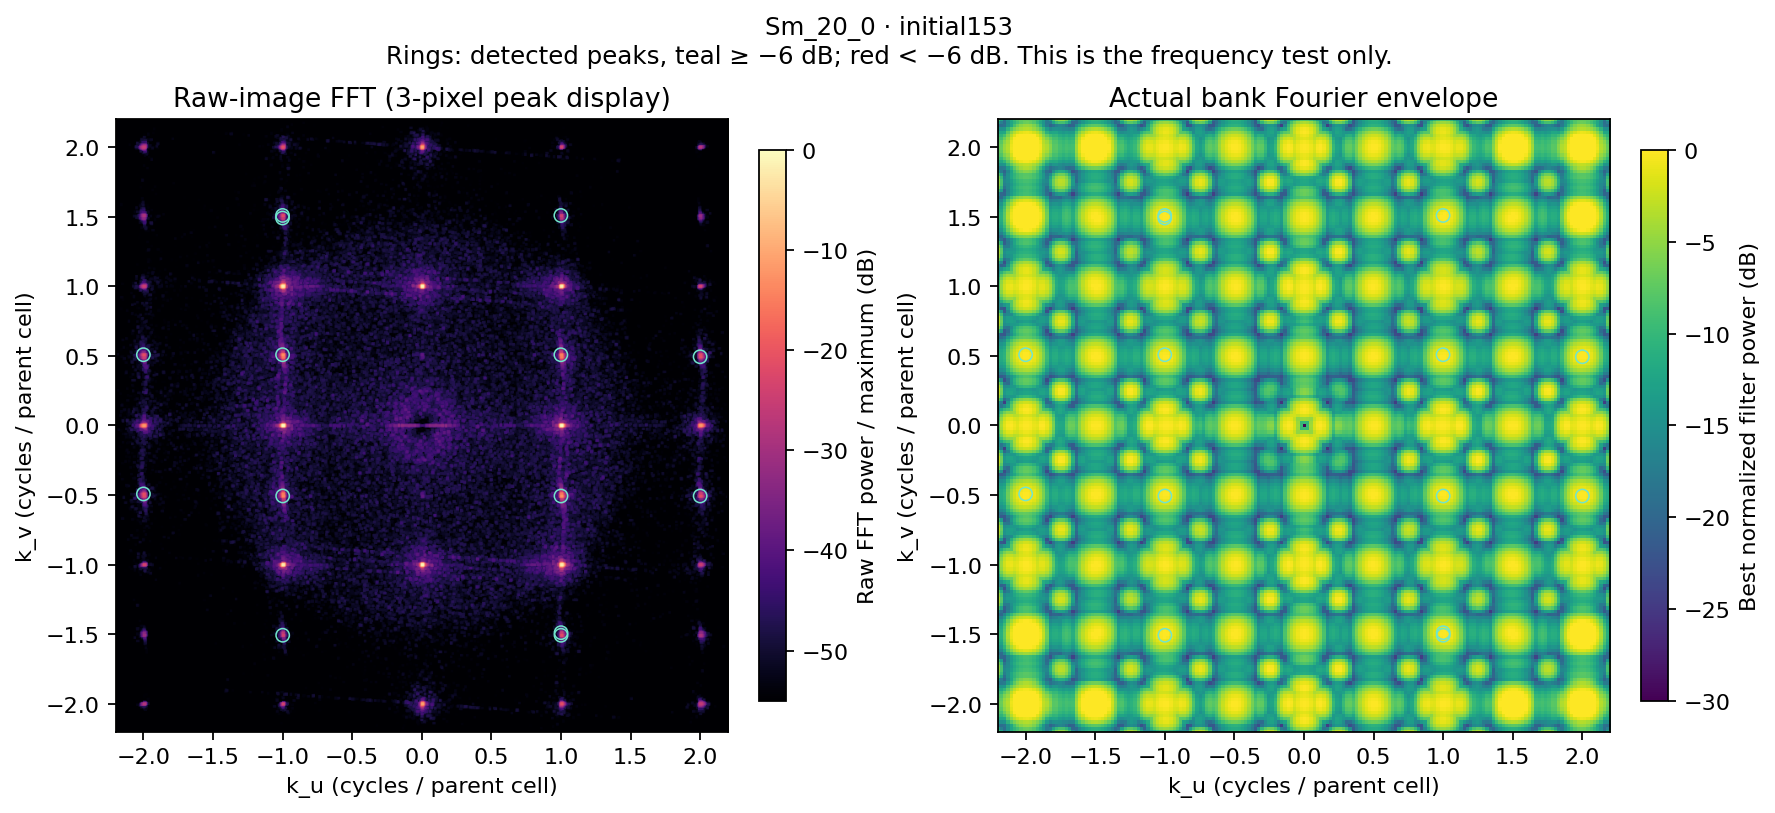

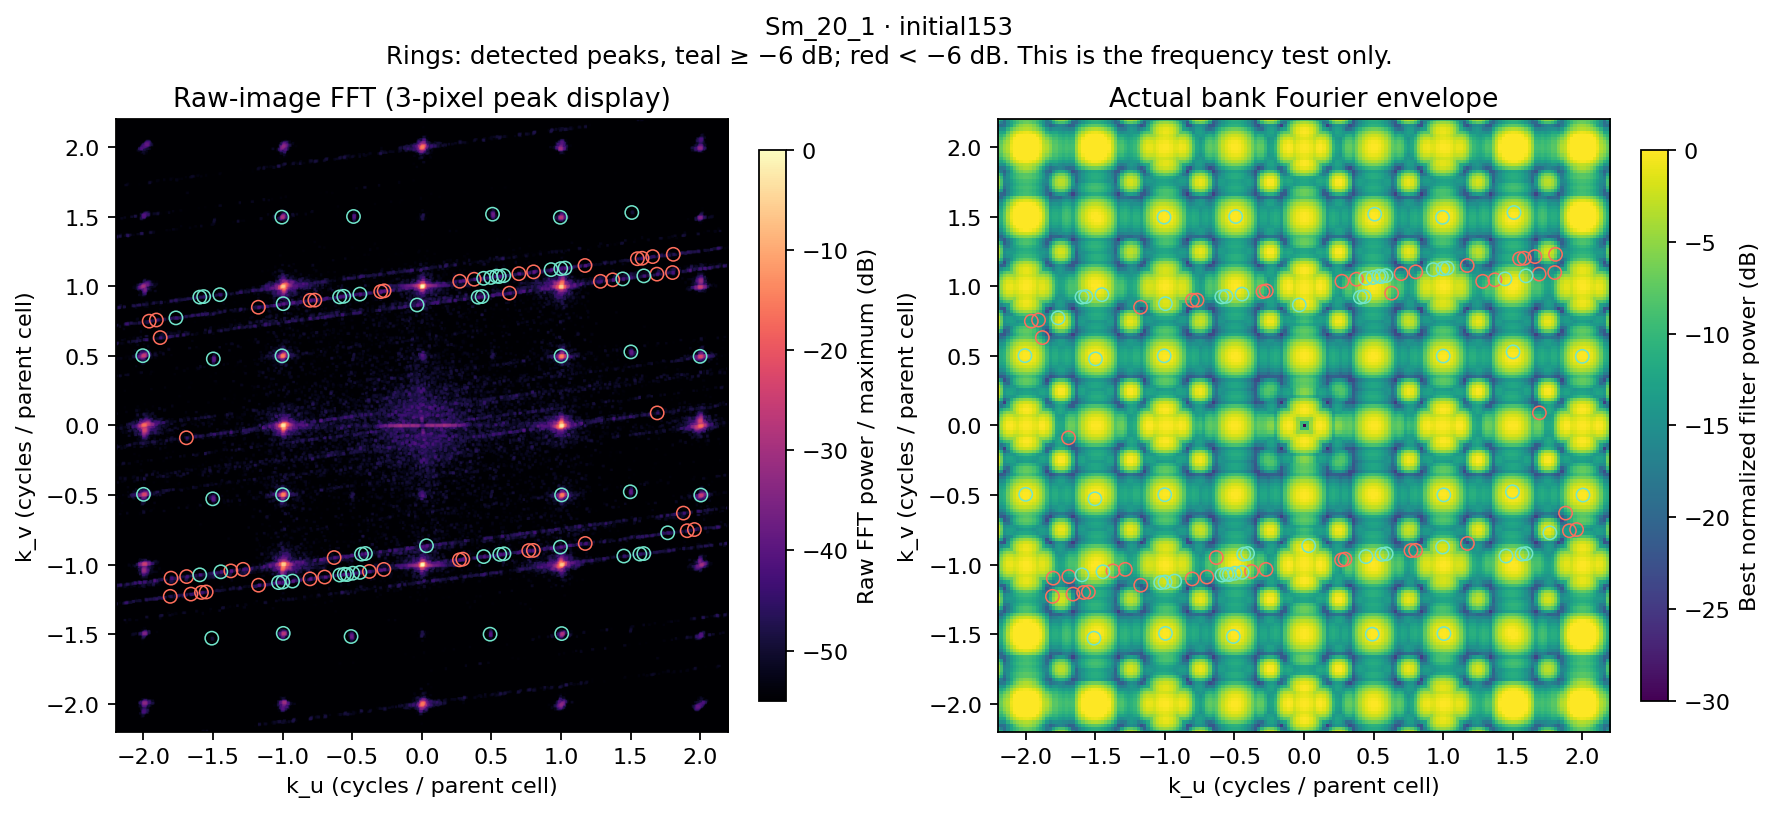

,image,component_id,q_u,q_v,evidence,tiles,carriers,strongest_contrast,q_tolerance,nearest_family,...,stage,spectral_pass,worst_peak_gain_db,fraction_peaks_frequency_covered,nominal_displacement_capture,tolerance_displacement_capture,nominal_A_min,nominal_B_min,status,frequency_guarantee_scope
0,Sm_0_0,Sm_0_0_q00,-0.141215,0.137306,unconfirmed_candidate,1,1,72.822271,0.015625,quarter_minus,...,initial153,False,-13.596572,0.0,0.000229,0.000229,0.001346,0.000229,FREQUENCY_GAP,detected peaks only; current kernels; threshol...
1,Sm_0_0,Sm_0_0_q01,0.026126,0.365163,unconfirmed_candidate,0,1,52.061111,0.006369,half_v,...,initial153,False,-7.109864,0.0,0.000341,0.000283,0.019301,0.000341,FREQUENCY_GAP,detected peaks only; current kernels; threshol...
2,Sm_0_0,Sm_0_0_q02,0.010327,0.143098,unconfirmed_candidate,1,1,51.666157,0.015625,quarter_plus,...,initial153,True,-0.829846,1.0,0.000658,0.000100,0.104030,0.000658,PHASE_BAND_NOT_CERTIFIED,detected peaks only; current kernels; threshol...
3,Sm_0_1,Sm_0_1_q00,0.120981,0.004857,unconfirmed_candidate,0,1,57.825275,0.006061,quarter_plus,...,initial153,True,-0.096665,1.0,0.000059,0.000036,0.131954,0.000059,PHASE_BAND_NOT_CERTIFIED,detected peaks only; current kernels; threshol...
4,Sm_0_2,Sm_0_2_q00,-0.002605,0.499707,unconfirmed_candidate,0,2,71.662538,0.006410,half_v,...,initial153,True,-0.076363,1.0,0.001481,0.001469,0.064652,0.001481,PHASE_BAND_NOT_CERTIFIED,detected peaks only; current kernels; threshol...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116,Sm_20_1,Sm_20_1_q31,-0.120505,0.369585,unconfirmed_candidate,0,1,56.577377,0.005780,quarter_minus,...,initial153,False,-12.660565,0.0,0.000081,0.000031,0.008891,0.000081,FREQUENCY_GAP,detected peaks only; current kernels; threshol...
117,Sm_20_1,Sm_20_1_q32,-0.002941,0.125760,unconfirmed_candidate,0,2,56.105419,0.005780,quarter_minus,...,initial153,True,-1.906774,1.0,0.000018,0.000018,0.114587,0.000018,PHASE_BAND_NOT_CERTIFIED,detected peaks only; current kernels; threshol...
118,Sm_20_1,Sm_20_1_q33,0.315912,0.159694,unconfirmed_candidate,1,1,53.939928,0.015625,quarter_plus,...,initial153,False,-18.369827,0.0,0.002045,0.000765,0.002063,0.014199,FREQUENCY_GAP,detected peaks only; current kernels; threshol...
119,Sm_20_1,Sm_20_1_q34,-0.077423,0.498651,unconfirmed_candidate,1,1,53.643775,0.015625,half_v,...,initial153,True,-1.821642,1.0,0.001116,0.000785,0.015494,0.001116,PHASE_BAND_NOT_CERTIFIED,detected peaks only; current kernels; threshol...


Separate polarization test: {'test': 'Uniform A/B relative displacement; common translations and site intensities projected out in feature space', 'retained_rank': 2, 'worst_residual_capture': 0.33242044232418483, 'polarization_sensitive': True, 'new_frequency_power_fraction_in_periodic_polar_probe': 0.0, 'interpretation': 'Uniform polarization changes the unit-cell motif / complex parent coefficients; a new satellite is not required.', 'reference_labels_used': False}
Conditional completeness decision: {'detected_peak_frequency_coverage': False, 'repeated_candidate_frequency_coverage': False, 'tested_displacement_band_coverage': False, 'search_preselection_uncapped': True, 'universal_completeness_guaranteed': False, 'explanation': 'Only declared detected peaks and finite template probes are tested; undetected/weak/localized peaks and other physical motifs are outside a universal guarantee.'}


In [ ]:
#@title Verify nominal families and audit actual initial filters
FFT_AUDIT_SUMMARIES={}
_initial_bank=ShapeBank(True)
_initial_kernels=_initial_bank.kernels().detach().cpu().numpy().reshape(-1,SIZE,SIZE)
_initial_names=_initial_bank.last_names
for mode in range(3):
    for axis in ['dx','dy']:
        assert f'A_half_s0_mode{mode}_{axis}' in _initial_names
        assert f'B_local_s0_mode{mode+1}_{axis}' in _initial_names
for site in ['A','B']:
    for mode in range(2):
        for phase in range(2):
            for axis in ['dx','dy']:assert f'{site}_quarter{mode}_phase{phase}_s0_{axis}' in _initial_names
_nominal=nominal_mode_audit(_initial_kernels,PPC)
_nominal.to_csv(COVERAGE_DIR/'initial_nominal_modes.csv',index=False);display(_nominal)
assert _nominal.tested_mode_pass.all(), 'An explicitly required exact ordering mode is missing.'
_initial_table,_initial_summary=evaluate_bank(_initial_kernels,RAW_MODES,RAW_PEAKS,COVERAGE_DIR,'initial153',FFT_AUDIT_CONFIG,PPC,REGISTRATION_MODE)
_initial_summary['decision']=audit_completeness_decision(_initial_summary,FFT_DISCOVERY)
FFT_AUDIT_SUMMARIES['initial153']=_initial_summary
plot_coverage(_initial_table,COVERAGE_DIR,'initial153')
display(Image(filename=str(COVERAGE_DIR/'initial153_coverage.png')))
_envelope=np.load(COVERAGE_DIR/'initial153_spectral_envelope.npz')
_peak_response=pd.read_csv(COVERAGE_DIR/'initial153_peak_responses.csv')
for image_name in NAMES:
    _raw=np.load(COVERAGE_DIR/(image_name+'_raw_spectrum.npz'))
    _rows=_peak_response[(_peak_response.image==image_name)&(_peak_response.source=='whole')]
    plot_fft_filter_comparison(_raw,_rows,_envelope['envelope'],_envelope['frequency'],COVERAGE_DIR/(image_name+'_FFT_vs_filters.png'),image_name+' · initial153')
    if image_name.startswith('Sm_20'):display(Image(filename=str(COVERAGE_DIR/(image_name+'_FFT_vs_filters.png'))))
display(_initial_table);print('Separate polarization test:',_initial_summary['polarization'])
print('Conditional completeness decision:',_initial_summary['decision'])
if STRICT_FFT_COVERAGE and not (_initial_summary['decision']['tested_displacement_band_coverage'] and _initial_summary['decision']['search_preselection_uncapped']):
    raise RuntimeError('Coverage is not certified. Inspect the gap table and extend the bank/simulator; do not interpret this as a complete phase detector.')


In [ ]:
MODELS={'expanded153':train_synthetic(True)}
if TRAIN_87_BASELINE:MODELS['baseline87']=train_synthetic(False)
MODEL=MODELS['expanded153']['model'];STATS=MODELS['expanded153']['stats'];MODEL_SHA=MODELS['expanded153']['sha256']
print('Models are frozen. No experimental reference arrays have been opened.')


expanded153: epoch 01, train 0.7395, synthetic validation 0.4661, 10.1s
expanded153: epoch 02, train 0.3594, synthetic validation 0.2780, 9.6s
expanded153: epoch 03, train 0.2379, synthetic validation 0.1971, 9.7s
expanded153: epoch 04, train 0.1840, synthetic validation 0.1629, 9.6s
expanded153: epoch 05, train 0.1576, synthetic validation 0.1420, 9.7s
expanded153: epoch 06, train 0.1423, synthetic validation 0.1312, 10.0s
expanded153: epoch 07, train 0.1324, synthetic validation 0.1283, 9.9s
expanded153: epoch 08, train 0.1266, synthetic validation 0.1246, 9.7s
expanded153: epoch 09, train 0.1226, synthetic validation 0.1180, 9.9s
expanded153: epoch 10, train 0.1179, synthetic validation 0.1194, 9.9s
expanded153: epoch 11, train 0.1156, synthetic validation 0.1115, 9.9s
expanded153: epoch 12, train 0.1117, synthetic validation 0.1087, 9.9s
expanded153: epoch 13, train 0.1095, synthetic validation 0.1075, 9.8s
expanded153: epoch 14, train 0.1069, synthetic validation 0.1028, 9.9s
expa

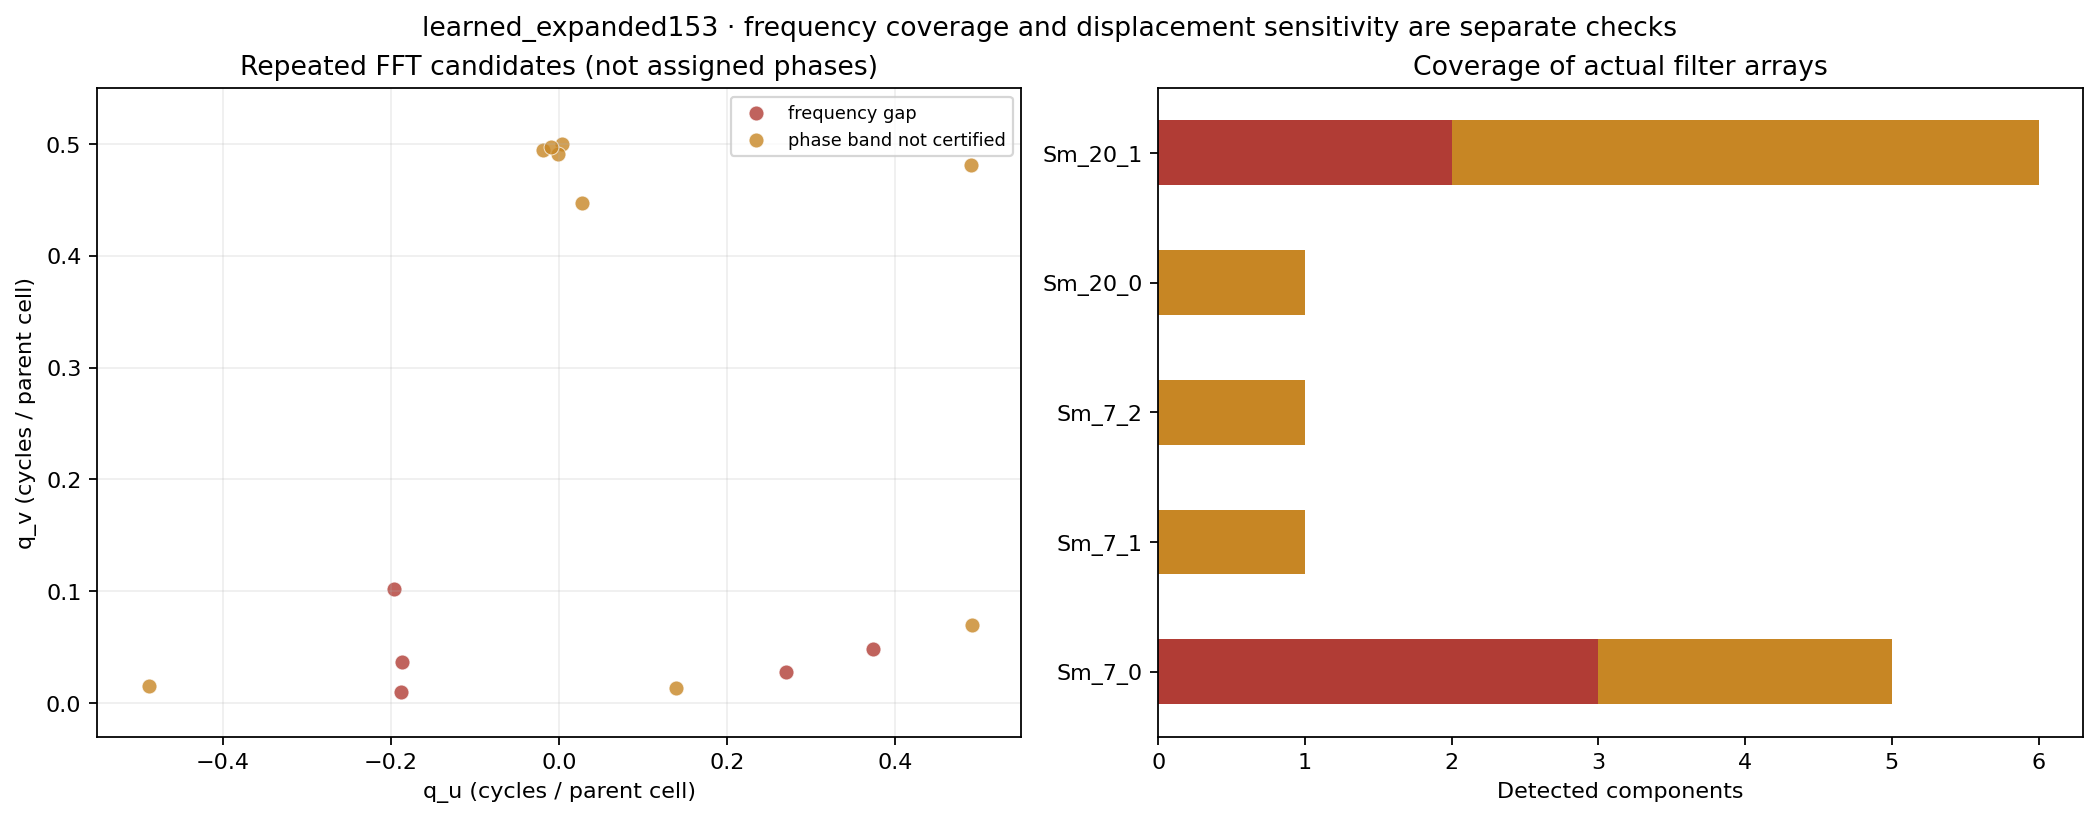

,image,component_id,q_u,q_v,evidence,tiles,carriers,strongest_contrast,q_tolerance,nearest_family,...,stage,spectral_pass,worst_peak_gain_db,fraction_peaks_frequency_covered,nominal_displacement_capture,tolerance_displacement_capture,nominal_A_min,nominal_B_min,status,frequency_guarantee_scope
0,Sm_0_0,Sm_0_0_q00,-0.141215,0.137306,unconfirmed_candidate,1,1,72.822271,0.015625,quarter_minus,...,learned_expanded153,False,-13.091554,0.0,0.000232,0.000232,0.001359,0.000249,FREQUENCY_GAP,detected peaks only; current kernels; threshol...
1,Sm_0_0,Sm_0_0_q01,0.026126,0.365163,unconfirmed_candidate,0,1,52.061111,0.006369,half_v,...,learned_expanded153,False,-6.997920,0.0,0.000395,0.000320,0.018016,0.000462,FREQUENCY_GAP,detected peaks only; current kernels; threshol...
2,Sm_0_0,Sm_0_0_q02,0.010327,0.143098,unconfirmed_candidate,1,1,51.666157,0.015625,quarter_plus,...,learned_expanded153,True,-0.769927,1.0,0.001014,0.000420,0.099764,0.001026,PHASE_BAND_NOT_CERTIFIED,detected peaks only; current kernels; threshol...
3,Sm_0_1,Sm_0_1_q00,0.120981,0.004857,unconfirmed_candidate,0,1,57.825275,0.006061,quarter_plus,...,learned_expanded153,True,-0.131094,1.0,0.000305,0.000279,0.127164,0.000306,PHASE_BAND_NOT_CERTIFIED,detected peaks only; current kernels; threshol...
4,Sm_0_2,Sm_0_2_q00,-0.002605,0.499707,unconfirmed_candidate,0,2,71.662538,0.006410,half_v,...,learned_expanded153,True,-0.026906,1.0,0.001598,0.001195,0.060435,0.001599,PHASE_BAND_NOT_CERTIFIED,detected peaks only; current kernels; threshol...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116,Sm_20_1,Sm_20_1_q31,-0.120505,0.369585,unconfirmed_candidate,0,1,56.577377,0.005780,quarter_minus,...,learned_expanded153,False,-12.706681,0.0,0.000055,0.000032,0.008335,0.000076,FREQUENCY_GAP,detected peaks only; current kernels; threshol...
117,Sm_20_1,Sm_20_1_q32,-0.002941,0.125760,unconfirmed_candidate,0,2,56.105419,0.005780,quarter_minus,...,learned_expanded153,True,-2.619411,1.0,0.000348,0.000346,0.109835,0.000364,PHASE_BAND_NOT_CERTIFIED,detected peaks only; current kernels; threshol...
118,Sm_20_1,Sm_20_1_q33,0.315912,0.159694,unconfirmed_candidate,1,1,53.939928,0.015625,quarter_plus,...,learned_expanded153,False,-18.551176,0.0,0.002232,0.000459,0.002282,0.014058,FREQUENCY_GAP,detected peaks only; current kernels; threshol...
119,Sm_20_1,Sm_20_1_q34,-0.077423,0.498651,unconfirmed_candidate,1,1,53.643775,0.015625,half_v,...,learned_expanded153,True,-1.873223,1.0,0.001171,0.000807,0.014879,0.001171,PHASE_BAND_NOT_CERTIFIED,detected peaks only; current kernels; threshol...


learned_expanded153 {'detected_peak_frequency_coverage': False, 'repeated_candidate_frequency_coverage': False, 'tested_displacement_band_coverage': False, 'search_preselection_uncapped': True, 'universal_completeness_guaranteed': False, 'explanation': 'Only declared detected peaks and finite template probes are tested; undetected/weak/localized peaks and other physical motifs are outside a universal guarantee.'} ; polarization: {'test': 'Uniform A/B relative displacement; common translations and site intensities projected out in feature space', 'retained_rank': 2, 'worst_residual_capture': 0.3215779159251371, 'polarization_sensitive': True, 'new_frequency_power_fraction_in_periodic_polar_probe': 0.0, 'interpretation': 'Uniform polarization changes the unit-cell motif / complex parent coefficients; a new satellite is not required.', 'reference_labels_used': False}


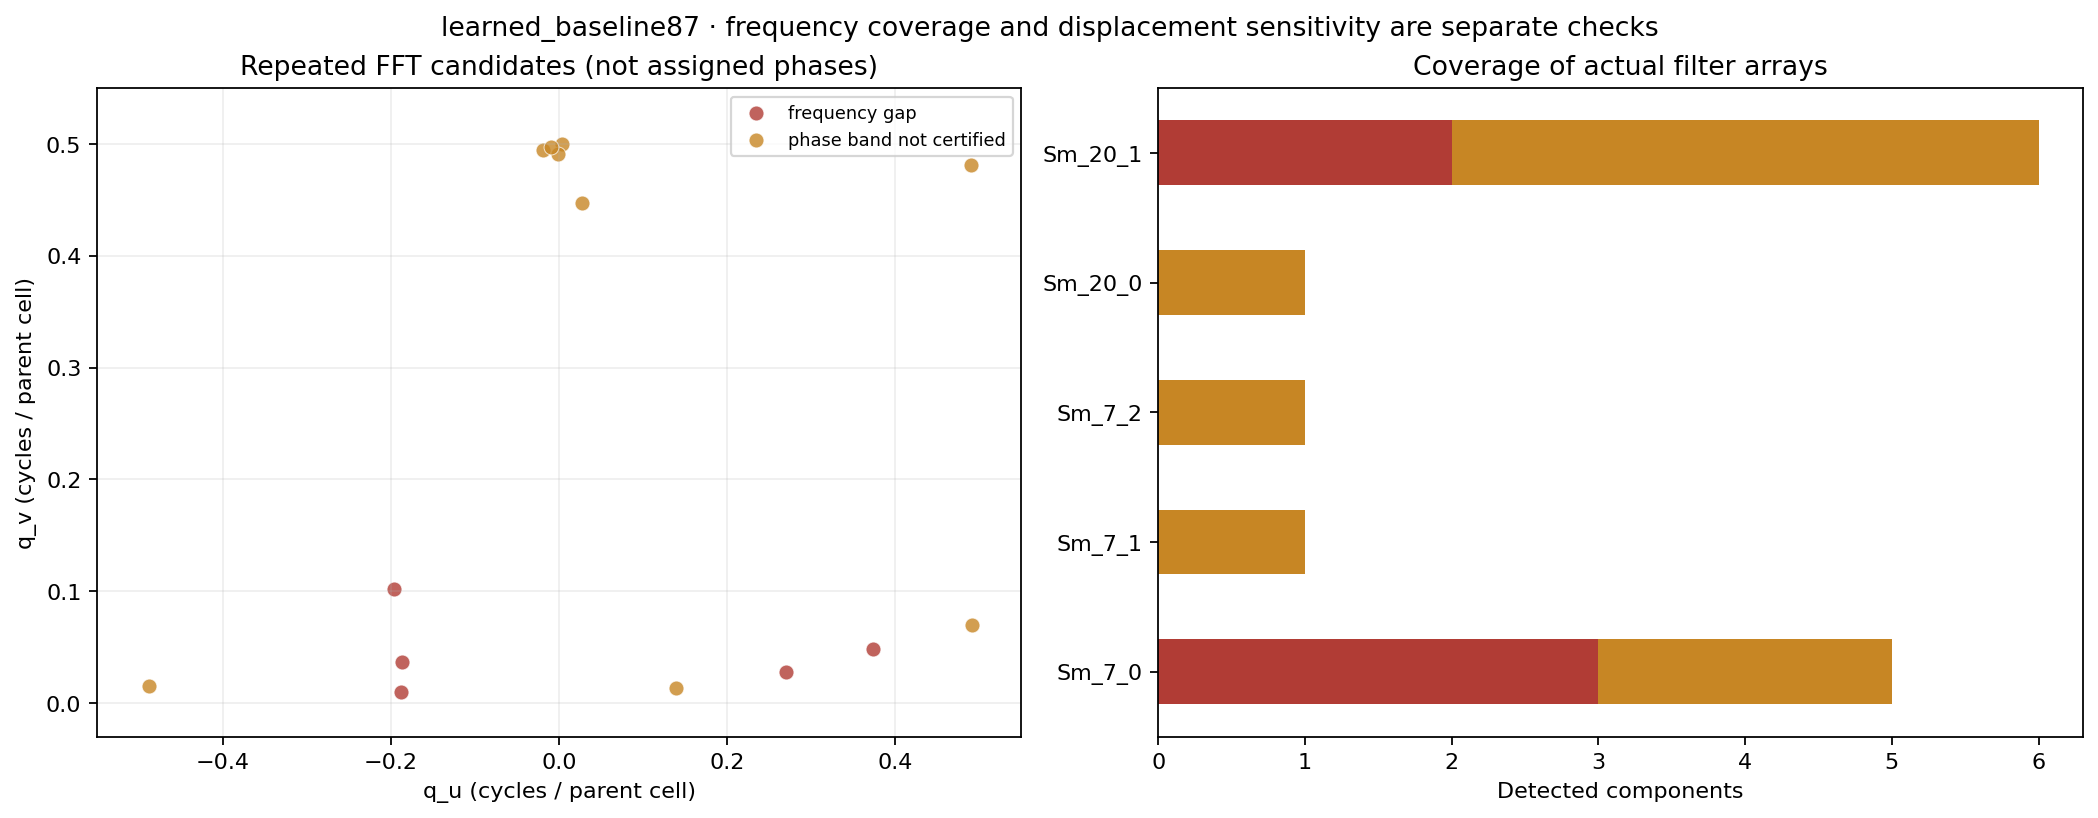

,image,component_id,q_u,q_v,evidence,tiles,carriers,strongest_contrast,q_tolerance,nearest_family,...,stage,spectral_pass,worst_peak_gain_db,fraction_peaks_frequency_covered,nominal_displacement_capture,tolerance_displacement_capture,nominal_A_min,nominal_B_min,status,frequency_guarantee_scope
0,Sm_0_0,Sm_0_0_q00,-0.141215,0.137306,unconfirmed_candidate,1,1,72.822271,0.015625,quarter_minus,...,learned_baseline87,False,-11.613597,0.0,0.001430,0.000985,0.003221,0.001469,FREQUENCY_GAP,detected peaks only; current kernels; threshol...
1,Sm_0_0,Sm_0_0_q01,0.026126,0.365163,unconfirmed_candidate,0,1,52.061111,0.006369,half_v,...,learned_baseline87,False,-7.236987,0.0,0.000991,0.000966,0.010890,0.004903,FREQUENCY_GAP,detected peaks only; current kernels; threshol...
2,Sm_0_0,Sm_0_0_q02,0.010327,0.143098,unconfirmed_candidate,1,1,51.666157,0.015625,quarter_plus,...,learned_baseline87,True,-1.197818,1.0,0.008976,0.004829,0.079453,0.012328,PHASE_BAND_NOT_CERTIFIED,detected peaks only; current kernels; threshol...
3,Sm_0_1,Sm_0_1_q00,0.120981,0.004857,unconfirmed_candidate,0,1,57.825275,0.006061,quarter_plus,...,learned_baseline87,True,-0.062475,1.0,0.013196,0.012686,0.111126,0.013545,PHASE_BAND_NOT_CERTIFIED,detected peaks only; current kernels; threshol...
4,Sm_0_2,Sm_0_2_q00,-0.002605,0.499707,unconfirmed_candidate,0,2,71.662538,0.006410,half_v,...,learned_baseline87,True,-0.113090,1.0,0.000360,0.000270,0.001875,0.000742,PHASE_BAND_NOT_CERTIFIED,detected peaks only; current kernels; threshol...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116,Sm_20_1,Sm_20_1_q31,-0.120505,0.369585,unconfirmed_candidate,0,1,56.577377,0.005780,quarter_minus,...,learned_baseline87,False,-14.940887,0.0,0.001086,0.000996,0.005572,0.002407,FREQUENCY_GAP,detected peaks only; current kernels; threshol...
117,Sm_20_1,Sm_20_1_q32,-0.002941,0.125760,unconfirmed_candidate,0,2,56.105419,0.005780,quarter_minus,...,learned_baseline87,True,-2.673667,1.0,0.010644,0.010444,0.092817,0.013263,PHASE_BAND_NOT_CERTIFIED,detected peaks only; current kernels; threshol...
118,Sm_20_1,Sm_20_1_q33,0.315912,0.159694,unconfirmed_candidate,1,1,53.939928,0.015625,quarter_plus,...,learned_baseline87,False,-23.030618,0.0,0.000191,0.000120,0.000427,0.000464,FREQUENCY_GAP,detected peaks only; current kernels; threshol...
119,Sm_20_1,Sm_20_1_q34,-0.077423,0.498651,unconfirmed_candidate,1,1,53.643775,0.015625,half_v,...,learned_baseline87,True,-2.334175,1.0,0.000533,0.000416,0.002783,0.001260,PHASE_BAND_NOT_CERTIFIED,detected peaks only; current kernels; threshol...


learned_baseline87 {'detected_peak_frequency_coverage': False, 'repeated_candidate_frequency_coverage': False, 'tested_displacement_band_coverage': False, 'search_preselection_uncapped': True, 'universal_completeness_guaranteed': False, 'explanation': 'Only declared detected peaks and finite template probes are tested; undetected/weak/localized peaks and other physical motifs are outside a universal guarantee.'} ; polarization: {'test': 'Uniform A/B relative displacement; common translations and site intensities projected out in feature space', 'retained_rank': 2, 'worst_residual_capture': 0.3274290506895852, 'polarization_sensitive': True, 'new_frequency_power_fraction_in_periodic_polar_probe': 0.0, 'interpretation': 'Uniform polarization changes the unit-cell motif / complex parent coefficients; a new satellite is not required.', 'reference_labels_used': False}


In [ ]:
#@title Recheck learned banks: filter settings may drift during training
for name,bundle in MODELS.items():
    k=bundle['model'].bank.kernels().detach().cpu().numpy().reshape(-1,SIZE,SIZE)
    stage='learned_'+name
    table,summary=evaluate_bank(k,RAW_MODES,RAW_PEAKS,COVERAGE_DIR,stage,FFT_AUDIT_CONFIG,PPC,REGISTRATION_MODE)
    summary['model_sha256']=bundle['sha256'];summary['decision']=audit_completeness_decision(summary,FFT_DISCOVERY)
    FFT_AUDIT_SUMMARIES[stage]=summary
    nominal_mode_audit(k,PPC).to_csv(COVERAGE_DIR/(stage+'_nominal_modes.csv'),index=False)
    plot_coverage(table,COVERAGE_DIR,stage);display(Image(filename=str(COVERAGE_DIR/(stage+'_coverage.png'))))
    display(table);print(stage,summary['decision'],'; polarization:',summary['polarization'])
    if STRICT_FFT_COVERAGE and name=='expanded153' and not (summary['decision']['tested_displacement_band_coverage'] and summary['decision']['search_preselection_uncapped']):
        raise RuntimeError('Learned expanded bank does not satisfy the declared coverage criterion.')
audit_json(COVERAGE_DIR/'all_stage_summaries.json',FFT_AUDIT_SUMMARIES)
audit('learned_filter_coverage_checked',reference_arrays_loaded=False)


## 5. Independent synthetic tests and stress tests

Report component RMSE, group RMSE, and phase-combined amplitudes for all three output groups (P, A and B). For a quarter mode,
\[
\eta_{\mathrm{amp}}=\sqrt{\|\boldsymbol\eta_{\cos}\|^2+\|\boldsymbol\eta_{\sin}\|^2}.
\]

This is the norm of the quadrature coefficients, invariant to a change of modulation origin at the nominal wavevector. It is not automatically the peak vector displacement for every elliptical modulation.

Detection thresholds use the 99th percentile of predictions on synthetic-validation null examples. Test F1 excludes the intermediate amplitude interval between the specified null and active definitions; counts are saved. If too few validation nulls exist, the threshold and F1 are left undefined rather than inferred from experimental labels.

,model,split,target_group,RMSE_parent_units
0,expanded153,test,local,0.012065
1,expanded153,test,P_uniform,0.009053
2,expanded153,test,P_order,0.004110
3,expanded153,test,A_order,0.002574
4,expanded153,test,B_order,0.003992
5,expanded153,stress,local,0.016799
6,expanded153,stress,P_uniform,0.012841
7,expanded153,stress,P_order,0.004902
8,expanded153,stress,A_order,0.002557
9,expanded153,stress,B_order,0.004830


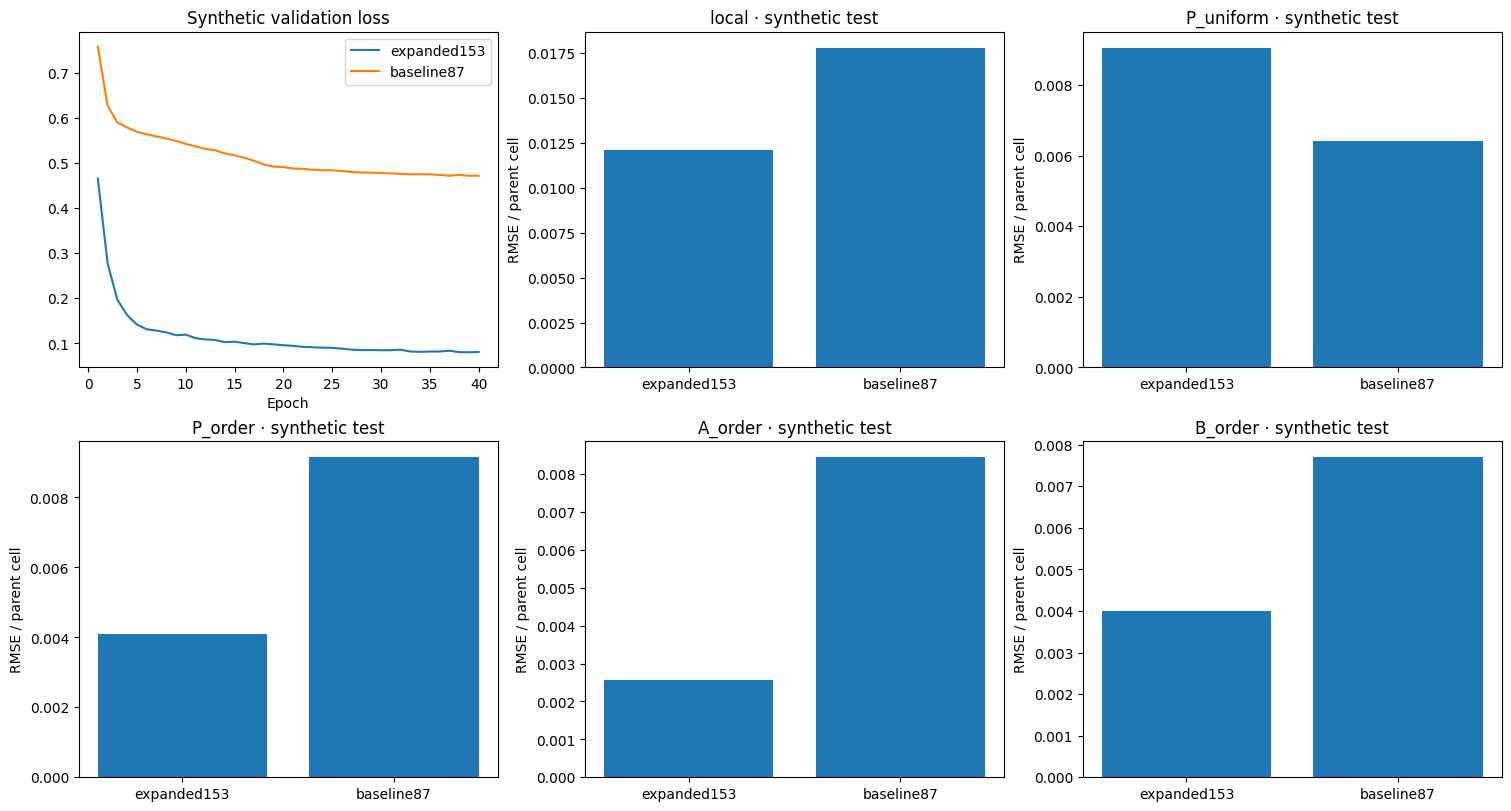

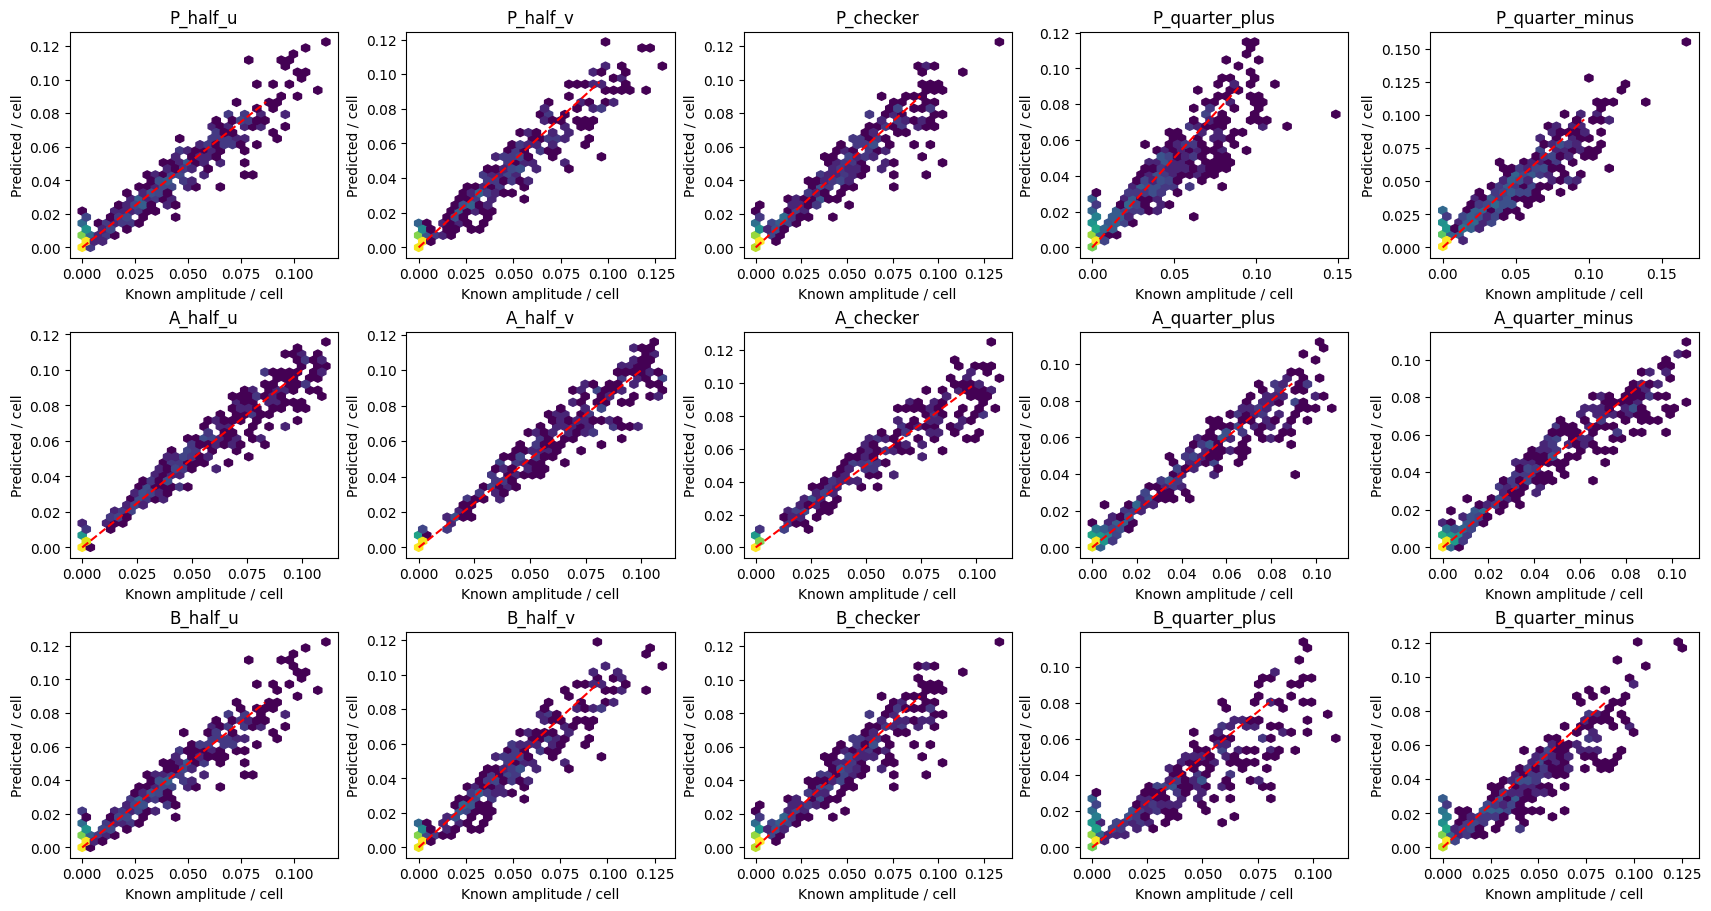

In [ ]:
#@title 7. Synthetic tests, stress tests, and the 87-filter ablation
def regression_metrics(truth,prediction):
    error=prediction-truth
    correlations=[float(np.corrcoef(truth[:,j],prediction[:,j])[0,1]) if truth[:,j].std()>1e-9 and prediction[:,j].std()>1e-9 else None for j in range(truth.shape[1])]
    return {'n':len(truth),'rmse':np.sqrt(np.mean(error**2,axis=0)).tolist(),'mae':np.mean(abs(error),axis=0).tolist(),
            'bias':error.mean(0).tolist(),'pearson':correlations}

def to_physical(canonical,bases,pm):
    vectors=canonical.reshape(len(canonical),-1,2)/PPC
    p=np.asarray(pm)
    if p.ndim==1:p=np.broadcast_to(p,(len(canonical),2))
    return np.einsum('nij,nmj->nmi',bases,vectors)*p[:,None,:]

AMP_NAMES=[f'{s}_{m}' for s in ['P','A','B'] for m in ['half_u','half_v','checker','quarter_plus','quarter_minus']]
AMP_GROUPS=[]
for start in [2,9,16]:AMP_GROUPS.extend([[start],[start+1],[start+2],[start+3,start+4],[start+5,start+6]])
def order_amplitudes(vectors):
    return np.stack([np.sqrt(np.sum(vectors[:,ids,:]**2,axis=(1,2))) for ids in AMP_GROUPS],axis=1)

SYNTH_RESULTS={};THRESHOLDS={};metric_rows=[]
for name,bundle in MODELS.items():
    vp=network_predict(bundle['model'],DATASETS['validation']['images'],bundle['stats'])
    truth_amp=order_amplitudes(DATASETS['validation']['labels'].reshape(-1,23,2))
    pred_amp=order_amplitudes(vp.reshape(-1,23,2));thresholds=[]
    for j in range(15):
        null=truth_amp[:,j]<.01*PPC
        if null.sum()<20:thresholds.append(float('nan'))
        else:thresholds.append(float(np.quantile(pred_amp[null,j],.99)))
    THRESHOLDS[name]=np.array(thresholds)
    atomic_json(bundle['folder']/'thresholds.json',{'source':'synthetic validation only','amplitude_names':AMP_NAMES,'canonical_px':thresholds})
    SYNTH_RESULTS[name]={}
    for split in ['test','stress']:
        d=DATASETS[split];pred=network_predict(bundle['model'],d['images'],bundle['stats'])
        gt=d['labels'];ta=order_amplitudes(gt.reshape(-1,23,2));pa=order_amplitudes(pred.reshape(-1,23,2));detections=[]
        for j,label in enumerate(AMP_NAMES):
            valid=(ta[:,j]<.01*PPC)|(ta[:,j]>.025*PPC);active=ta[:,j]>.025*PPC
            guess=pa[:,j]>THRESHOLDS[name][j];tp=int((guess&active&valid).sum());fp=int((guess&~active&valid).sum());fn=int((~guess&active&valid).sum())
            detections.append({'name':label,'known_null_or_active':int(valid.sum()),'ambiguous_excluded':int((~valid).sum()),
                'f1':float(2*tp/max(2*tp+fp+fn,1)) if np.isfinite(THRESHOLDS[name][j]) else None})
        phys_true=to_physical(gt,d['bases'],d['metadata'][:,:2]);phys_pred=to_physical(pred,d['bases'],d['metadata'][:,:2])
        m=regression_metrics(gt,pred)
        SYNTH_RESULTS[name][split]={'canonical_px':m,'local_pm':regression_metrics(phys_true[:,0],phys_pred[:,0]),'detection':detections}
        atomic_npz(bundle['folder']/(split+'_predictions.npz'),reference=gt,prediction=pred,seeds=d['seeds'])
        for label,sl in TARGET_GROUPS.items():metric_rows.append({'model':name,'split':split,'target_group':label,'RMSE_parent_units':float(np.sqrt(np.mean((pred[:,sl]-gt[:,sl])**2)))/PPC})
atomic_json(MODEL_DIR/'synthetic_metrics.json',SYNTH_RESULTS)
SYNTHETIC_TABLE=pd.DataFrame(metric_rows);SYNTHETIC_TABLE.to_csv(MODEL_DIR/'synthetic_group_metrics.csv',index=False);display(SYNTHETIC_TABLE)
fig,axes=plt.subplots(2,3,figsize=(15,8),layout='constrained')
for name,bundle in MODELS.items():
    h=pd.DataFrame(bundle['history']);axes[0,0].plot(h.epoch,h.validation_loss,label=name)
axes[0,0].set_title('Synthetic validation loss');axes[0,0].set_xlabel('Epoch');axes[0,0].legend()
for ax,group in zip(axes.flat[1:],TARGET_GROUPS):
    rows=SYNTHETIC_TABLE[(SYNTHETIC_TABLE.target_group==group)&(SYNTHETIC_TABLE.split=='test')]
    ax.bar(rows.model,rows.RMSE_parent_units);ax.set_title(group+' · synthetic test');ax.set_ylabel('RMSE / parent cell')
save_figure(fig,PROJECT_ROOT/'figures'/'03_synthetic_ablation.png');plt.show();plt.close(fig)
fig,axes=plt.subplots(3,5,figsize=(17,9),layout='constrained')
d=np.load(MODELS['expanded153']['folder']/'test_predictions.npz');ta=order_amplitudes(d['reference'].reshape(-1,23,2))/PPC;pa=order_amplitudes(d['prediction'].reshape(-1,23,2))/PPC
for j,ax in enumerate(axes.flat):
    ax.hexbin(ta[:,j],pa[:,j],gridsize=30,mincnt=1,bins='log');lim=max(.05,np.percentile(np.r_[ta[:,j],pa[:,j]],99))
    ax.plot([0,lim],[0,lim],'r--');ax.set_title(AMP_NAMES[j]);ax.set_xlabel('Known amplitude / cell');ax.set_ylabel('Predicted / cell')
save_figure(fig,PROJECT_ROOT/'figures'/'04_synthetic_ordering_amplitudes.png');plt.show();plt.close(fig)
audit('synthetic_tests_complete',reference_arrays_loaded=False,threshold_source='synthetic validation only')


## 6. Inspect what the filters learned

The following plots compare initial and final analytical kernels and report their geometric settings. The complete 153-filter montage and channel names are also saved. These are feature filters; their widths and spacings are not interchangeable with the predicted physical ordering amplitudes.

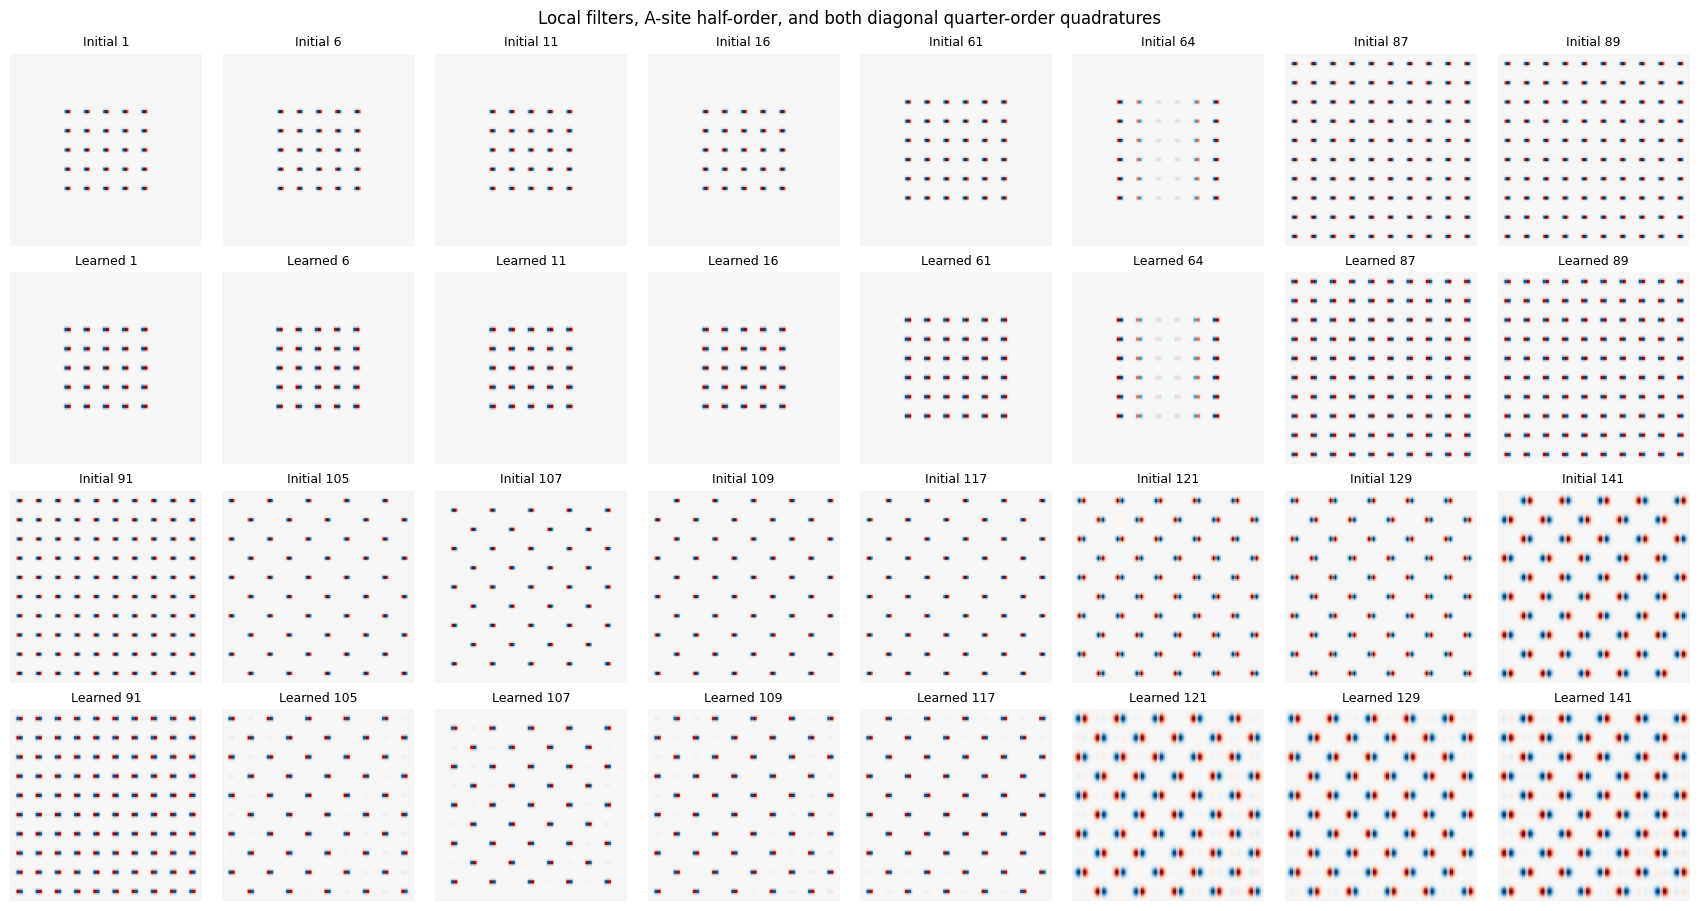

,parameter,learned
0,sigma_px,"[0.9138761758804321, 1.8253389596939087, 2.003..."
1,aspect,"[1.042330265045166, 1.0901447534561157, 1.0018..."
2,spacing_px,"[11.999872207641602, 12.009169578552246]"
3,offset_px,"[-0.015582534484565258, -0.013468055985867977]"
4,kernel_rotation_degrees,0.049168
5,quarter_q,"[[0.24757958948612213, 0.2490420639514923], [-..."


The full 153-filter montage and filter names are saved with the trained model.


In [ ]:
#@title 8. Inspect analytical kernels and learned geometry
bundle=MODELS['expanded153'];kernel=bundle['model'].bank.kernels().detach().cpu().numpy().reshape(153,SIZE,SIZE)
initial=bundle['checkpoint']['initial_kernels'].reshape(153,SIZE,SIZE)
selection=[1,6,11,16,61,64,87,89,91,105,107,109,117,121,129,141]
fig,axes=plt.subplots(4,8,figsize=(17,9),layout='constrained')
for j,k in enumerate(selection):
    for row,z in enumerate([initial[k],kernel[k]]):
        ax=axes[(j//8)*2+row,j%8];lim=max(abs(z).max(),1e-8)
        ax.imshow(z,cmap='RdBu_r',vmin=-lim,vmax=lim);ax.axis('off');ax.set_title(('Initial ' if row==0 else 'Learned ')+str(k),fontsize=9)
fig.suptitle('Local filters, A-site half-order, and both diagonal quarter-order quadratures')
save_figure(fig,PROJECT_ROOT/'figures'/'05_learned_filters.png');plt.show();plt.close(fig)
display(pd.DataFrame({'parameter':list(bundle['model'].bank.settings()),'learned':list(bundle['model'].bank.settings().values())}))
fig,axes=plt.subplots(9,17,figsize=(22,12),layout='constrained')
for j,ax in enumerate(axes.flat):
    z=kernel[j];ax.imshow(z,cmap='RdBu_r',vmin=-abs(z).max(),vmax=abs(z).max());ax.set_title(str(j),fontsize=7);ax.axis('off')
save_figure(fig,PROJECT_ROOT/'figures'/'06_all_153_filters.png');plt.close(fig)
print('The full 153-filter montage and filter names are saved with the trained model.')


## 7. Apply the frozen models to all complete experimental images

Every experimental image is analyzed at its native resolution. Raw-image A columns define candidate cells and local frames. The model evaluates a local neighborhood at **every supported detected cell across the complete field**. This is whole-image inference using sliding lattice neighborhoods; it is not training on experimental patches.

Borders, nonfinite neighborhoods and failed support are recorded explicitly. Preview images alone are downsampled for plotting; model inputs are sampled from the original image. Predictions include signed coefficients, phase-combined amplitudes, cell coordinates and local bases. The baseline and expanded model use identical image neighborhoods.

All predictions are saved and checksummed before the notebook enables reference access. Their model hashes are checked again after evaluation.

In [ ]:
#@title 9. Frozen models: analyze every supported cell in all 14 complete images
PREDICTION_MANIFEST=[]
for name,bundle in MODELS.items():
    assert not any(p.requires_grad for p in bundle['model'].parameters())
    assert file_hash(bundle['folder']/'best.pt','sha256')==bundle['sha256']
    with torch.no_grad():bundle['inference_kernels']=bundle['model'].bank.kernels().detach()
    (RUN_DIR/name).mkdir(exist_ok=True)

for pair,cal in zip(PAIRS,CALIBRATION):
    image_name=pair['id'];pending=[]
    for name,bundle in MODELS.items():
        folder=RUN_DIR/name;path=folder/(image_name+'.npz');meta_path=folder/(image_name+'.json')
        if path.exists() and meta_path.exists():
            meta=json.loads(meta_path.read_text())
            assert meta['model_sha256']==bundle['sha256']
            assert meta['prediction_sha256']==file_hash(path,'sha256')
            PREDICTION_MANIFEST.append(meta)
        else:pending.append(name)
    if not pending:continue
    im,pm=load_image(pair);B=np.array(cal['basis_px'],float)
    centers,local_bases,_,_,_=locate_cells(im,B,strict=False)
    bases=np.broadcast_to(B,(len(centers),2,2)).copy() # Retain ordering geometry; do not locally affine-warp it away.
    if len(centers)<30:raise RuntimeError(image_name+': too few image-only lattice cells')
    indices=[];values={name:[] for name in pending};status=np.zeros(len(centers),np.uint8)
    meanpatch=np.zeros((SIZE,SIZE),np.float64);count=0
    for start in tqdm(range(0,len(centers),INFERENCE_BATCH_SIZE),desc=image_name+' full image'):
        ids=np.arange(start,min(start+INFERENCE_BATCH_SIZE,len(centers)))
        patches=sample_patches(im,centers[ids],bases[ids]);finite=np.isfinite(patches).all((1,2))
        nonflat=np.zeros(len(ids),bool);nonflat[finite]=patches[finite].std((1,2))>1e-6
        good=finite&nonflat;status[ids[~finite]]=1;status[ids[finite&~nonflat]]=2
        if not good.any():continue
        indices.append(ids[good]);x=patches[good]
        for name in pending:
            b=MODELS[name];values[name].append(network_predict(b['model'],x,b['stats'],b['inference_kernels']))
        norm=(x-x.mean((1,2),keepdims=True))/(x.std((1,2),keepdims=True)+1e-8);meanpatch+=norm.sum(0);count+=len(x)
    if not indices:raise RuntimeError(image_name+': no finite supported neighborhoods')
    idx=np.concatenate(indices);step=max(1,math.ceil(max(im.shape)/900))
    for name in pending:
        folder=RUN_DIR/name;pred=np.concatenate(values[name]);physical=to_physical(pred,bases[idx],pm)
        path=folder/(image_name+'.npz')
        atomic_npz(path,xy=centers[idx],bases=bases[idx],basis_global=B,prediction_canonical=pred,
                   prediction_pm=physical,amplitudes_pm=order_amplitudes(physical),pixel_pm_xy=pm,
                   full_shape=np.array(im.shape),image_preview=im[::step,::step],all_detected_xy=centers,
                   cell_status=status,included_detection_index=idx,mean_patch=(meanpatch/count).astype(np.float32))
        meta={'model':name,'image':image_name,'full_shape':list(im.shape),'detected_cells':len(centers),'predicted_cells':len(idx),
              'invalid_or_border_support':int((status==1).sum()),'flat_support':int((status==2).sum()),
              'model_sha256':MODELS[name]['sha256'],'prediction_sha256':file_hash(path,'sha256'),
              'ground_truth_accessed':False,'whole_image':True,'registration':REGISTRATION_MODE+'; raw-image centers; no deposited coordinates'}
        atomic_json(folder/(image_name+'.json'),meta);PREDICTION_MANIFEST.append(meta)
    audit('full_image_predicted',image=image_name,models=pending,reference_arrays_loaded=False)
    del im;gc.collect()
assert len(PREDICTION_MANIFEST)==len(PAIRS)*len(MODELS)
for name,bundle in MODELS.items():assert file_hash(bundle['folder']/'best.pt','sha256')==bundle['sha256']
atomic_json(RUN_DIR/'PREDICTIONS_SEALED.json',{'models':{k:v['sha256'] for k,v in MODELS.items()},'predictions':PREDICTION_MANIFEST,
            'reference_arrays_loaded':False,'real_labels_used_for_training':False})
audit('all_predictions_sealed',count=len(PREDICTION_MANIFEST),reference_arrays_loaded=False)
display(pd.DataFrame(PREDICTION_MANIFEST)[['model','image','full_shape','predicted_cells','invalid_or_border_support']])
print('All experimental predictions are saved. Reference arrays may now be opened for comparison.')


Sm_0_0 full image:   0%|          | 0/184 [00:00<?, ?it/s]

Sm_0_1 full image:   0%|          | 0/183 [00:00<?, ?it/s]

Sm_0_2 full image:   0%|          | 0/182 [00:00<?, ?it/s]

Sm_7_0 full image:   0%|          | 0/574 [00:00<?, ?it/s]

Sm_7_1 full image:   0%|          | 0/184 [00:00<?, ?it/s]

Sm_7_2 full image:   0%|          | 0/185 [00:00<?, ?it/s]

... (6 outputs left out)

Sm_20_0 full image:   0%|          | 0/161 [00:00<?, ?it/s]

Sm_20_1 full image:   0%|          | 0/147 [00:00<?, ?it/s]

,model,image,full_shape,predicted_cells,invalid_or_border_support
0,expanded153,Sm_0_0,"[4300, 4224]",22896,605
1,baseline87,Sm_0_0,"[4300, 4224]",22896,605
2,expanded153,Sm_0_1,"[4454, 4405]",20821,2588
3,baseline87,Sm_0_1,"[4454, 4405]",20821,2588
4,expanded153,Sm_0_2,"[4251, 4181]",20532,2649
5,baseline87,Sm_0_2,"[4251, 4181]",20532,2649
6,expanded153,Sm_7_0,"[4045, 4046]",73414,7
7,baseline87,Sm_7_0,"[4045, 4046]",73414,7
8,expanded153,Sm_7_1,"[4458, 4314]",23373,68
9,baseline87,Sm_7_1,"[4458, 4314]",23373,68


All experimental predictions are saved. Reference arrays may now be opened for comparison.


## 8. Open experimental references for final comparison only

Only now are the parameter files downloaded/opened. Coordinate order is determined by positional agreement alone, then one-to-one nearest-neighbor matches are made within a fixed fraction of the local spacing. Vector errors never select the coordinate convention or the matched subset.

The deposited Pxy vectors provide the local displacement comparison. Reference uniform/half/quarter coefficients are obtained by the same nominal 9×9-cell least-squares fit, allowing missing neighbors when at least 60 distinct reference cells support a full-rank fit. This is a **derived reference descriptor**, not an independent antiferroelectric phase label.

A/B site-mode heads are evaluated synthetically and visualized experimentally, but are not presented as experimentally validated site order parameters because the comparison does not supply those independent labels. No model is fine-tuned, recalibrated, or selected using these comparisons.

In [ ]:
#@title 10. Reference access, allowed only after prediction
def load_reference_after_seal(pair, pred):
    if not (RUN_DIR / 'PREDICTIONS_SEALED.json').exists():
        raise RuntimeError('Reference access prohibited before predictions are sealed')
    download_file(pair['parameters'])
    with h5py.File(RAW_DIR / pair['parameters']['name'], 'r') as h:
        keys = list(h.keys())
        xy = as_rows(find_dataset(h, 'xy_COM'))
        P = as_rows(find_dataset(h, 'Pxy'))
        try:
            pc = as_rows(find_dataset(h, 'PCOM'))
            nc = as_rows(find_dataset(h, 'NCOM'))
            finite = np.isfinite(pc - nc).all(1) & np.isfinite(P).all(1)
            if not np.allclose((pc - nc)[finite], P[finite], atol=1e-06, rtol=1e-06):
                raise ValueError('Reference unit/sign convention differs from PCOM-NCOM')
        except KeyError:
            pass
    candidates = []
    for order in ['xy', 'yx']:
        pts = xy.copy() if order == 'xy' else xy[:, ::-1].copy()
        pts -= 1.0
        finite = np.isfinite(pts).all(1)
        # Score distances from predicted cells to the complete reference set.
        # This stays informative even when finite image support is sparse.
        dist, _ = cKDTree(pts[finite]).query(pred['xy'])
        score = np.median(np.minimum(dist, 100))
        candidates.append((score, order, pts))
    _, order, pts = min(candidates, key=lambda c: c[0])
    vectors = P if order == 'xy' else P[:, ::-1]
    audit('reference_opened_for_evaluation', image=pair['id'], file=pair['parameters']['name'], available_root_keys=keys, positional_coordinate_order=order, model_sha256=MODEL_SHA)
    return (pts, vectors * pred['pixel_pm_xy'], keys, order)

def matched_reference(pred, xy, truth):
    valid = np.isfinite(xy).all(1) & np.isfinite(truth).all(1)
    source = np.flatnonzero(valid)
    tree = cKDTree(xy[valid])
    dist, nearest = tree.query(pred['xy'])
    limit = 0.3 * np.min(np.linalg.norm(pred['bases'], axis=1), axis=1)
    good = dist < limit
    reverse = cKDTree(pred['xy']).query(xy[valid])[1]
    good &= reverse[nearest] == np.arange(len(nearest))
    ids = np.flatnonzero(good)
    return (ids, source[nearest[good]], dist[good])


In [ ]:
#@title 11. Final comparisons: deposited displacements and derived ordering coefficients
assert (RUN_DIR/'PREDICTIONS_SEALED.json').exists()
for entry in PREDICTION_MANIFEST:
    path=RUN_DIR/entry['model']/(entry['image']+'.npz')
    assert entry['prediction_sha256']==file_hash(path,'sha256')
EVAL_DIR=PROJECT_ROOT/'evaluation'/EXPERIMENT_ID;EVAL_DIR.mkdir(exist_ok=True)

def reference_modes_at_cells(pred,xy,P,matched_ids):
    valid=np.isfinite(xy).all(1)&np.isfinite(P).all(1);tree=cKDTree(xy[valid]);vectors=P[valid]
    out=np.full((len(matched_ids),8,2),np.nan);support=np.zeros(len(matched_ids),int)
    for k,i in enumerate(matched_ids):
        basis=pred['bases'][i];targets=pred['xy'][i]+B_GRID@basis.T
        distance,ids=tree.query(targets);good=distance<.30*np.min(np.linalg.norm(basis,axis=0))
        if good.sum()<60 or len(np.unique(ids[good]))!=good.sum():continue
        coef,_,rank,_=np.linalg.lstsq(DESIGN_B[good],vectors[ids[good]],rcond=None)
        if rank!=10:continue
        out[k]=np.r_[coef[0:1],coef[3:]];support[k]=int(good.sum())
    return out,support

def p_amplitudes(modes):
    # Uniform + seven coefficients, without the separate central-cell prediction.
    return np.stack([np.linalg.norm(modes[:,j],axis=1) for j in [1,2,3]]+
                    [np.sqrt((modes[:,j:j+2]**2).sum((1,2))) for j in [4,6]],axis=1)

EVALUATION_ROWS=[];POOLED={name:{'truth':[],'pred':[],'mode_truth':[],'mode_pred':[]} for name in MODELS}
for pair in tqdm(PAIRS,desc='Experimental references: evaluation only'):
    primary=dict(np.load(RUN_DIR/'expanded153'/(pair['id']+'.npz')))
    xy,ref,keys,coordinate_order=load_reference_after_seal(pair,primary)
    ids,refids,distances=matched_reference(primary,xy,ref)
    if len(ids)<20:raise RuntimeError(pair['id']+': fewer than 20 matched reference cells')
    truth=ref[refids];modes,support=reference_modes_at_cells(primary,xy,ref,ids);valid=np.isfinite(modes).all((1,2))
    for name,bundle in MODELS.items():
        d=primary if name=='expanded153' else dict(np.load(RUN_DIR/name/(pair['id']+'.npz')))
        assert d['xy'].shape==primary['xy'].shape and np.allclose(d['xy'],primary['xy'])
        pred=d['prediction_pm'][ids,0];mp=d['prediction_pm'][ids,1:9];met=regression_metrics(truth,pred)
        row={'model':name,'image':pair['id'],'Sm_percent':int(pair['id'].split('_')[1]),'predicted_cells':len(d['xy']),
             'matched_cells':len(ids),'reference_cells':int(np.isfinite(ref).all(1).sum()),
             'reference_coverage':len(ids)/max(int(np.isfinite(ref).all(1).sum()),1),
             'rmse_Px_pm':met['rmse'][0],'rmse_Py_pm':met['rmse'][1],'r_Px':met['pearson'][0],'r_Py':met['pearson'][1],
             'bias_Px_pm':met['bias'][0],'bias_Py_pm':met['bias'][1],'ordering_windows':int(valid.sum()),
             'median_match_distance_px':float(np.median(distances)),'coordinate_order':coordinate_order}
        for j,label in enumerate(['uniform',*MODE_NAMES]):
            row[label+'_component_rmse_pm']=float(np.sqrt(np.mean((mp[valid,j]-modes[valid,j])**2))) if valid.any() else None
        for label in ['half_u','half_v','checker','quarter_plus','quarter_minus']:row[label+'_amplitude_mae_pm']=None
        if valid.any():
            ta=p_amplitudes(modes[valid]);pa=p_amplitudes(mp[valid])
            for j,label in enumerate(['half_u','half_v','checker','quarter_plus','quarter_minus']):
                row[label+'_amplitude_mae_pm']=float(np.mean(abs(pa[:,j]-ta[:,j])))
        EVALUATION_ROWS.append(row);folder=EVAL_DIR/name;folder.mkdir(exist_ok=True)
        atomic_npz(folder/(pair['id']+'.npz'),prediction_index=ids,reference_index=refids,reference_pm=truth,
                   prediction_pm=pred,mode_reference_pm=modes,mode_prediction_pm=mp,mode_supported_cells=support,match_distance_px=distances)
        pooled=POOLED[name];pooled['truth'].append(truth);pooled['pred'].append(pred)
        pooled['mode_truth'].append(modes[valid]);pooled['mode_pred'].append(mp[valid])
        table=pd.DataFrame({'x_native_px':d['xy'][:,0],'y_native_px':d['xy'][:,1]})
        phys=d['prediction_pm'].reshape(len(d['xy']),46)
        for j,col in enumerate(TARGET_NAMES):
            physical_name=col.replace('Pu','Px').replace('Pv','Py')
            if physical_name.endswith('_u'):physical_name=physical_name[:-2]+'_x'
            elif physical_name.endswith('_v'):physical_name=physical_name[:-2]+'_y'
            table[physical_name+'_pm']=phys[:,j]
        for j,col in enumerate(AMP_NAMES):table[col+'_amplitude_pm']=d['amplitudes_pm'][:,j]
        table.to_csv(folder/(pair['id']+'_all_predictions.csv'),index=False)
for name in POOLED:
    for key in POOLED[name]:POOLED[name][key]=np.concatenate(POOLED[name][key])
EVALUATION_TABLE=pd.DataFrame(EVALUATION_ROWS);EVALUATION_TABLE.to_csv(EVAL_DIR/'all_image_metrics.csv',index=False)
atomic_json(EVAL_DIR/'aggregate_metrics.json',{'models':{name:regression_metrics(v['truth'],v['pred']) for name,v in POOLED.items()},
    'ordering_reference':'nominal half/quarter local least-squares coefficients from deposited Pxy; not independent phase labels',
    'site_ordering_reference':'No independent deposited A/B ordering coefficients used; site heads validated synthetically only',
    'experimental_data_used_for_weight_training':False})
for name,bundle in MODELS.items():assert file_hash(bundle['folder']/'best.pt','sha256')==bundle['sha256']
audit('reference_comparison_complete',weights_unchanged=True,real_labels_used_for_training=False)
display(EVALUATION_TABLE[['model','image','reference_coverage','rmse_Px_pm','rmse_Py_pm','half_v_amplitude_mae_pm','quarter_plus_amplitude_mae_pm','quarter_minus_amplitude_mae_pm']].round(3))


Experimental references: evaluation only:   0%|          | 0/14 [00:00<?, ?it/s]

,model,image,reference_coverage,rmse_Px_pm,rmse_Py_pm,half_v_amplitude_mae_pm,quarter_plus_amplitude_mae_pm,quarter_minus_amplitude_mae_pm
0,expanded153,Sm_0_0,0.961,15.604,14.910,1.552,1.076,1.156
1,baseline87,Sm_0_0,0.961,14.644,13.417,2.251,1.203,1.490
2,expanded153,Sm_0_1,0.877,18.792,25.255,1.718,2.312,2.253
3,baseline87,Sm_0_1,0.877,18.790,24.909,2.307,3.107,3.127
4,expanded153,Sm_0_2,0.854,13.528,13.970,1.756,1.012,1.073
5,baseline87,Sm_0_2,0.854,13.672,13.726,2.349,1.786,1.822
6,expanded153,Sm_7_0,1.000,22.946,21.030,2.117,2.194,2.226
7,baseline87,Sm_7_0,1.000,22.543,20.549,3.036,3.268,3.201
8,expanded153,Sm_7_1,0.985,11.660,11.654,1.914,1.102,1.082
9,baseline87,Sm_7_1,0.985,13.561,12.918,2.572,1.587,1.570


## 9. Visualize every experimental field

For each of the 14 images, save and display:

1. Raw image, reference/predicted Px and Py, orientations, errors and selected ordering amplitudes.
2. Reference-derived and predicted amplitudes for all five ordering families, with errors.
3. A- and B-site ordering amplitude maps, explicitly labelled as auxiliary predictions without independent experimental site labels.

The final summary compares both banks across all images. Gray regions indicate missing support or unmatched reference values. Data-derived color limits are display choices only and do not alter predictions or detection thresholds.

In [ ]:
#@title 12. All full-field polarization and ordering comparisons
FIG_DIR=PROJECT_ROOT/'figures'
def finish(fig,name,show=True):
    save_figure(fig,FIG_DIR/(name+'.png'))
    if show:plt.show()
    plt.close(fig)
def grid_for(xy,shape,spacing):
    H,W=shape;step=max(1,math.ceil(max(H,W)/850))
    xx,yy=np.meshgrid(np.arange(0,W,step)+step/2,np.arange(0,H,step)+step/2)
    distance,ids=cKDTree(xy).query(np.c_[xx.ravel(),yy.ravel()])
    return ids.reshape(xx.shape),(distance<.8*spacing).reshape(xx.shape)
def paint(ax,values,grid,d,title,cmap,lo,hi,units='pm'):
    ids,valid=grid;z=np.asarray(values)[ids].astype(float);z[~valid]=np.nan;H,W=d['full_shape']
    cm=matplotlib.colormaps[cmap].copy();cm.set_bad('#d8dce0')
    im=ax.imshow(np.ma.masked_invalid(z),extent=(0,W,H,0),cmap=cm,vmin=lo,vmax=hi,interpolation='nearest')
    ax.set_title(title,fontsize=10);ax.set_xlabel('x (native pixels)');ax.set_ylabel('y (native pixels, down)')
    ax.figure.colorbar(im,ax=ax,shrink=.8,label=units)
def raw_panel(ax,d):
    z=d['image_preview'];good=z[np.isfinite(z)];lo,hi=np.percentile(good,[1,99]);H,W=d['full_shape']
    ax.imshow(z,cmap='gray',vmin=lo,vmax=hi,extent=(0,W,H,0));ax.set_title('Complete raw image')
    ax.set_xlabel('x (native pixels)');ax.set_ylabel('y (native pixels, down)')
def robust_limit(values,floor=1.):
    values=np.asarray(values);valid=values[np.isfinite(values)]
    return max(floor,float(np.percentile(abs(valid),99))) if len(valid) else floor

primary_pool=POOLED['expanded153'];polar_limit=robust_limit(np.r_[primary_pool['truth'].ravel(),primary_pool['pred'].ravel()],25.)
fig,axes=plt.subplots(4,4,figsize=(15,14),layout='constrained')
for ax,name in zip(axes.flat,NAMES):
    d=dict(np.load(RUN_DIR/'expanded153'/(name+'.npz')));raw_panel(ax,d)
    for value,color in [(0,'lime'),(1,'orange'),(2,'red')]:
        points=d['all_detected_xy'][d['cell_status']==value];ax.scatter(points[:,0],points[:,1],s=.3,c=color)
    ax.set_title(name+f' · {len(d["xy"]):,} predictions')
for ax in axes.flat[len(NAMES):]:ax.axis('off')
fig.suptitle('Full-image coverage · green predicted · orange/red unsupported; no reference coordinates used')
finish(fig,'07_full_image_coverage')

for name in tqdm(NAMES,desc='Visualize all experimental fields'):
    d=dict(np.load(RUN_DIR/'expanded153'/(name+'.npz')));e=dict(np.load(EVAL_DIR/'expanded153'/(name+'.npz')))
    grid=grid_for(d['xy'],d['full_shape'],float(np.max(np.linalg.norm(d['basis_global'],axis=0))))
    reference=np.full((len(d['xy']),2),np.nan);reference[e['prediction_index']]=e['reference_pm'];pred=d['prediction_pm'][:,0]
    err=np.linalg.norm(pred-reference,axis=1);limit_err=robust_limit(err,10)
    angle=np.degrees(np.arctan2(pred[:,1],pred[:,0]));refangle=np.degrees(np.arctan2(reference[:,1],reference[:,0]))
    angle[np.linalg.norm(pred,axis=1)<10]=np.nan;refangle[np.linalg.norm(reference,axis=1)<10]=np.nan
    fig,axes=plt.subplots(3,4,figsize=(20,15),layout='constrained')
    raw_panel(axes[0,0],d)
    paint(axes[0,1],reference[:,0],grid,d,'Reference Px','RdBu_r',-polar_limit,polar_limit)
    paint(axes[0,2],pred[:,0],grid,d,'Predicted Px','RdBu_r',-polar_limit,polar_limit)
    paint(axes[0,3],err,grid,d,'Matched displacement error','magma',0,limit_err)
    paint(axes[1,0],refangle,grid,d,'Reference orientation','twilight',-180,180,'degrees')
    paint(axes[1,1],angle,grid,d,'Predicted orientation','twilight',-180,180,'degrees')
    paint(axes[1,2],reference[:,1],grid,d,'Reference Py','RdBu_r',-polar_limit,polar_limit)
    paint(axes[1,3],pred[:,1],grid,d,'Predicted Py','RdBu_r',-polar_limit,polar_limit)
    for ax,j,label in zip(axes[2],[1,3,4,0],['P half-v amplitude','P quarter + amplitude','P quarter − amplitude','P half-u amplitude']):
        z=d['amplitudes_pm'][:,j];paint(ax,z,grid,d,label,'viridis',0,robust_limit(z,5))
    row=EVALUATION_TABLE[(EVALUATION_TABLE.model=='expanded153')&(EVALUATION_TABLE.image==name)].iloc[0]
    fig.suptitle(f'{name} · 153 filters · trained only on simulated atomic structures\nRMSE Px/Py: {row.rmse_Px_pm:.2f}/{row.rmse_Py_pm:.2f} pm; {int(row.matched_cells):,} matched cells',fontsize=15)
    finish(fig,name+'_full_field',DISPLAY_ALL_IMAGES)
    refm=e['mode_reference_pm'];refamp=p_amplitudes(refm);preamp=d['amplitudes_pm'][:,:5]
    fig,axes=plt.subplots(5,3,figsize=(15,21),layout='constrained')
    for j,label in enumerate(['Half-u','Half-v','Checker','Quarter +','Quarter −']):
        true=np.full(len(d['xy']),np.nan);true[e['prediction_index']]=refamp[:,j]
        lim=robust_limit(np.r_[true,preamp[:,j]],5)
        paint(axes[j,0],true,grid,d,label+' reference-derived amplitude','viridis',0,lim)
        paint(axes[j,1],preamp[:,j],grid,d,label+' predicted amplitude','viridis',0,lim)
        paint(axes[j,2],abs(preamp[:,j]-true),grid,d,label+' amplitude error','magma',0,lim)
    fig.suptitle(name+' · polarization-order coefficients from a local 9 × 9 cell fit\nReference coefficients are evaluation descriptors, not independent phase labels',fontsize=14)
    finish(fig,name+'_P_ordering_comparisons',DISPLAY_ALL_IMAGES)
    fig,axes=plt.subplots(2,5,figsize=(22,9),layout='constrained')
    for s,site in enumerate(['A','B']):
        for j,label in enumerate(['Half-u','Half-v','Checker','Quarter +','Quarter −']):
            z=d['amplitudes_pm'][:,5+5*s+j]
            paint(axes[s,j],z,grid,d,site+' site · '+label,'viridis',0,robust_limit(z,5))
    fig.suptitle(name+' · site-resolved ordering predictions\nThese auxiliary outputs have synthetic validation; no independent experimental site-mode labels are supplied',fontsize=14)
    finish(fig,name+'_site_ordering_predictions',DISPLAY_ALL_IMAGES)

fig,axes=plt.subplots(2,3,figsize=(16,9),layout='constrained')
for name,pool in POOLED.items():
    summary=EVALUATION_TABLE[EVALUATION_TABLE.model==name]
    for ax,col,label in zip(axes.flat,['rmse_Px_pm','rmse_Py_pm','half_v_amplitude_mae_pm','quarter_plus_amplitude_mae_pm','quarter_minus_amplitude_mae_pm','reference_coverage'],
                           ['Px RMSE (pm)','Py RMSE (pm)','Half-v amplitude MAE (pm)','Quarter + amplitude MAE (pm)','Quarter − amplitude MAE (pm)','Reference coverage']):
        ax.plot(summary.image,summary[col],'-o',label=name);ax.set_title(label);ax.tick_params(axis='x',labelrotation=90,labelsize=8)
for ax in axes.flat:ax.legend()
fig.suptitle('Final experimental comparison · models frozen before opening reference files')
finish(fig,'08_experimental_ablation_summary')


## 10. Export and resume

The ZIP contains model checkpoints and optimizer states, learned filter arrays/settings, synthetic-test predictions and metrics, all experimental predictions, per-image tables, figures, source metadata and the access audit. The generated training/validation/test datasets remain in the project folder; include them in the ZIP by enabling the setting at the top.

Use the Colab Files panel to download the ZIP. Save the executed notebook to preserve inline plots. Keeping the project folder on Drive permits generation, training and inference to resume. The experimental results may expose a simulation-to-experiment gap; the notebook reports it without using reference labels to repair the model.

In [ ]:
#@title 13. Export models, synthetic data, maps, tables and reproducibility records
summary={'version':VERSION,'experiment_id':EXPERIMENT_ID,'models':{k:v['sha256'] for k,v in MODELS.items()},
         'training_source':'simulated atomic structures only','real_labels_used_for_training':False,
         'real_labels_used_for_validation_or_selection':False,'raw_experimental_pixels_used_for_lattice_calibration':True,
         'references_opened_after_all_predictions':True,'images':NAMES,'outputs':TARGET_NAMES,'synthetic_metrics':SYNTH_RESULTS,
         'site_ordering_note':'Synthetic validation only; no independent experimental A/B-mode labels were supplied',
         'P_reference_note':'Pxy=PCOM-NCOM in pm; half/quarter reference coefficients are derived local fits, not phase labels',
         'fft_coverage':FFT_AUDIT_SUMMARIES,'registration':REGISTRATION_MODE,
         'simulation':'Gaussian projected cation columns, not multislice STEM; oxygen and absolute polarization are not reconstructed'}
atomic_json(PROJECT_ROOT/'run_summary.json',summary)
notes='''BFO half- and quarter-order ShapeNet
The 153-response bank retains 87 local analytical families and adds 18 A-site half-order and 48 A/B diagonal quarter-order responses.
Inputs cover 5-cell local and 9-cell ordering contexts. Train/validation/test/stress data are generated only.
Outputs: central displacement (2), uniform displacement (2), P ordering coefficients (14), A ordering coefficients (14), B ordering coefficients (14).
Quarter-order coefficients include cosine and sine phases, on q=(1/4,1/4) and (-1/4,1/4). Amplitudes combine both phases.
Experimental files provide image-only lattice calibration, then whole-image inference. Reference parameter arrays are first opened after every prediction is saved and sealed.
Ground truth never supplies training targets, stopping criteria, normalization or thresholds. Reference fits are post-training comparisons only.
Gray map regions are unsupported/border neighborhoods or unmatched reference cells, not predicted zero values.
Site-mode outputs are synthetically validated; no independent experimental site-mode reference labels are used.
Physical CSV components are x/y (right/down), while canonical training components are u/v along the image-derived lattice.
The optional 87-family baseline uses the same simulation, decoder widths, outputs, losses and stopping rule.
FFT completeness is conditional on detected peaks, thresholds, finite displacement probes, and actual initial/learned kernels; it is not a phase-identification guarantee. Uniform polarization is tested separately in real space.
Source: https://doi.org/10.5281/zenodo.4555979
'''
(PROJECT_ROOT/'README.txt').write_text(notes)
paths=[*MODEL_DIR.rglob('*'),*RUN_DIR.rglob('*'),*EVAL_DIR.rglob('*'),*(PROJECT_ROOT/'calibration').rglob('*'),
       *(PROJECT_ROOT/'figures').rglob('*'),*(PROJECT_ROOT/'coverage_audit').rglob('*'),PROJECT_ROOT/'run_summary.json',PROJECT_ROOT/'README.txt',
       PROJECT_ROOT/'data_access_audit.json',PROJECT_ROOT/'source_record.json',SYNTH_DIR/'manifest.json']
if INCLUDE_SYNTHETIC_PIXELS_IN_ZIP:paths+=list(SYNTH_DIR.glob('*.npz'))
archive=PROJECT_ROOT/('BFO_Quarter_Order_'+EXPERIMENT_ID+'.zip');tmp=archive.with_suffix('.tmp.zip')
with zipfile.ZipFile(tmp,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=4,allowZip64=True) as z:
    for path in tqdm(paths,desc='Export results'):
        if path.is_file() and '.tmp.' not in path.name:
            z.write(path,str(path.relative_to(PROJECT_ROOT)),compress_type=zipfile.ZIP_STORED if path.suffix in ['.npz','.png'] else zipfile.ZIP_DEFLATED)
tmp.replace(archive)
print('Finished:',archive,'MiB:',round(archive.stat().st_size/1024**2,1));display(FileLink(str(archive)))
print('Download the ZIP from the Colab Files panel. Save the executed notebook to keep all inline figures.')


Export results:   0%|          | 0/249 [00:00<?, ?it/s]

Finished: /content/BFO_Quarter_Order_ShapeNet/BFO_Quarter_Order_dca46496a3312d53.zip MiB: 1234.8


/content/BFO_Quarter_Order_ShapeNet/BFO_Quarter_Order_dca46496a3312d53.zip

Download the ZIP from the Colab Files panel. Save the executed notebook to keep all inline figures.


In [ ]:
with zipfile.ZipFile('/content/BFO_results.zip', 'w', zipfile.ZIP_DEFLATED) as z: [z.write(p, p.relative_to(PROJECT_ROOT)) for p in PROJECT_ROOT.rglob('*') if p.is_file() and p.suffix != '.zip']

In [ ]:
with zipfile.ZipFile('/content/BFO_maps_images.zip', 'w', zipfile.ZIP_DEFLATED) as z: [z.write(p, p.relative_to(PROJECT_ROOT)) for p in PROJECT_ROOT.rglob('*') if p.is_file() and p.suffix.lower() in {'.png', '.jpg', '.jpeg', '.svg', '.pdf'}]